# Network Intrusion Detection System (NIDS) — Training & Evaluation

XGBoost + Random Forest + Weighted Hybrid (Role 1), SHAP (Role 2), Ollama LLM log analyst (Role 3).
Trained on CICIDS2017, UNSW-NB15, NSL-KDD; evaluated offline against CICIDS2017 pcap replays (Track A/B),
benchmarked for real-time performance, and compared against Suricata and plain-XGBoost baselines.

## Fixes applied in this version (vs. the previous export)

| # | Issue | Fix |
|---|-------|-----|
| 1 | `train_universal_model()` selected each dataset's "best" sub-model (xgboost / random_forest / hybrid) using **test-set** macro-F1 — the exact split used for final reporting. | Selection now uses **validation** macro-F1 (`X_val`/`y_val`), the same split already used for hybrid-ensemble weighting. Test set is no longer touched until final evaluation. |
| 2 | `_train_random_forest()` trained a **different algorithm** depending on GPU availability — `XGBRFClassifier` (GPU, no class-imbalance handling) when reachable, real `sklearn.RandomForestClassifier` (CPU, with `class_weight="balanced_subsample"`) only as a fallback. Not reproducible across machines/runs. | Always trains `sklearn.RandomForestClassifier` with `config.RF_PARAMS` (imbalance handling always applied), regardless of hardware. |
| 3 | `HOLDOUT_DAY = "None"` was a **string**, not Python `None` — worked only by coincidence (no CICIDS2017 filename contains the substring "none"). | `HOLDOUT_DAY = None`. |
| 4 | `compare_datasets()` was defined twice — the first (dead) copy silently shadowed by the second at runtime. | Duplicate removed. |
| 5 | Track B's per-day loop stopped writing `trackB_<day>.json` / `alerts_<day>.jsonl`, silently breaking the downstream ablation-table cell. | Restored. |
| 6 | A results-inspection cell hardcoded one specific timestamped filename. | Now picks the latest `pw_*.csv` automatically. |
| 7 | Two `baseline_plain_xgb.py` runs (full data vs. 600k-row cap) wrote to the **same** output file, so the second silently overwrote the first. | Distinct output filenames. |

**Everything below has cleared outputs.** Fix #1 and #2 change what the trained models actually are,
so any previously-saved metrics are no longer valid for the corrected code — re-run top to bottom to get
numbers that are safe to put in the thesis.

Non-training cells no longer needed for the thesis (superseded debug/scratch cells, redundant duplicate
runs) have been removed — see the chat conversation for what was dropped and why.


In [ ]:
!pip install optuna --break-system-packages

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.4/267.4 kB 29.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Part 1 — Shared training library (Role 1: XGBoost / Random Forest / Weighted Hybrid)

In [ ]:
"""
Network Intrusion Detection System (NIDS) - Improved (Bug-Fixed)
=================================================================
Models  : XGBoost (GPU-ready, early-stopping)
          Random Forest (balanced, OOB)
          Weighted Hybrid Ensemble (weighted by macro-F1 on VALIDATION set)
LLM     : Ollama only – local, zero API-key requirement
Datasets: CICIDS2017 | UNSW-NB15 | NSL-KDD
Fixes   : 1) Feature selection moved INSIDE train split (no test label leakage)
          2) Correlation pruning moved INSIDE train split
          3) Hybrid weights computed on VALIDATION split, not test set
Extras  : RobustScaler · Mutual-info feature selection · SHAP
          Confusion-matrix · Per-class F1 · Multi-dataset comparison
"""

# ── Shared module path setup ─────────────────────────────────────────────
# Adjust NIDS_PROJECT_PATH to where you placed nids_role3_clean on Drive.
# This makes WeightedHybridEnsemble and UniversalEnsemble importable from
# src/engine/*.py so joblib saves them with portable module paths.
import sys as _sys, os as _os
NIDS_PROJECT_PATH = "/content/drive/MyDrive/NIDS_Output/nids_role3"  # ← adjust if needed
if _os.path.isdir(NIDS_PROJECT_PATH) and NIDS_PROJECT_PATH not in _sys.path:
    _sys.path.insert(0, NIDS_PROJECT_PATH)
    print(f"✓ NIDS project path added: {NIDS_PROJECT_PATH}")
elif not _os.path.isdir(NIDS_PROJECT_PATH):
    print(f"⚠  NIDS project path not found: {NIDS_PROJECT_PATH}")
    print("   WeightedHybridEnsemble + UniversalEnsemble will use inline fallback.")
    print("   pkl saved this way will NOT load on other machines.")
# ─────────────────────────────────────────────────────────────────────────


import gc
import os
import shutil
import subprocess
import sys
import time
import warnings
from collections import Counter
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif
import optuna
warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# GLOBALS  (mutated by setup_environment)
# ─────────────────────────────────────────────────────────────────────────────
IN_COLAB = False
OLLAMA_AVAILABLE = False
OLLAMA_MODEL = "qwen3:4b-thinking-2507-q4_K_M"
OLLAMA_URL = "http://localhost:11434"
BASE_DIR = "./nids_output"
ENABLE_XGB_TUNING = True
ENABLE_RF_TUNING = True
OPTUNA_N_TRIALS = 30
OPTUNA_TIMEOUT_SEC = 3600          # hard cap per study, optional
OPTUNA_SEARCH_SAMPLE_CAP = 100_000  # subsample train for speed on huge datasets
NSL_KDD_COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "class", "difficulty_level",
]


# =============================================================================
# SECTION 1 – ENVIRONMENT SETUP
# =============================================================================

def setup_environment(use_google_drive=True, install_ollama=True, quick_test=False):
    """
    Detect runtime, mount Drive (Colab), install packages, start Ollama.
    """
    global IN_COLAB, OLLAMA_AVAILABLE, BASE_DIR

    print("=" * 70)
    print("  NETWORK INTRUSION DETECTION SYSTEM  (Improved – Bug-Fixed + Optuna)")
    print("  XGBoost + Random Forest + Weighted Hybrid + Ollama LLM")
    print("=" * 70)

    try:
        from google.colab import drive
        IN_COLAB = True
        print("✓ Google Colab detected")
        if use_google_drive:
            if not os.path.exists("/content/drive/MyDrive"):
                drive.mount("/content/drive")
                print("✓ Google Drive mounted")
            else:
                print("✓ Google Drive already mounted")
            BASE_DIR = "/content/drive/MyDrive/NIDS_Output"
        else:
            BASE_DIR = "/content/drive/MyDrive/Modern_IDS"
    except ImportError:
        IN_COLAB = False
        print("✓ Local environment detected")
        BASE_DIR = "./nids_output"

    os.makedirs(BASE_DIR, exist_ok=True)
    print(f"  Output directory : {BASE_DIR}")
    _install_packages()
    if install_ollama:
        OLLAMA_AVAILABLE = _setup_ollama()
    config = create_config(quick_test=quick_test)
    print("\n" + "=" * 70)
    print("✅  Environment ready!")
    llm_status = (
        f"✓ {OLLAMA_MODEL}" if OLLAMA_AVAILABLE
        else "✗  Not available – see instructions below"
    )
    print(f"   Ollama LLM : {llm_status}")
    if not OLLAMA_AVAILABLE:
        print("   → Install : https://ollama.com")
        print("   → Start   : ollama serve")
        print(f"   → Pull    : ollama pull {OLLAMA_MODEL}")
    print("=" * 70)
    return config


def _install_packages():
    print("\n[Installing / verifying packages ...]")
    packages = [
        "kagglehub", "xgboost>=2.0.0", "scikit-learn>=1.3.0",
        "imbalanced-learn>=0.11.0", "shap>=0.43.0", "matplotlib>=3.7.0",
        "seaborn>=0.12.0", "pandas>=2.0.0", "numpy>=1.24.0",
        "joblib>=1.3.0", "requests>=2.31.0", "tqdm>=4.66.0",
        "psutil>=5.9.0",   # peak-RSS measurement in ThesisEvaluator
        "optuna>=3.0.0",   # NEW: hyperparameter tuning
    ]
    failed = []
    for pkg in packages:
        result = subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", pkg],
            capture_output=True, text=True,
        )
        if result.returncode != 0:
            failed.append(pkg)
    if failed:
        print(f"  ⚠️  Some packages may have failed: {failed}")
    else:
        print("  ✓ All packages ready")


def _setup_ollama():
    global OLLAMA_MODEL
    print("\n[Setting up Ollama LLM (local, no API key) ...]")
    if IN_COLAB:
        try:
            print("  Installing Ollama binary in Colab ...")
            subprocess.run(["apt-get", "install", "-y", "-qq", "curl"],
                           check=False, timeout=60, capture_output=True)
            dl = subprocess.run(
                ["curl", "-fsSL", "https://ollama.com/install.sh"],
                capture_output=True, text=True, timeout=120,
            )
            if dl.returncode == 0:
                subprocess.run(["sh", "-c", dl.stdout], capture_output=True, timeout=300)
            subprocess.Popen(
                ["/usr/local/bin/ollama", "serve"],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                start_new_session=True,
            )
            time.sleep(6)
            print("  ✓ Ollama server launched in Colab")
        except Exception as exc:
            print(f"  ⚠️  Colab Ollama install failed: {exc}")
            return False

    import requests as _req
    for attempt in range(5):
        try:
            resp = _req.get(f"{OLLAMA_URL}/api/tags", timeout=4)
            if resp.status_code == 200:
                available_models = [m["name"] for m in resp.json().get("models", [])]
                preferred = [
                    "qwen2.5:1.5b", "qwen2.5:0.5b", "llama3.2:1b", "llama3.2:3b",
                    "gemma2:2b", "gemma:2b", "phi3:mini", "phi3.5:mini",
                    "mistral:7b", "llama2:7b",
                ]
                for pref in preferred:
                    base = pref.split(":")[0]
                    for m in available_models:
                        if base in m:
                            OLLAMA_MODEL = m
                            print(f"  ✓ Using existing model: {OLLAMA_MODEL}")
                            return True
                exe = "/usr/local/bin/ollama" if IN_COLAB else "ollama"
                print(f"  Pulling {OLLAMA_MODEL} (this may take a few minutes) ...")
                pull = subprocess.run(
                    [exe, "pull", OLLAMA_MODEL], timeout=600, check=False, capture_output=True,
                )
                if pull.returncode == 0:
                    print(f"  ✓ Model ready: {OLLAMA_MODEL}")
                    return True
                else:
                    print(f"  ⚠️  Pull failed: {pull.stderr.decode()[:200]}")
                    return False
        except _req.exceptions.ConnectionError:
            if attempt < 4:
                print(f"  Waiting for Ollama server ... (attempt {attempt + 1}/5)")
                time.sleep(3)
        except Exception as exc:
            print(f"  ⚠️  Error: {exc}")
            break

    print("  ⚠️  Ollama server not reachable.")
    print("       1) Install : https://ollama.com")
    print("       2) Start   : ollama serve")
    print(f"      3) Pull    : ollama pull {OLLAMA_MODEL}")
    return False


class NIDSConfig:
    """Module-level config class — pickle-safe (no PicklingError with joblib.dump)."""
    pass


def create_config(dataset_name="CICIDS2017", quick_test=False):
    """Return a NIDSConfig object with all hyper-parameters and directory paths."""
    cfg = NIDSConfig()
    cfg.DATASET = dataset_name
    cfg.QUICK_TEST = quick_test
    cfg.USE_CACHE = True
    cfg.MIN_CLASS_SAMPLES = 500
    cfg.TEST_SIZE = 0.20
    cfg.VAL_SIZE = 0.10
    cfg.RANDOM_STATE = 42

    # NEW: tuning config exposed on cfg so callers can override per-run
    cfg.ENABLE_XGB_TUNING = ENABLE_XGB_TUNING
    cfg.ENABLE_RF_TUNING = ENABLE_RF_TUNING
    cfg.OPTUNA_N_TRIALS = OPTUNA_N_TRIALS
    cfg.OPTUNA_TIMEOUT_SEC = OPTUNA_TIMEOUT_SEC
    cfg.OPTUNA_SEARCH_SAMPLE_CAP = OPTUNA_SEARCH_SAMPLE_CAP
    cfg.BEST_PARAMS = {}   # filled in after tuning, saved alongside results

    cfg.BASE_DIR = BASE_DIR
    cfg.RAW_DIR = os.path.join(BASE_DIR, "data", dataset_name)
    cfg.MODELS_DIR = os.path.join(BASE_DIR, "models", dataset_name)
    cfg.RESULTS_DIR = os.path.join(BASE_DIR, "results", dataset_name)
    cfg.CACHE_DIR = os.path.join(BASE_DIR, "cache", dataset_name)

    for d in [cfg.RAW_DIR, cfg.MODELS_DIR, cfg.RESULTS_DIR, cfg.CACHE_DIR]:
        os.makedirs(d, exist_ok=True)

    cfg.DATASETS = {
        "CICIDS2017": {
            "kaggle": "chethuhn/network-intrusion-dataset",
            "label_col": "Label",
            "benign_label": "BENIGN",
            "description": "CIC-IDS2017 – labelled real network traffic",
        },
        "CICIDS2018": {
            "kaggle": "solarmainframe/ids-intrusion-csv",
            "label_col": "Label",
            "benign_label": "Benign",
            "description": "CIC-IDS2018 – improved CICIDS with more attack types",
        },
        "UNSW-NB15": {
            "kaggle": "mrwellsdavid/unsw-nb15",
            "label_col": "attack_cat",
            "benign_label": "Normal",
            "description": "UNSW-NB15 – modern synthetic attacks",
        },
        "NSL-KDD": {
            "kaggle": "hassan06/nslkdd",
            "label_col": "class",
            "benign_label": "normal",
            "description": "NSL-KDD – improved KDD Cup 1999",
        },
        "BOT-IOT": {
            "kaggle": "azalhowaide/bot-iot-dataset",
            "label_col": "category",
            "benign_label": "Normal",
            "description": "Bot-IoT – IoT botnet attack dataset",
        },
    }

    # These remain the DEFAULT / FALLBACK params — used if tuning is disabled,
    # if Optuna fails, or as the base dict that tuned params get merged into.
    cfg.XGB_PARAMS = {
        "n_estimators": 300 if quick_test else 1000,
        "max_depth": 6 if quick_test else 8,
        "learning_rate": 0.1 if quick_test else 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 3,
        "gamma": 0.1,
        "reg_alpha": 0.05,
        "reg_lambda": 1.0,
        "tree_method": "hist",
        "eval_metric": "mlogloss",
        "random_state": 42,
        "verbosity": 0,
        "scale_pos_weight": 1,
        "_early_stopping": 30 if quick_test else 50,
    }

    cfg.RF_PARAMS = {
        "n_estimators": 100 if quick_test else 300,
        "max_depth": 30,
        "min_samples_split": 10,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "bootstrap": True,
        "oob_score": False,
        "n_jobs": 2,
        "random_state": 42,
        "class_weight": "balanced_subsample",
        "verbose": 0,
    }

    cfg.LLM_ENABLED = OLLAMA_AVAILABLE

    return cfg



# =============================================================================
# SECTION 2 – DATA LOADING & PRE-PROCESSING  (BUG-FIXED)
# =============================================================================


def _apply_smote(X_train, y_train, config):
    """Apply SMOTE to minority classes (< 20% of majority size)."""
    from imblearn.over_sampling import SMOTE

    print("\n  Applying SMOTE oversampling for minority classes ...")
    class_counts = Counter(y_train)
    majority_size = max(class_counts.values())
    minority_threshold = majority_size * 0.2
    minority_classes = [cls for cls, cnt in class_counts.items() if cnt < minority_threshold]

    if not minority_classes:
        print("    No severe imbalance detected, skipping SMOTE")
        return X_train, y_train

    print(f"    Classes before SMOTE: {dict(class_counts)}")
    target_size = max(int(majority_size * 0.3), 1000)
    sampling_strategy = {cls: max(target_size, class_counts[cls]) for cls in minority_classes}

    try:
        smote = SMOTE(
            sampling_strategy=sampling_strategy,
            random_state=config.RANDOM_STATE,
            k_neighbors=min(5, min(class_counts.values()) - 1),
        )
        X_res, y_res = smote.fit_resample(X_train, y_train)
        print(f"    Classes after SMOTE:  {dict(Counter(y_res))}")
        print(f"    ✓ Training set expanded: {len(X_train):,} → {len(X_res):,} samples")
        return X_res, y_res
    except Exception as exc:
        print(f"    ⚠️  SMOTE failed: {exc}  — continuing without SMOTE")
        return X_train, y_train


def load_data(config):
    """
    Full data pipeline with caching.

    BUG-FIX SUMMARY
    ─────────────────────────────────────────────────────────────────────
    Fix 1 & 2: Correlation pruning AND mutual-info feature selection now
               run AFTER the train/test split, using ONLY training data.
               Previously they ran on the full dataset, letting test-set
               label information leak into feature selection.

    Fix 3:     A 10 % validation split is carved out of the training data.
               The hybrid ensemble weights are computed on this validation
               split, not on the held-out test set.  The test set is
               therefore untouched during ANY fitting or tuning step.
    ─────────────────────────────────────────────────────────────────────
    """
    cache_name = f"processed_fixed_{'quick' if config.QUICK_TEST else 'full'}.pkl"
    cache_path = os.path.join(config.CACHE_DIR, cache_name)

    if config.USE_CACHE and os.path.exists(cache_path):
        print("  ✓ Loading preprocessed data from cache")
        data = joblib.load(cache_path)
        _print_data_summary(data)
        return data

    # ── Step 1: raw load ──────────────────────────────────────────────────────
    df = _load_data_files(config)

    # ── Step 2: clean & encode (NO feature selection here) ───────────────────
    X, y, feature_names, le = _preprocess_dataframe(df, config)

    # ── Step 3: stratified train / test split ─────────────────────────────────
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=config.TEST_SIZE,
        random_state=config.RANDOM_STATE,
        stratify=y,
    )
    print(f"  Split: {len(X_train):,} train / {len(X_test):,} test")

    # ── Step 4: FIX 1 — correlation pruning on TRAIN only ────────────────────
    print("  Removing highly correlated features (train only) ...")
    train_df_tmp = pd.DataFrame(X_train, columns=feature_names)
    feature_names_pruned = _remove_highly_correlated(
        train_df_tmp, feature_names, threshold=0.98
    )
    keep_mask = np.array([f in feature_names_pruned for f in feature_names])
    X_train = X_train[:, keep_mask]
    X_test = X_test[:, keep_mask]
    feature_names = feature_names_pruned
    del train_df_tmp

    # ── Step 5: FIX 2 — mutual-info feature selection on TRAIN only ──────────
    # mutual_info_classif estimates MI with a k-NN method that adds random
    # noise to break ties. Unseeded (the default), it selects a DIFFERENT 60
    # features on every run. The COUNT still matches, so a model trained on
    # the old 60 gets scored on the new 60 with no shape error — silently
    # wrong numbers. Seed it, otherwise nothing here is reproducible.
    from functools import partial
    X_train, X_test, feature_names = _select_best_features(
        X_train, X_test, y_train, feature_names, n_features=60
    )


    # ── Step 6: RobustScaler fitted on TRAIN only ─────────────────────────────
    from sklearn.preprocessing import RobustScaler
    scaler = RobustScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # ── Step 7: FIX 3 — carve out a validation split from TRAIN ──────────────
    # This validation set is ONLY used to compute hybrid ensemble weights.
    # The test set is never seen during training or weight optimisation.
    X_train_core, X_val, y_train_core, y_val = train_test_split(
        X_train, y_train,
        test_size=config.VAL_SIZE,
        random_state=config.RANDOM_STATE,
        stratify=y_train,
    )
    print(
        f"  Validation split (for hybrid weights): "
        f"{len(X_train_core):,} train-core / {len(X_val):,} val"
    )


    # ── Step 8: SMOTE on TRAIN-CORE only (not val, not test) ─────────────────
    # Keep the pre-SMOTE split for cross-validation. Stacking the SMOTE'd
    # X_train for CV puts a synthetic row in one fold and the real sample it
    # was interpolated from in another — near-duplicate leakage that inflates
    # CV above the honest held-out test numbers.
    X_train_pre_smote = X_train_core
    y_train_pre_smote = y_train_core
    if config.DATASET in ["UNSW-NB15", "NSL-KDD", "BOT-IOT", "CICIDS2018"]:
        X_train_core, y_train_core = _apply_smote(X_train_core, y_train_core, config)

    data = {
        "X_train": X_train_core,   # SMOTE-augmented, scaler-transformed
        "X_val": X_val,             # clean val split for hybrid weighting
        "X_test": X_test,           # completely held-out test set
        "y_train": y_train_core,
        # real samples only — CV must use these, never the SMOTE'd X_train
        "X_train_pre_smote": X_train_pre_smote,
        "y_train_pre_smote": y_train_pre_smote,
        "y_val": y_val,
        "y_test": y_test,
        "feature_names": feature_names,
        "label_encoder": le,
        "scaler": scaler,
        "dataset": config.DATASET,
        "n_classes": len(le.classes_),
    }

    joblib.dump(data, cache_path, compress=3)
    print(f"  ✓ Preprocessed data cached → {cache_path}")
    _print_data_summary(data)
    return data


def _print_data_summary(data):
    le = data["label_encoder"]
    print(f"  Train : {len(data['X_train']):>7,} samples")
    print(f"  Val   : {len(data['X_val']):>7,} samples  (hybrid weight tuning only)")
    print(f"  Test  : {len(data['X_test']):>7,} samples  (never seen during training)")
    print(f"  Features : {len(data['feature_names'])}")
    print(f"  Classes  : {data['n_classes']}  →  {list(le.classes_)}")


def _load_data_files(config):
    """Download from Kaggle (if needed) and concat all CSV/TXT files."""
    import kagglehub

    raw_dir = config.RAW_DIR
    dataset_info = config.DATASETS[config.DATASET]
    allowed_exts = {".csv"} if config.DATASET != "NSL-KDD" else {".csv", ".txt"}

    data_files = []
    for root, _, files in os.walk(raw_dir):
        for f in files:
            ext = os.path.splitext(f)[1].lower()
            if ext in allowed_exts and not f.startswith("."):
                # Held-out-day: skip files whose name contains HOLDOUT_DAY so the
                # CICIDS2017 model never trains on that day. Track B then tests on
                # it as a genuinely unseen capture. No effect on other datasets.
                if (config.DATASET == "CICIDS2017"
                        and globals().get("HOLDOUT_DAY")
                        and globals()["HOLDOUT_DAY"].lower() in f.lower()):
                    print(f"  held out (not trained): {f}")
                    continue
                data_files.append(os.path.join(root, f))

    if not data_files:
        print(f"\n  Downloading {config.DATASET} from Kaggle ...")
        print(f"  Kaggle path : {dataset_info['kaggle']}")
        try:
            dl_path = kagglehub.dataset_download(dataset_info["kaggle"])
            print(f"  ✓ Downloaded to : {dl_path}")
            for root, _, files in os.walk(dl_path):
                for f in files:
                    ext = os.path.splitext(f)[1].lower()
                    if ext in allowed_exts:
                        src = os.path.join(root, f)
                        dst = os.path.join(raw_dir, f)
                        if not os.path.exists(dst):
                            shutil.copy2(src, dst)
                        data_files.append(dst)
        except Exception as exc:
            print(f"\n  ❌ Download failed: {exc}")
            print(f"  Manually place CSV/TXT files in: {raw_dir}")
            print(f"  Kaggle URL: https://www.kaggle.com/datasets/{dataset_info['kaggle']}")
            raise

    if not data_files:
        raise FileNotFoundError(f"No data files found in {raw_dir}")

    data_files = sorted(set(data_files))
    print(f"\n  Loading {len(data_files)} data file(s) ...")

    dfs = []
    for data_file in data_files:
        fname = os.path.basename(data_file)
        df_part = None
        if config.DATASET == "NSL-KDD":
            try:
                df_part = pd.read_csv(
                    data_file, header=None, names=NSL_KDD_COLUMNS,
                    sep=",", low_memory=False,
                )
                if len(df_part) > 0:
                    df_part.dropna(how="all", inplace=True)
                    for c in df_part.select_dtypes(include=[object]).columns:
                        df_part[c] = df_part[c].astype(str).str.strip()
                    first_row = df_part.iloc[0]
                    header_like = any(
                        str(first_row.get(col, "")).strip().lower() == col
                        for col in ["duration", "protocol_type", "service", "flag", "class"]
                    )
                    if header_like:
                        df_part = df_part.iloc[1:].reset_index(drop=True)
            except Exception as exc2:
                print(f"    ⚠️  {fname}: {exc2}")
        else:
            for enc in ["utf-8", "latin-1", "iso-8859-1", "cp1252"]:
                try:
                    df_part = pd.read_csv(
                        data_file, low_memory=False, encoding=enc, on_bad_lines="skip"
                    )
                    df_part.columns = df_part.columns.str.strip()
                    break
                except UnicodeDecodeError:
                    continue
                except Exception as exc2:
                    print(f"    ⚠️  {fname}: {exc2}")
                    break

        if df_part is not None and len(df_part) > 0:
            dfs.append(df_part)
            print(f"    ✓ {fname}: {len(df_part):,} rows × {len(df_part.columns)} cols")
        else:
            print(f"    ⚠️  Skipped empty / unreadable: {fname}")

    if not dfs:
        raise ValueError("No valid data could be loaded!")

    df = pd.concat(dfs, ignore_index=True)
    print(f"  ✓ Combined : {len(df):,} rows × {len(df.columns)} columns")
    return df


def _preprocess_dataframe(df, config):
    """
    Clean, type-cast, de-duplicate, label-encode.
    NOTE: Correlation pruning and feature selection have been moved OUT of
    this function and into load_data(), where they run on train data only.
    """
    from sklearn.preprocessing import LabelEncoder

    dataset_info = config.DATASETS[config.DATASET]
    expected_lbl = dataset_info["label_col"]

    label_col = None
    for col in df.columns:
        if col.strip().lower() == expected_lbl.strip().lower():
            label_col = col
            break
    if label_col is None:
        print(f"  Available columns: {list(df.columns[:15])} ...")
        raise ValueError(f"Label column '{expected_lbl}' not found! Check dataset config.")
    if label_col != expected_lbl:
        df = df.rename(columns={label_col: expected_lbl})
        label_col = expected_lbl

    df[label_col] = df[label_col].astype(str).str.strip()
    df = df[
        df[label_col].notna()
        & (df[label_col] != "")
        & (df[label_col] != "nan")
        & (df[label_col] != "NaN")
    ].copy()

    print(f"\n  Label distribution (raw):")
    for cls, cnt in df[label_col].value_counts().items():
        print(f"    {cls:<35} {cnt:>8,}")

    if config.QUICK_TEST:
        print("\n  Quick-test mode: capping at 3 000 samples per class")
        df = (
            df.groupby(label_col, group_keys=False)
            .apply(lambda x: x.sample(min(len(x), 3000), random_state=42))
            .reset_index(drop=True)
        )

    class_counts = df[label_col].value_counts()
    valid_classes = class_counts[class_counts >= config.MIN_CLASS_SAMPLES].index
    removed = set(class_counts.index) - set(valid_classes)
    if removed:
        print(f"\n  Removing rare classes (<{config.MIN_CLASS_SAMPLES} samples): {removed}")
    df = df[df[label_col].isin(valid_classes)].copy()

    if config.DATASET == "NSL-KDD" and "difficulty_level" in df.columns:
        df = df.drop(columns=["difficulty_level"])

    # Columns that encode the answer. Excluding only `label_col` is not enough:
    # UNSW-NB15 ships attack_cat (multiclass target) AND label (binary 0/1
    # attack flag). Keeping `label` as a feature hands the model the answer to
    # the binary question — which is why binary F1 came out at exactly 100.00%
    # while multiclass accuracy was 87.57%. `id` leaks whenever rows are
    # grouped by class.
    LEAK_COLUMNS = {
        "NSL-KDD":   ["difficulty_level"],
        "UNSW-NB15": ["label", "id"],
        "BOT-IOT":   ["attack", "category", "subcategory", "pkSeqID"],
    }
    for _c in LEAK_COLUMNS.get(config.DATASET, []):
        if _c in df.columns and _c != label_col:
            df = df.drop(columns=[_c])
            print(f"  Dropped leakage column: {_c}")

    feature_cols = [c for c in df.columns if c != label_col]

    categorical_cols = [
        c for c in feature_cols
        if df[c].dtype == object or str(df[c].dtype).startswith("category")
    ]
    if categorical_cols:
        print(f"  One-hot encoding {len(categorical_cols)} categorical feature(s): {categorical_cols}")
        df = pd.get_dummies(df, columns=categorical_cols, drop_first=False, dtype=np.uint8)
        feature_cols = [c for c in df.columns if c != label_col]

    bool_cols = [c for c in feature_cols if df[c].dtype == bool]
    if bool_cols:
        df[bool_cols] = df[bool_cols].astype(np.uint8)

    for col in feature_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)
    for col in feature_cols:
        if df[col].isna().any():
            med = df[col].median()
            df[col] = df[col].fillna(0.0 if pd.isna(med) else med)

    # Remove constant features (safe to do on full data – no label info used)
    variances = df[feature_cols].var()
    const_cols = variances[variances <= 1e-9].index.tolist()
    if const_cols:
        print(f"  Removing {len(const_cols)} constant features")
        feature_cols = [c for c in feature_cols if c not in const_cols]

    # Clip outliers (uses quantiles on full data — acceptable; no label info)
    for col in feature_cols:
        lo = df[col].quantile(0.001)
        hi = df[col].quantile(0.999)
        if lo < hi:
            df[col] = df[col].clip(lo, hi)

    n_before = len(df)
    df = df.drop_duplicates(keep="first")
    if len(df) < n_before:
        print(f"  Removed {n_before - len(df):,} duplicate rows")

    print(
        f"\n  After preprocessing : {len(df):,} samples | "
        f"{len(feature_cols)} features | {df[label_col].nunique()} classes"
    )
    for cls, cnt in df[label_col].value_counts().items():
        print(f"    {cls:<35} {cnt:>8,}")

    le = LabelEncoder()
    y = le.fit_transform(df[label_col].values)
    X = df[feature_cols].values.astype(np.float32)
    return X, y, feature_cols, le


def _remove_highly_correlated(df, feature_cols, threshold=0.98):
    """
    Drop one of each pair with |corr| > threshold.
    MUST be called with a DataFrame built from TRAINING data only.
    """
    sample = df[feature_cols]
    if len(df) > 15_000:
        sample = df[feature_cols].sample(15_000, random_state=42)
    corr = sample.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [c for c in upper.columns if any(upper[c] > threshold)]
    if to_drop:
        print(f"  Removed {len(to_drop)} highly-correlated features (threshold {threshold})")
    return [c for c in feature_cols if c not in to_drop]


def _select_best_features(X_train, X_test, y_train, feature_names, n_features=60):
    """..."""
    n_features = min(n_features, X_train.shape[1])
    if X_train.shape[1] <= n_features:
        print(f"  Feature selection: keeping all {X_train.shape[1]} features (below cap)")
        return X_train, X_test, feature_names

    print(
        f"  Selecting {n_features} / {X_train.shape[1]} features via "
        f"Mutual Information (train data only) ..."
    )

    # Sample for speed on very large training sets
    if len(X_train) > 50_000:
        idx = np.random.RandomState(42).choice(len(X_train), 50_000, replace=False)
        Xs, ys = X_train[idx], y_train[idx]
    else:
        Xs, ys = X_train, y_train

    # ── seeded: unseeded mutual_info_classif picks a different 60 each run ──
    _mi = partial(mutual_info_classif, random_state=42)
    sel = SelectKBest(_mi, k=n_features)
    sel.fit(Xs, ys)                        # ← only training labels

    mask = sel.get_support()
    selected_features = [feature_names[i] for i, s in enumerate(mask) if s]
    print(f"  ✓ {len(selected_features)} features selected")
    return X_train[:, mask], X_test[:, mask], selected_features

# =============================================================================
# SECTION 3 – MODEL TRAINING
# =============================================================================

def objective_xgb(trial, X_train_core, y_train_core, X_val, y_val, n_classes):
    """Optuna objective for XGBoost — maximizes macro-F1 on the VALIDATION split."""
    import xgboost as xgb
    from sklearn.metrics import f1_score

    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 300, 1000, step=100),
        "max_depth":        trial.suggest_int("max_depth", 4, 10),
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample":        trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma":            trial.suggest_float("gamma", 0.0, 0.5),
        "reg_alpha":        trial.suggest_float("reg_alpha", 0.0, 1.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 0.5, 2.0),
        "tree_method":      "hist",
        "random_state":     42,
        "verbosity":        0,
    }
    if n_classes > 2:
        params["objective"] = "multi:softprob"
        params["num_class"] = n_classes
        params["eval_metric"] = "mlogloss"
    else:
        params["objective"] = "binary:logistic"
        params["eval_metric"] = "logloss"

    model = xgb.XGBClassifier(**params)
    try:
        from xgboost.callback import EarlyStopping
        model.fit(
            X_train_core, y_train_core,
            eval_set=[(X_val, y_val)],
            verbose=False,
            callbacks=[EarlyStopping(rounds=20, save_best=True)],  # short patience during search
        )
    except (ImportError, TypeError):
        try:
            model.fit(
                X_train_core, y_train_core,
                eval_set=[(X_val, y_val)],
                verbose=False,
                early_stopping_rounds=20,
            )
        except TypeError:
            model.fit(X_train_core, y_train_core, eval_set=[(X_val, y_val)], verbose=False)

    y_pred = model.predict(X_val)
    return f1_score(y_val, y_pred, average="macro", zero_division=0)


def objective_rf(trial, X_train_core, y_train_core, X_val, y_val):
    """Optuna objective for Random Forest — maximizes macro-F1 on the VALIDATION split."""
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import f1_score

    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth":         trial.suggest_int("max_depth", 10, 40),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf":  trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features":      trial.suggest_categorical("max_features", ["sqrt", "log2"]),
        "class_weight":      "balanced_subsample",
        "n_jobs":            2,   # matches your RAM-safety fix — don't go to -1 here
        "random_state":      42,
    }
    model = RandomForestClassifier(**params)
    model.fit(X_train_core, y_train_core)
    y_pred = model.predict(X_val)
    return f1_score(y_val, y_pred, average="macro", zero_division=0)


def _get_search_slice(X_train, y_train, cap, random_state=42):
    """Subsample training data for Optuna search using stratified sampling.

    The final model is still trained on the full X_train with the
    winning hyperparameters.
    """
    if len(X_train) <= cap:
        return X_train, y_train

    from sklearn.model_selection import train_test_split

    X_search, _, y_search, _ = train_test_split(
        X_train,
        y_train,
        train_size=cap,
        stratify=y_train,
        random_state=random_state,
    )

    print(
        f"    Stratified search sample: {len(X_search):,} rows "
        f"from {len(X_train):,} training rows"
    )

    return X_search, y_search

def _tune_xgb_params(X_train, X_val, y_train, y_val, n_classes, config):
    """Run Optuna search for XGBoost and merge best params into config.XGB_PARAMS."""
    print("\n  [Tuning] XGBoost hyperparameters via Optuna "
          f"({config.OPTUNA_N_TRIALS} trials, val macro-F1) ...")

    X_search, y_search = _get_search_slice(
        X_train, y_train, config.OPTUNA_SEARCH_SAMPLE_CAP, config.RANDOM_STATE
    )
    if len(X_search) < len(X_train):
        print(f"    Searching on a {len(X_search):,}-row subsample "
              f"(full train has {len(X_train):,} rows) for speed")

    study = optuna.create_study(
        direction="maximize",
        study_name=f"xgb_{config.DATASET}",
        sampler=optuna.samplers.TPESampler(seed=config.RANDOM_STATE),
    )
    study.optimize(
        lambda trial: objective_xgb(trial, X_search, y_search, X_val, y_val, n_classes),
        n_trials=config.OPTUNA_N_TRIALS,
        timeout=config.OPTUNA_TIMEOUT_SEC,
        show_progress_bar=False,
    )

    print(f"    ✓ Best val macro-F1 = {study.best_value*100:.2f}%")
    print(f"    ✓ Best params: {study.best_params}")

    # Merge winning params into the existing fixed-param dict (keeps
    # eval_metric / objective / early-stopping keys that _train_xgboost needs)
    config.XGB_PARAMS.update(study.best_params)
    config.BEST_PARAMS["xgboost"] = dict(study.best_params, val_macro_f1=study.best_value)
    return study


def _tune_rf_params(X_train, y_train, X_val, y_val, config):
    """Run Optuna search for Random Forest and merge best params into config.RF_PARAMS."""
    print("\n  [Tuning] Random Forest hyperparameters via Optuna "
          f"({config.OPTUNA_N_TRIALS} trials, val macro-F1) ...")

    X_search, y_search = _get_search_slice(
        X_train, y_train, config.OPTUNA_SEARCH_SAMPLE_CAP, config.RANDOM_STATE
    )
    if len(X_search) < len(X_train):
        print(f"    Searching on a {len(X_search):,}-row subsample "
              f"(full train has {len(X_train):,} rows) for speed")

    study = optuna.create_study(
        direction="maximize",
        study_name=f"rf_{config.DATASET}",
        sampler=optuna.samplers.TPESampler(seed=config.RANDOM_STATE),
    )
    study.optimize(
        lambda trial: objective_rf(trial, X_search, y_search, X_val, y_val),
        n_trials=config.OPTUNA_N_TRIALS,
        timeout=config.OPTUNA_TIMEOUT_SEC,
        show_progress_bar=False,
    )

    print(f"    ✓ Best val macro-F1 = {study.best_value*100:.2f}%")
    print(f"    ✓ Best params: {study.best_params}")

    config.RF_PARAMS.update(study.best_params)
    config.BEST_PARAMS["random_forest"] = dict(study.best_params, val_macro_f1=study.best_value)
    return study


def train_all_models(data, config):
    """Train XGBoost, Random Forest and Weighted Hybrid; return dict.

    NEW: if config.ENABLE_XGB_TUNING / ENABLE_RF_TUNING is True, an Optuna
    search runs on X_train / X_val BEFORE the corresponding model is
    trained, and the winning hyperparameters are merged into
    config.XGB_PARAMS / config.RF_PARAMS. The test set is never touched
    here — only _train_xgboost / _train_random_forest, called afterwards,
    ever see X_test, and only inside evaluate_models().
    """
    X_train = data["X_train"]
    X_val   = data["X_val"]       # separate val set for hybrid weights + tuning
    X_test  = data["X_test"]
    y_train = data["y_train"]
    y_val   = data["y_val"]
    y_test  = data["y_test"]
    n_classes = data["n_classes"]

    print(
        f"\n  Training on {len(X_train):,} samples | "
        f"{X_train.shape[1]} features | {n_classes} classes"
    )

    models = {}

    print("\n" + "─" * 55)
    print("  [1/3] XGBoost")
    if getattr(config, "ENABLE_XGB_TUNING", False):
        xgb_cache = os.path.join(config.MODELS_DIR, "xgboost_fixed.pkl")
        if config.USE_CACHE and os.path.exists(xgb_cache):
            print("    (cached model exists — skipping tuning, using cached model)")
        else:
            _tune_xgb_params(X_train, X_val, y_train, y_val, n_classes, config)
    models["xgboost"] = _train_xgboost(X_train, X_val, y_train, y_val, n_classes, config)

    print("\n" + "─" * 55)
    print("  [2/3] Random Forest")
    if getattr(config, "ENABLE_RF_TUNING", False):
        rf_cache = os.path.join(config.MODELS_DIR, "random_forest_fixed.pkl")
        if config.USE_CACHE and os.path.exists(rf_cache):
            print("    (cached model exists — skipping tuning, using cached model)")
        else:
            _tune_rf_params(X_train, y_train, X_val, y_val, config)
    models["random_forest"] = _train_random_forest(X_train, y_train, config)

    print("\n" + "─" * 55)
    print("  [3/3] Weighted Hybrid Ensemble")
    models["hybrid"] = _build_weighted_hybrid(
        models["xgboost"], models["random_forest"], X_val, y_val
    )

    # Persist the tuned params (and their val-F1) next to the rest of the results
    if config.BEST_PARAMS:
        bp_path = os.path.join(config.RESULTS_DIR, "best_hyperparameters.pkl")
        joblib.dump(config.BEST_PARAMS, bp_path, compress=3)
        print(f"\n  ✓ Best hyperparameters saved → {bp_path}")

    print("\n  ✓ All three models ready")
    return models


def _train_xgboost(X_train, X_val, y_train, y_val, n_classes, config):
    """Train XGBoost with early stopping on the validation set.
    Uses config.XGB_PARAMS, which by this point may already contain the
    Optuna-tuned values merged in by _tune_xgb_params()."""
    import xgboost as xgb

    cache_path = os.path.join(config.MODELS_DIR, "xgboost_fixed.pkl")
    if config.USE_CACHE and os.path.exists(cache_path):
        print("  ✓ Loaded XGBoost from cache")
        return joblib.load(cache_path)

    early_stop = config.XGB_PARAMS.pop("_early_stopping", 50)
    params = dict(config.XGB_PARAMS)

    class_counts = Counter(y_train)
    if len(class_counts) == 2:
        neg_count = class_counts[0]
        pos_count = class_counts.get(1, 1)
        if pos_count > 0:
            params["scale_pos_weight"] = neg_count / pos_count
            print(f"  Auto-adjusted scale_pos_weight: {params['scale_pos_weight']:.2f}")

    if n_classes > 2:
        params["objective"] = "multi:softprob"
        params["num_class"] = n_classes
        params["eval_metric"] = "mlogloss"
    else:
        params["objective"] = "binary:logistic"
        params["eval_metric"] = "logloss"

    X_train = X_train.astype(np.float32, copy=False)
    X_val   = X_val.astype(np.float32, copy=False)

    model = None
    for device in ("cuda", "cpu"):
        try:
            device_params = dict(params, device=device, tree_method="hist")
            model = xgb.XGBClassifier(**device_params)
            try:
                from xgboost.callback import EarlyStopping
                model.fit(
                    X_train, y_train,
                    eval_set=[(X_val, y_val)],
                    verbose=100,
                    callbacks=[EarlyStopping(rounds=early_stop, save_best=True)],
                )
            except (ImportError, TypeError):
                try:
                    model.fit(
                        X_train, y_train,
                        eval_set=[(X_val, y_val)],
                        verbose=100,
                        early_stopping_rounds=early_stop,
                    )
                except TypeError:
                    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=100)
            print(f"  ✓ XGBoost trained on {device.upper()}")
            break
        except Exception as exc:
            if device == "cuda":
                print(f"  ⚠️  GPU failed ({str(exc)[:60]}...) — trying CPU")
            else:
                raise

    joblib.dump(model, cache_path, compress=3)
    print(f"  ✓ Saved → {cache_path}")
    config.XGB_PARAMS["_early_stopping"] = early_stop
    return model


def _train_random_forest(X_train, y_train, config):
    """Train a genuine sklearn RandomForestClassifier.

    FIX: this used to train xgb.XGBRFClassifier on GPU whenever
    ENABLE_RF_TUNING was False, falling back to sklearn's
    RandomForestClassifier only if the GPU path raised. That meant
    "Random Forest" was silently one of two different algorithms
    depending on GPU availability at runtime — not reproducible across
    machines — and the GPU path never received class_weight, so the
    class-imbalance handling config.RF_PARAMS sets was dropped exactly
    when it mattered most (all 3 datasets here are imbalanced). Always
    training the same sklearn estimator with the same config.RF_PARAMS
    makes the model, and its imbalance handling, identical regardless
    of tuning or hardware.
    """
    cache_path = os.path.join(config.MODELS_DIR, "random_forest_fixed.pkl")
    if config.USE_CACHE and os.path.exists(cache_path):
        print("  ✓ Loaded Random Forest from cache")
        return joblib.load(cache_path)

    from sklearn.ensemble import RandomForestClassifier
    model = RandomForestClassifier(**config.RF_PARAMS)
    model.fit(X_train, y_train)
    tuned_note = "tuned params" if getattr(config, "ENABLE_RF_TUNING", False) else "default params"
    print(f"  ✓ Random Forest trained on CPU ({tuned_note}, class_weight="
          f"{config.RF_PARAMS.get('class_weight')!r})")

    joblib.dump(model, cache_path, compress=3)
    print(f"  ✓ Saved → {cache_path}")
    return model


# WeightedHybridEnsemble imported from shared module — pickle-safe
try:
    from src.engine.weighted_hybrid import WeightedHybridEnsemble
except ImportError:
    class WeightedHybridEnsemble:
        """Soft-voting hybrid ensemble (fallback inline definition)."""
        def __init__(self, xgb_m, rf_m, wx, wr):
            self.xgb_model = xgb_m; self.rf_model = rf_m
            self.w_xgb = wx; self.w_rf = wr; self.classes_ = xgb_m.classes_
        def predict_proba(self, X):
            return self.w_xgb*self.xgb_model.predict_proba(X)+self.w_rf*self.rf_model.predict_proba(X)
        def predict(self, X):
            return np.argmax(self.predict_proba(X), axis=1)
        @property
        def feature_importances_(self):
            return self.w_xgb*self.xgb_model.feature_importances_+self.w_rf*self.rf_model.feature_importances_
    warnings.warn("WeightedHybridEnsemble defined inline — pkl may not load on other machines.")


def _build_weighted_hybrid(xgb_model, rf_model, X_val, y_val):
    """Combine XGBoost + Random Forest using macro-F1 weights (validation split)."""
    from sklearn.metrics import accuracy_score, f1_score

    y_pred_xgb = xgb_model.predict(X_val)
    y_pred_rf  = rf_model.predict(X_val)

    acc_xgb = accuracy_score(y_val, y_pred_xgb)
    acc_rf  = accuracy_score(y_val, y_pred_rf)
    f1_xgb  = f1_score(y_val, y_pred_xgb, average="macro", zero_division=0)
    f1_rf   = f1_score(y_val, y_pred_rf,  average="macro", zero_division=0)

    total = f1_xgb + f1_rf
    w_xgb = f1_xgb / total if total > 0 else 0.5
    w_rf  = f1_rf  / total if total > 0 else 0.5

    print(f"  XGBoost     weight={w_xgb:.3f}  (val acc={acc_xgb*100:.2f}%  val F1={f1_xgb*100:.2f}%)")
    print(f"  Rand Forest weight={w_rf:.3f}  (val acc={acc_rf*100:.2f}%   val F1={f1_rf*100:.2f}%)")
    print("  (weights computed on VALIDATION set — test set untouched)")

    hybrid = WeightedHybridEnsemble(xgb_model, rf_model, w_xgb, w_rf)

    from sklearn.metrics import accuracy_score as _acc, f1_score as _f1
    yh = hybrid.predict(X_val)
    print(
        f"  Hybrid (val)        (acc={_acc(y_val, yh)*100:.2f}%  "
        f"F1={_f1(y_val, yh, average='macro', zero_division=0)*100:.2f}%)"
    )
    return hybrid


# =============================================================================
# SECTION 4 – EVALUATION
# =============================================================================


def evaluate_models(models, data, config):
    """Evaluate all models on the held-out test set."""
    import matplotlib
    from sklearn.metrics import (
        accuracy_score, classification_report, confusion_matrix,
        f1_score, precision_score, recall_score,
    )
    matplotlib.use("Agg") if not IN_COLAB else None
    import matplotlib.pyplot as plt
    import seaborn as sns

    X_test = data["X_test"]
    y_test = data["y_test"]
    le = data["label_encoder"]
    class_names = list(le.classes_)

    results, all_preds = {}, {}

    print("\n" + "█" * 80)
    print("║" + " " * 78 + "║")
    print("║" + "  🎯 MODEL EVALUATION RESULTS".center(78) + "║")
    print("║" + f"  Dataset: {config.DATASET}".ljust(78) + "║")
    print("║" + " " * 78 + "║")
    print("█" * 80)

    hdr = f"  {'Model':<20}{'Accuracy':>12}{'Macro-F1':>12}{'Wtd-F1':>12}{'Precision':>12}{'Recall':>12}"
    print(hdr)
    print("  " + "─" * 76)

    for name, model in models.items():
        y_pred = model.predict(X_test)
        all_preds[name] = y_pred
        acc  = accuracy_score(y_test, y_pred)
        mf1  = f1_score(y_test, y_pred, average="macro",     zero_division=0)
        wf1  = f1_score(y_test, y_pred, average="weighted",  zero_division=0)
        prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
        rec  = recall_score(y_test, y_pred,    average="weighted", zero_division=0)
        results[name] = dict(accuracy=acc, macro_f1=mf1, weighted_f1=wf1,
                             precision=prec, recall=rec, y_pred=y_pred)
        icon = "🚀" if name == "hybrid" else "📊" if name == "xgboost" else "🌲"
        print(
            f"  {icon} {name:<18}{acc*100:>11.2f}%{mf1*100:>11.2f}%"
            f"{wf1*100:>11.2f}%{prec*100:>11.2f}%{rec*100:>11.2f}%"
        )

    print("█" * 80)

    best = max(results, key=lambda k: results[k]["macro_f1"])
    br = results[best]
    print(f"\n🏆 BEST MODEL: {best.upper()}")
    print("─" * 80)
    print(f"  • Accuracy:     {br['accuracy']*100:.2f}%")
    print(f"  • Macro-F1:     {br['macro_f1']*100:.2f}%")
    print(f"  • Weighted-F1:  {br['weighted_f1']*100:.2f}%")
    print(f"  • Precision:    {br['precision']*100:.2f}%")
    print(f"  • Recall:       {br['recall']*100:.2f}%")
    print(f"\n📋 CLASSIFICATION REPORT ({best.upper()}):")
    print("─" * 80)
    print(classification_report(y_test, all_preds[best], target_names=class_names, zero_division=0))

    _plot_metrics_comparison_kaggle(results, config)
    _plot_confusion_matrices_kaggle(results, all_preds, y_test, class_names, config)
    _plot_per_class_f1_kaggle(y_test, all_preds[best], class_names, best, config)

    joblib.dump(
        {"results": results, "class_names": class_names, "best_model": best},
        os.path.join(config.RESULTS_DIR, "evaluation_results.pkl"), compress=3,
    )
    return results


def _plot_metrics_comparison_kaggle(results, config):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(14, 8))
    models_list = list(results.keys())
    metrics_names = ["Accuracy", "Macro-F1", "Weighted-F1", "Precision", "Recall"]
    metrics_keys  = ["accuracy", "macro_f1", "weighted_f1", "precision", "recall"]
    x = np.arange(len(models_list))
    width = 0.15
    for i, (mk, mn) in enumerate(zip(metrics_keys, metrics_names)):
        vals = [results[m][mk] * 100 for m in models_list]
        bars = ax.bar(x + (i - 2) * width, vals, width, label=mn, alpha=0.85)
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2., h, f"{h:.1f}%",
                    ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_ylabel("Score (%)", fontsize=12, fontweight="bold")
    ax.set_title(f"Model Performance Comparison - {config.DATASET}", fontsize=14, fontweight="bold", pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace("_", " ").title() for m in models_list], fontsize=11)
    ax.legend(loc="lower right", fontsize=10)
    ax.set_ylim([0, 105])
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    plt.tight_layout()
    p = os.path.join(config.RESULTS_DIR, "1_metrics_comparison.png")
    plt.savefig(p, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"  ✓ Metrics comparison saved → {p}")


def _plot_confusion_matrices_kaggle(results, preds, y_test, class_names, config):
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import confusion_matrix
    n_models = len(results)
    fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models + 2, 6))
    if n_models == 1:
        axes = [axes]
    fig.suptitle(f"Confusion Matrices - {config.DATASET}", fontsize=14, fontweight="bold", y=1.00)
    for ax, (mname, y_pred) in zip(axes, preds.items()):
        if len(class_names) > 10:
            top_idx = [i for i, _ in Counter(y_test.tolist()).most_common(10)]
            mask = np.isin(y_test, top_idx)
            yt, yp, names = y_test[mask], y_pred[mask], [class_names[i] for i in sorted(top_idx)]
        else:
            yt, yp, names = y_test, y_pred, class_names
        cm = confusion_matrix(yt, yp)
        cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-10)
        sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="YlOrRd",
                    xticklabels=names, yticklabels=names, ax=ax,
                    linewidths=0.5, cbar_kws={"label": "Normalized Count"},
                    annot_kws={"size": max(6, 10 - len(names) // 3)})
        ax.set_title(mname.replace("_", " ").title(), fontsize=12, fontweight="bold")
        ax.set_ylabel("True Label", fontweight="bold")
        ax.set_xlabel("Predicted Label", fontweight="bold")
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)
        plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
    plt.tight_layout()
    p = os.path.join(config.RESULTS_DIR, "2_confusion_matrices.png")
    plt.savefig(p, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"  ✓ Confusion matrices saved → {p}")


def _plot_per_class_f1_kaggle(y_test, y_pred, class_names, best, config):
    import matplotlib.pyplot as plt
    from sklearn.metrics import classification_report
    report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    class_f1 = {cls: report[cls]["f1-score"] * 100 for cls in class_names if cls in report}
    sorted_items = sorted(class_f1.items(), key=lambda x: x[1], reverse=True)
    names = [i[0] for i in sorted_items]
    vals  = [i[1] for i in sorted_items]
    clrs  = ["#2ECC71" if v >= 85 else "#F39C12" if v >= 70 else "#E74C3C" for v in vals]
    fig, ax = plt.subplots(figsize=(12, max(6, len(names) * 0.4)))
    bars = ax.barh(names, vals, color=clrs, alpha=0.85, edgecolor="black", linewidth=0.8)
    ax.set_xlabel("F1 Score (%)", fontweight="bold", fontsize=11)
    ax.set_title(f"Per-Class F1 Score - {best.upper()} Model ({config.DATASET})", fontsize=12, fontweight="bold", pad=15)
    ax.set_xlim([0, 110])
    ax.axvline(85, color="#2ECC71", linestyle="--", alpha=0.5, linewidth=1.5, label="Excellent (85%)")
    ax.axvline(70, color="#F39C12", linestyle="--", alpha=0.5, linewidth=1.5, label="Good (70%)")
    for bar, v in zip(bars, vals):
        ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")
    ax.legend(fontsize=10, loc="lower right")
    ax.grid(axis="x", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    plt.tight_layout()
    p = os.path.join(config.RESULTS_DIR, "3_per_class_f1.png")
    plt.savefig(p, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"  ✓ Per-class F1 saved → {p}")


# =============================================================================
# SECTION 5 – FEATURE IMPORTANCE & SHAP
# =============================================================================


def analyze_features(models, data, config):
    import matplotlib.pyplot as plt
    feature_names = data["feature_names"]
    X_test = data["X_test"]
    top_n = 20

    fig, axes = plt.subplots(1, 3, figsize=(20, 8))
    fig.suptitle(f"Feature Importance Analysis - {config.DATASET}", fontsize=14, fontweight="bold", y=0.98)

    model_meta = [("xgboost", "#FF6B6B"), ("random_forest", "#4ECDC4"), ("hybrid", "#FFD93D")]
    for ax, (mname, color) in zip(axes, model_meta):
        model = models[mname]
        try:
            imp = model.feature_importances_
            idx = np.argsort(imp)[-top_n:]
            feat_lbl = [feature_names[i] for i in idx]
            feat_val = imp[idx] / imp[idx].sum() * 100
            bars = ax.barh(range(top_n), feat_val, color=color, alpha=0.8, edgecolor="black", linewidth=0.6)
            ax.set_yticks(range(top_n))
            ax.set_yticklabels(feat_lbl, fontsize=10)
            ax.set_xlabel("Relative Importance (%)", fontweight="bold", fontsize=11)
            ax.set_title(mname.replace("_", " ").title(), fontsize=12, fontweight="bold")
            ax.grid(axis="x", alpha=0.3, linestyle="--")
            ax.set_axisbelow(True)
            for bar, v in zip(bars, feat_val):
                ax.text(v + 0.1, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")
        except Exception as exc:
            ax.text(0.5, 0.5, f"⚠️ Unavailable\n{str(exc)[:50]}", ha="center", va="center",
                    transform=ax.transAxes, fontsize=10)
            ax.set_title(mname.title())

    plt.tight_layout()
    p = os.path.join(config.RESULTS_DIR, "4_feature_importance.png")
    plt.savefig(p, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"  ✓ Feature importance saved → {p}")

    print("\n  🔍 Running SHAP analysis for XGBoost ...")
    shap_cache = os.path.join(config.MODELS_DIR, "shap_data.pkl")
    try:
        import shap
        if config.USE_CACHE and os.path.exists(shap_cache):
            print("  ✓ Loading SHAP from cache")
            sd = joblib.load(shap_cache)
            shap_values = sd["shap_values"]
            feat_names_s = sd["feature_names"]
        else:
            X_sample = data["X_test"][:min(300, len(data["X_test"]))]
            explainer = shap.TreeExplainer(models["xgboost"])
            shap_values = explainer.shap_values(X_sample)
            joblib.dump({"shap_values": shap_values, "X_sample": X_sample,
                         "feature_names": feature_names}, shap_cache, compress=3)
            feat_names_s = feature_names

        if isinstance(shap_values, list):
            mean_sv = np.mean([np.abs(sv) for sv in shap_values], axis=0).mean(axis=0) if shap_values[0].ndim > 1 else np.mean([np.abs(sv) for sv in shap_values], axis=0)
        else:
            mean_sv = np.abs(shap_values).mean(axis=0)
        if mean_sv.ndim > 1:
            mean_sv = mean_sv.mean(axis=0)

        top_indices = np.argsort(mean_sv)[-15:]
        top_features = [feat_names_s[i] for i in top_indices]
        top_values = mean_sv[top_indices]
        fig, ax = plt.subplots(figsize=(12, 8))
        colors_shap = plt.cm.RdYlBu_r(np.linspace(0.2, 0.8, len(top_features)))
        ax.barh(range(len(top_features)), top_values, color=colors_shap, alpha=0.85, edgecolor="black", linewidth=0.6)
        ax.set_yticks(range(len(top_features)))
        ax.set_yticklabels(top_features, fontsize=10)
        ax.set_xlabel("Mean |SHAP value|", fontweight="bold", fontsize=11)
        ax.set_title(f"SHAP Feature Impact - XGBoost ({config.DATASET})", fontsize=12, fontweight="bold", pad=15)
        ax.grid(axis="x", alpha=0.3, linestyle="--")
        ax.set_axisbelow(True)
        plt.tight_layout()
        p2 = os.path.join(config.RESULTS_DIR, "5_shap_summary.png")
        plt.savefig(p2, dpi=150, bbox_inches="tight", facecolor="white")
        plt.show()
        print(f"  ✓ SHAP summary saved → {p2}")
    except Exception as exc:
        print(f"  ⚠️  SHAP analysis skipped: {exc}")


# =============================================================================
# SECTION 6 – OLLAMA LLM EXPLANATIONS
# =============================================================================


def explain_with_ollama(models, data, config, n_samples=5):
    if not OLLAMA_AVAILABLE:
        print("\n  ⚠️  Ollama not available — skipping LLM explanations")
        print("       1) Install : https://ollama.com")
        print("       2) Start   : ollama serve")
        print(f"      3) Pull    : ollama pull {OLLAMA_MODEL}")
        return None

    import requests
    X_test, y_test = data["X_test"], data["y_test"]
    le, feature_names = data["label_encoder"], data["feature_names"]

    print(f"\n  Ollama model  : {OLLAMA_MODEL}")
    print(f"  Explanations  : {n_samples} samples (one per class where possible)")

    unique_cls = np.unique(y_test)
    sample_idx = []
    rng = np.random.default_rng(42)
    for cls in unique_cls:
        ci = np.where(y_test == cls)[0]
        if len(ci):
            sample_idx.append(rng.choice(ci))
        if len(sample_idx) >= n_samples:
            break

    xgb_imp  = models["xgboost"].feature_importances_
    top8_idx = np.argsort(xgb_imp)[-8:][::-1]
    explanations = []

    for i, idx in enumerate(sample_idx):
        sample = X_test[idx]
        true_label = le.classes_[y_test[idx]]
        preds, confidences = {}, {}
        for mname, model in models.items():
            pred_enc = model.predict(sample.reshape(1, -1))[0]
            preds[mname] = le.classes_[pred_enc]
            try:
                proba = model.predict_proba(sample.reshape(1, -1))[0]
                confidences[mname] = float(np.max(proba)) * 100
            except Exception:
                confidences[mname] = None

        feat_lines = []
        for rank, fi in enumerate(top8_idx):
            fn, fv, imp = feature_names[fi], sample[fi], xgb_imp[fi] * 100
            feat_lines.append(f"  {rank+1:>2}. {fn:<40} value={fv:>10.4f}  global_importance={imp:.1f}%")
        feat_block = "\n".join(feat_lines)
        pred_block = "\n".join([
            f"  {m.replace('_', ' ').title():<22}: {p}"
            + (f"  (confidence {confidences[m]:.1f}%)" if confidences.get(m) else "")
            for m, p in preds.items()
        ])
        agree_str = "agree" if len(set(preds.values())) == 1 else (
            f"disagree — XGB={preds.get('xgboost', '?')}, "
            f"RF={preds.get('random_forest', '?')}, "
            f"Hybrid={preds.get('hybrid', '?')}"
        )

        prompt = f"""You are an expert cybersecurity analyst reviewing a network intrusion detection alert.

═══════════════════════════════════════════
NETWORK TRAFFIC SAMPLE  #{i + 1}
Dataset : {config.DATASET}
═══════════════════════════════════════════
True label (ground truth) : {true_label}

ML Model predictions:
{pred_block}

The three models {agree_str}.

Top-8 network traffic features (normalised/scaled values):
{feat_block}

═══════════════════════════════════════════
Please write a concise technical analysis (3–5 sentences) covering:
1. What "{true_label}" traffic/attack represents in network-security terms.
2. Which of the features above most strongly signal this classification, and why.
3. Whether the model agreement/disagreement is expected for this attack type.
4. One concrete security recommendation for a SOC analyst or network admin.

Technical analysis:"""

        try:
            resp = requests.post(
                f"{OLLAMA_URL}/api/generate",
                json={"model": OLLAMA_MODEL, "prompt": prompt, "stream": False,
                      "options": {"num_predict": 350, "temperature": 0.15,
                                  "top_p": 0.9, "repeat_penalty": 1.1}},
                timeout=180,
            )
            explanation = (
                resp.json().get("response", "No response generated.").strip()
                if resp.status_code == 200 else f"HTTP error {resp.status_code}"
            )
        except requests.exceptions.Timeout:
            explanation = "Timeout: LLM response exceeded 180 s."
        except requests.exceptions.ConnectionError:
            explanation = "ConnectionError: Ollama server not responding."
        except Exception as exc:
            explanation = f"Error: {exc}"

        all_correct  = all(p == true_label for p in preds.values())
        models_agree = len(set(preds.values())) == 1
        explanations.append({
            "sample_idx": int(idx), "true_label": true_label,
            "predictions": preds, "confidence": confidences,
            "explanation": explanation, "all_correct": all_correct,
            "models_agree": models_agree,
            "features": {feature_names[j]: float(sample[j]) for j in top8_idx},
        })

        print(f"\n{'═' * 68}")
        print(f"  Sample {i+1}/{len(sample_idx)}  |  True label: {true_label}")
        print(f"{'─' * 68}")
        for mname, pred in preds.items():
            tick = "✓" if pred == true_label else "✗"
            conf_str = f"  ({confidences[mname]:.1f}%)" if confidences.get(mname) else ""
            print(f"  {mname:<24}: {pred}{conf_str}  {tick}")
        print(f"\n  🤖  Ollama ({OLLAMA_MODEL}) analysis:")
        words, line = explanation.split(), "  "
        for w in words:
            if len(line) + len(w) + 1 > 74:
                print(line); line = "  " + w + " "
            else:
                line += w + " "
        if line.strip():
            print(line)

    n_all_correct = sum(1 for e in explanations if e["all_correct"])
    n_agree       = sum(1 for e in explanations if e["models_agree"])
    print(f"\n{'═' * 68}")
    print(f"  All models correct : {n_all_correct}/{len(explanations)}")
    print(f"  Models agree       : {n_agree}/{len(explanations)}")

    pkl_path = os.path.join(config.RESULTS_DIR, "ollama_explanations.pkl")
    txt_path = os.path.join(config.RESULTS_DIR, "ollama_explanations.txt")
    joblib.dump(explanations, pkl_path, compress=3)
    with open(txt_path, "w", encoding="utf-8") as fh:
        fh.write(f"Ollama LLM Explanations — {config.DATASET}\n")
        fh.write(f"Generated : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        fh.write(f"Model     : {OLLAMA_MODEL}\n\n")
        for j, exp in enumerate(explanations):
            fh.write("=" * 60 + "\n")
            fh.write(f"Sample {j+1}  |  True: {exp['true_label']}\n")
            fh.write(f"Predictions : {exp['predictions']}\n")
            fh.write(f"All correct : {exp['all_correct']}\n\n")
            fh.write(f"Explanation:\n{exp['explanation']}\n\n")
    print(f"\n  ✓ Explanations pkl  → {pkl_path}")
    print(f"  ✓ Explanations txt  → {txt_path}")
    return explanations


# =============================================================================
# SECTION 7 – MAIN PIPELINE
# =============================================================================


def run_nids(dataset_name="CICIDS2017", quick_test=False, n_llm_samples=5):
    """
    Full pipeline: load → train → evaluate → explain.

    Returns dict: config, data, models, results, explanations.
    """
    t0 = time.time()
    print("\n" + "█" * 80)
    print("║" + " " * 78 + "║")
    print("║" + f"  🚀 NETWORK INTRUSION DETECTION SYSTEM PIPELINE".center(78) + "║")
    print("║" + f"  Dataset: {dataset_name}".center(78) + "║")
    print("║" + " " * 78 + "║")
    print("█" * 80)
    print(f"  📅 Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print("─" * 80)

    config = create_config(dataset_name, quick_test)

    print("\n[Step 1/5] 📊 DATA LOADING & PREPROCESSING")
    print("─" * 80)
    data = load_data(config)

    print("\n[Step 2/5] 🤖 MODEL TRAINING")
    print("─" * 80)
    models = train_all_models(data, config)

    print("\n[Step 3/5] 📈 MODEL EVALUATION")
    print("─" * 80)
    results = evaluate_models(models, data, config)

    print("\n[Step 4/5] 🔍 FEATURE IMPORTANCE & SHAP ANALYSIS")
    print("─" * 80)
    analyze_features(models, data, config)

    print("\n[Step 5/5] 💬 OLLAMA LLM EXPLANATIONS")
    print("─" * 80)
    explanations = explain_with_ollama(models, data, config, n_samples=n_llm_samples)

    elapsed = time.time() - t0
    print("\n" + "█" * 80)
    print("║" + " " * 78 + "║")
    print("║" + "  ✅ PIPELINE COMPLETED SUCCESSFULLY".center(78) + "║")
    print("║" + " " * 78 + "║")
    print("█" * 80)
    print(f"\n  ⏱️  Execution Time: {elapsed / 60:.1f} minutes")
    print(f"\n  📊 Model Rankings:")
    print("  " + "─" * 76)
    ranked = sorted(results.items(), key=lambda x: x[1]["macro_f1"], reverse=True)
    for rank, (mname, r) in enumerate(ranked, 1):
        crown = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉"
        print(f"  {crown} #{rank} {mname.upper():<20} "
              f"Accuracy: {r['accuracy']*100:6.2f}%  |  Macro-F1: {r['macro_f1']*100:6.2f}%")
    print(f"\n  📁 Output Locations:")
    print(f"     Results: {config.RESULTS_DIR}")
    print(f"     Models:  {config.MODELS_DIR}")
    print("█" * 80 + "\n")

    return dict(config=config, data=data, models=models, results=results, explanations=explanations)


# =============================================================================
# SECTION 8 – MULTI-DATASET COMPARISON
# =============================================================================


def compare_datasets(trained_results_dict):
    import matplotlib.pyplot as plt

    print("\n" + "█" * 80)
    print("║" + " " * 78 + "║")
    print("║" + "  📊 MULTI-DATASET COMPARISON".center(78) + "║")
    print("║" + " " * 78 + "║")
    print("█" * 80)

    rows = []
    for ds_name, pipeline_out in trained_results_dict.items():
        results = pipeline_out["results"]
        data    = pipeline_out["data"]
        for mname, metrics in results.items():
            rows.append({
                "Dataset": ds_name,
                "Model": mname.replace("_", " ").title(),
                "Accuracy (%)": round(metrics["accuracy"] * 100, 2),
                "Macro-F1 (%)": round(metrics["macro_f1"] * 100, 2),
                "Weighted-F1 (%)": round(metrics["weighted_f1"] * 100, 2),
                "N_Classes": data["n_classes"],
                "N_Features": len(data["feature_names"]),
                "Train_Samples": data.get("n_train_samples", len(data["X_train"]))
                                 if ("n_train_samples" in data or "X_train" in data) else 0,
            })

    df = pd.DataFrame(rows)
    print("\n" + df.to_string(index=False))

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle("Multi-Dataset Comparison: XGBoost vs Random Forest vs Hybrid",
                 fontsize=14, fontweight="bold", y=0.995)

    for metric, ax in [("Accuracy (%)", axes[0, 0]), ("Macro-F1 (%)", axes[0, 1]),
                        ("Weighted-F1 (%)", axes[1, 0])]:
        pivot = df.pivot_table(index="Dataset", columns="Model", values=metric)
        pivot.plot(kind="bar", ax=ax, colormap="Set2", edgecolor="black",
                   alpha=0.85, linewidth=0.8, width=0.8)
        ax.set_title(metric, fontsize=12, fontweight="bold")
        ax.set_ylabel(metric, fontsize=11, fontweight="bold")
        ax.set_ylim([max(0, df[metric].min() - 5), 105])
        ax.legend(title="Model", fontsize=10, title_fontsize=10)
        ax.tick_params(axis="x", rotation=15)
        ax.grid(axis="y", alpha=0.3, linestyle="--")
        ax.set_axisbelow(True)

    ax = axes[1, 1]
    ax.axis("off")
    stats_text = "📊 Dataset Statistics\n" + "─" * 40 + "\n"
    for ds in df["Dataset"].unique():
        ds_data = df[df["Dataset"] == ds].iloc[0]
        stats_text += f"\n{ds}:\n  • Classes: {ds_data['N_Classes']}\n"
        stats_text += f"  • Features: {ds_data['N_Features']}\n"
        stats_text += f"  • Train Samples: {ds_data['Train_Samples']:,}\n"
    ax.text(0.1, 0.9, stats_text, transform=ax.transAxes, fontsize=11,
            verticalalignment="top", fontfamily="monospace",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

    plt.tight_layout()
    compare_dir = os.path.join(BASE_DIR, "comparisons")
    os.makedirs(compare_dir, exist_ok=True)
    p = os.path.join(compare_dir, "multi_dataset_comparison.png")
    plt.savefig(p, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"\n  ✓ Comparison chart saved → {p}")
    print("█" * 80 + "\n")
    return df

# =============================================================================
# SECTION 9 – UNIVERSAL MULTI-DATASET MODEL (for Role 3 integration)
# =============================================================================

# Label normalisation map — maps each dataset's raw labels to a shared
# vocabulary that Role 3's decision engine understands.
# ── PATCH: single source of truth for the attack taxonomy ────────────────────
# UNIVERSAL_LABEL_MAP used to be defined inline here AND again in
# src/evaluator/thesis_evaluator.py as LABEL_TO_FAMILY, with a comment saying
# the two "must stay in sync" and nothing enforcing it. They had drifted: the
# evaluator's copy listed CICIDS2017 labels only, so per-family accuracy for
# UNSW-NB15 (Fuzzers/Analysis/Backdoor/...) and NSL-KDD (neptune/smurf/satan/...)
# could never be computed. Both now import the same dict.
try:
    from src.engine.label_map import UNIVERSAL_LABEL_MAP
    print(f"OK  UNIVERSAL_LABEL_MAP imported from src.engine.label_map "
          f"({len(UNIVERSAL_LABEL_MAP)} labels, "
          f"{len(set(UNIVERSAL_LABEL_MAP.values()))} families)")
except ImportError as _exc:
    raise ImportError(
        "Could not import src.engine.label_map — NIDS_PROJECT_PATH is wrong.\n"
        "Set it to the folder containing src/, e.g.\n"
        "  NIDS_PROJECT_PATH = '/content/drive/MyDrive/NIDS_Output/nids_role3'\n"
        "then re-run this cell. Training and evaluation MUST share one "
        "taxonomy; falling back to an inline copy is what let them drift.\n"
        f"Original error: {_exc}"
    )



# ── Module-level class — pickle-safe ─────────────────────────────────────────
# IMPORTANT: must stay at module level (no indentation inside any function).
# Previously defined inside train_universal_model() which caused:
#   PicklingError: Can't pickle train_universal_model.<locals>.UniversalEnsemble
# UniversalEnsemble imported from shared module — pickle-safe
# (class defined in src/engine/universal_ensemble.py so joblib records
#  it as src.engine.universal_ensemble.UniversalEnsemble, not __main__)
try:
    from src.engine.universal_ensemble import UniversalEnsemble
except ImportError:
    # Fallback: define inline (pkl will have __main__ path — not portable)
    class UniversalEnsemble:
        """Multi-dataset voting ensemble (fallback inline definition)."""
        def __init__(self, sub_models, sub_features, sub_le, sub_weights, le_universal, label_map):
            self.sub_models=sub_models; self.sub_features=sub_features
            self.sub_le=sub_le; self.sub_weights=sub_weights
            self.le_universal=le_universal; self.label_map=label_map
            self.classes_=le_universal.classes_; self.n_classes_=len(le_universal.classes_)
        def _get_matching_dataset(self, feature_names):
            feat_set=set(feature_names); best_ds,best_overlap=None,-1
            for ds,ds_feats in self.sub_features.items():
                overlap=len(feat_set&set(ds_feats))
                if overlap>best_overlap: best_overlap=overlap; best_ds=ds
            return best_ds
        def predict_proba_from_dataset(self,X,dataset_name):
            model=self.sub_models[dataset_name]; le_sub=self.sub_le[dataset_name]
            raw_proba=model.predict_proba(X); uni_list=list(self.le_universal.classes_)
            out=np.zeros((len(X),self.n_classes_),dtype=np.float32)
            for i,cls in enumerate(le_sub.classes_):
                uni=self.label_map.get(cls,cls)
                if uni in uni_list: out[:,uni_list.index(uni)]+=raw_proba[:,i]
            return out
        def predict_proba(self,X,dataset_name=None):
            ds=dataset_name or list(self.sub_models.keys())[0]
            return self.predict_proba_from_dataset(X,ds)
        def predict(self,X,dataset_name=None): return np.argmax(self.predict_proba(X,dataset_name),axis=1)
        def predict_from_features(self,X,feature_names):
            ds=self._get_matching_dataset(feature_names); ds_feats=self.sub_features[ds]
            aligned=np.zeros((len(X),len(ds_feats)),dtype=np.float32)
            for i,col in enumerate(ds_feats):
                if col in feature_names: aligned[:,i]=X[:,feature_names.index(col)]
            return self.predict_proba_from_dataset(aligned,ds)
    import warnings
    warnings.warn("UniversalEnsemble defined inline — pkl may not load on other machines.")

def train_universal_model(pipeline_outputs: dict, base_dir: str = None):
    """
    Universal multi-dataset model — trained as a PER-DATASET voting ensemble.

    Why not feature intersection?
    ──────────────────────────────
    CICIDS2017 uses CICFlowMeter feature names (e.g. 'Flow Duration').
    UNSW-NB15 and NSL-KDD use their own schema (e.g. 'dur', 'proto').
    After mutual-info feature selection the overlap is 0 columns, so
    concatenating arrays is impossible.

    Solution — one XGBoost per dataset, combined as a weighted vote:
    ─────────────────────────────────────────────────────────────────
    1. Use the already-trained XGBoost from each run_nids() output.
    2. Normalise each dataset's labels to UNIVERSAL_LABEL_MAP vocabulary.
    3. At inference time, UniversalEnsemble routes each sample to the
       correct sub-model based on which feature names are present.
    4. Votes are combined with macro-F1 weights from each sub-model's
       validation set performance.
    """
    from sklearn.metrics import f1_score, accuracy_score, classification_report
    from sklearn.preprocessing import LabelEncoder

    base_dir = base_dir or BASE_DIR
    os.makedirs(os.path.join(base_dir, "models", "universal"), exist_ok=True)

    print("\n" + "█" * 80)
    print("║" + " " * 78 + "║")
    print("║" + "  🌍 UNIVERSAL MULTI-DATASET ENSEMBLE".center(78) + "║")
    print("║" + ("  Datasets: " + ", ".join(pipeline_outputs.keys())).center(78) + "║")
    print("║" + " " * 78 + "║")
    print("█" * 80)

    # ── Step 1: collect sub-models and metadata ───────────────────────────────
    print("\n[1/4] Collecting per-dataset sub-models ...")

    sub_models          = {}
    sub_features        = {}
    sub_le              = {}
    sub_weights         = {}
    sub_scalers         = {}      # PATCH: one scaler per dataset
    all_universal_labels = set()

    for ds_name, out in pipeline_outputs.items():
        data    = out["data"]
        models  = out["models"]
        results = out["results"]

        # FIX: select the per-dataset sub-model by VALIDATION macro-F1, not
        # TEST macro-F1. The old code picked whichever of {xgboost,
        # random_forest, hybrid} scored highest on data["y_test"] (via
        # `results`, which comes from evaluate_models()) — i.e. it peeked at
        # the test set to choose the model, then evaluated the resulting
        # UniversalEnsemble on that SAME test set a few steps below. That is
        # leakage: the reported universal-model test numbers were optimistic
        # by however much model selection benefited from seeing the test
        # labels. Score every candidate on X_val/y_val instead — the same
        # split already used for hybrid-weighting elsewhere in this file —
        # and let that decide both which model is "best" and its weight.
        X_val, y_val = data["X_val"], data["y_val"]
        val_f1_by_model = {}
        for mname, m in models.items():
            y_pred_val = m.predict(X_val)
            val_f1_by_model[mname] = f1_score(
                y_val, y_pred_val, average="macro", zero_division=0
            )
        best_name  = max(val_f1_by_model, key=val_f1_by_model.get)
        best_model = models[best_name]
        le         = data["label_encoder"]
        feat_names = data["feature_names"]
        val_f1     = val_f1_by_model[best_name]

        universal_classes = [UNIVERSAL_LABEL_MAP.get(c, c) for c in le.classes_]
        all_universal_labels.update(universal_classes)

        sub_models[ds_name]   = best_model
        sub_features[ds_name] = feat_names
        sub_le[ds_name]       = le
        sub_weights[ds_name]  = val_f1
        # PATCH: each sub-model was fitted on data scaled by THIS dataset's
        # RobustScaler. Saving only the first dataset's scaler meant routing
        # to any other one silently fed the model unscaled input.
        sub_scalers[ds_name]  = data["scaler"]

        print(f"  {ds_name:<12}: model={best_name}  "
              f"val-F1={val_f1*100:.2f}%  "
              f"features={len(feat_names)}  "
              f"classes={len(le.classes_)}")
        print(f"    Original → Universal: "
              f"{dict(zip(le.classes_, universal_classes))}")

    total_w    = sum(sub_weights.values())
    sub_weights = {k: v / total_w for k, v in sub_weights.items()}
    print(f"\n  Dataset weights (by val macro-F1):")
    for ds, w in sub_weights.items():
        print(f"    {ds:<12}: {w:.3f}")

    # ── Step 2: build shared universal label encoder ──────────────────────────
    print("\n[2/4] Building universal label encoder ...")
    all_universal_labels = sorted(all_universal_labels)
    le_universal = LabelEncoder()
    le_universal.fit(all_universal_labels)
    print(f"  Universal classes ({len(all_universal_labels)}): "
          f"{all_universal_labels}")

    # ── Step 3: instantiate UniversalEnsemble (module-level class) ───────────
    print("\n[3/4] Building UniversalEnsemble ...")
    # UniversalEnsemble is defined at MODULE LEVEL above this function —
    # that is what makes it pickle-safe with joblib.dump().
    ensemble = UniversalEnsemble(
        sub_models, sub_features, sub_le,
        sub_weights, le_universal, UNIVERSAL_LABEL_MAP,
        sub_scalers=sub_scalers,      # PATCH
    )
    print("  ✓ UniversalEnsemble built")
    print(f"    Sub-models       : {list(sub_models.keys())}")
    print(f"    Universal classes: {all_universal_labels}")

    # ── Step 4: evaluate on each dataset's held-out test set ─────────────────
    print("\n[4/4] Evaluating on each dataset's held-out test set ...")
    all_results = {}

    for ds_name, out in pipeline_outputs.items():
        data   = out["data"]
        le_sub = sub_le[ds_name]
        X_test = data["X_test"]
        y_test = data["y_test"]

        uni_proba      = ensemble.predict_proba_from_dataset(X_test, ds_name)
        y_pred_uni_idx = np.argmax(uni_proba, axis=1)

        y_true_str = le_sub.inverse_transform(y_test)
        y_true_uni = np.array([UNIVERSAL_LABEL_MAP.get(l, l)
                               for l in y_true_str])
        y_pred_uni = np.array(
            le_universal.inverse_transform(y_pred_uni_idx)
        )

        ds_universal_classes = sorted(set(y_true_uni))
        acc = accuracy_score(y_true_uni, y_pred_uni)
        mf1 = f1_score(y_true_uni, y_pred_uni,
                       average="macro", zero_division=0,
                       labels=ds_universal_classes)
        all_results[ds_name] = {"accuracy": acc, "macro_f1": mf1}

        print(f"\n  {ds_name}:")
        print(f"    Accuracy : {acc*100:.2f}%")
        print(f"    Macro-F1 : {mf1*100:.2f}%")
        print(classification_report(
            y_true_uni, y_pred_uni,
            labels=ds_universal_classes,
            zero_division=0,
        ))

    # ── assemble pickle-safe save dict ────────────────────────────────────────
    save_dict = {
        "ensemble":          ensemble,
        "models":            {"universal_ensemble": ensemble},
        "sub_models":        sub_models,
        "sub_features":      sub_features,
        "sub_weights":       sub_weights,
        "label_encoder":     le_universal,
        "universal_classes": all_universal_labels,
        "results":           all_results,
        "datasets_used":     list(pipeline_outputs.keys()),
        "label_map":         UNIVERSAL_LABEL_MAP,
        "feature_names":     sub_features.get(
                                 "CICIDS2017",
                                 list(sub_features.values())[0]
                             ),
        # PATCH: per-dataset scalers, stored at the top level too so they
        # survive even when an older pickled ensemble object lacks the
        # attribute. main_unified.py reads this key as a fallback.
        "sub_scalers":       sub_scalers,
        "scaler":            pipeline_outputs[
                                 list(pipeline_outputs.keys())[0]
                             ]["data"]["scaler"],
    }

    model_path = os.path.join(
        base_dir, "models", "universal", "universal_model.pkl"
    )
    joblib.dump(save_dict, model_path, compress=3)
    size_mb = os.path.getsize(model_path) / 1e6
    print(f"\n  ✓ Universal ensemble saved → {model_path}  ({size_mb:.1f} MB)")
    print("█" * 80 + "\n")
    return save_dict


def save_universal_output(universal_out: dict,
                          filename: str = "universal_nids_output.pkl",
                          drive_path: str = "/content/drive/MyDrive/"):
    """
    Save the universal model output to Google Drive in a pickle-safe format.
    This is the file you copy to nids_role3_clean/ for Role 3 integration.
    """
    save_path = os.path.join(drive_path, filename)
    joblib.dump(universal_out, save_path, compress=3)
    size_mb = os.path.getsize(save_path) / 1e6
    print(f"\n✓ Universal model saved to Google Drive:")
    print(f"  Path    : {save_path}")
    print(f"  Size    : {size_mb:.1f} MB")
    print(f"  Models  : {list(universal_out['models'].keys())}")
    print(f"  Features: {len(universal_out['feature_names'])}")
    print(f"  Classes : {universal_out['universal_classes']}")
    print(f"  Datasets: {universal_out['datasets_used']}")
    print(f"\n  Next step:")
    print(f"  Copy this file to your nids_role3_clean/ project root:")
    print(f"  Then run: python main_unified.py --mode offline "
          f"--nids_pkl {filename}")
    return save_path

# =============================================================================
# ENTRY POINT
# =============================================================================
if __name__ == "__main__":
    print("NIDS Improved (Bug-Fixed + Optuna Tuning) — ready")
    print("─" * 40)
    print("  config       = setup_environment()")
    print("  config.ENABLE_XGB_TUNING = True   # or False to skip tuning")
    print("  config.ENABLE_RF_TUNING  = True")
    print("  results      = run_nids('CICIDS2017')")
    print("  results_unsw = run_nids('UNSW-NB15')")
    print("  df           = compare_datasets({'CICIDS2017': results})")

OK  UNIVERSAL_LABEL_MAP imported from src.engine.label_map (79 labels, 13 families)
NIDS Improved (Bug-Fixed + Optuna Tuning) — ready
────────────────────────────────────────
  config       = setup_environment()
  config.ENABLE_XGB_TUNING = True   # or False to skip tuning
  config.ENABLE_RF_TUNING  = True
  results      = run_nids('CICIDS2017')
  results_unsw = run_nids('UNSW-NB15')
  df           = compare_datasets({'CICIDS2017': results})


## Part 2 — Train on each dataset

In [ ]:
# ── CELL 2: Setup (run this first) ─────────────────────────────────────────
config = setup_environment(
    use_google_drive=True,   # Set False if not using Google Drive
    install_ollama=True,
    quick_test=False         # Set True for a fast ~5-min smoke test
)


  NETWORK INTRUSION DETECTION SYSTEM  (Improved – Bug-Fixed + Optuna)
  XGBoost + Random Forest + Weighted Hybrid + Ollama LLM
✓ Google Colab detected
✓ Google Drive already mounted
  Output directory : /content/drive/MyDrive/NIDS_Output

[Installing / verifying packages ...]
  ✓ All packages ready

[Setting up Ollama LLM (local, no API key) ...]
  Installing Ollama binary in Colab ...
  ⚠️  Colab Ollama install failed: [Errno 2] No such file or directory: '/usr/local/bin/ollama'

✅  Environment ready!
   Ollama LLM : ✗  Not available – see instructions below
   → Install : https://ollama.com
   → Start   : ollama serve
   → Pull    : ollama pull qwen3:4b-thinking-2507-q4_K_M



████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                 🚀 NETWORK INTRUSION DETECTION SYSTEM PIPELINE                ║
║                              Dataset: CICIDS2017                             ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████
  📅 Started: 2026-08-19 17:26:59
────────────────────────────────────────────────────────────────────────────────

[Step 1/5] 📊 DATA LOADING & PREPROCESSING
────────────────────────────────────────────────────────────────────────────────

  Loading 8 data file(s) ...
    ✓ Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 225,745 rows × 79 cols
    ✓ Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 286,467 rows × 79 cols
    ✓ Friday-WorkingHours-Morning.pcap_ISCX.csv: 191,033 rows × 79 cols
    ✓ Monda

[I 2026-08-19 17:29:31,386] A new study created in memory with name: xgb_CICIDS2017


    Stratified search sample: 100,000 rows from 1,815,562 training rows
    Searching on a 100,000-row subsample (full train has 1,815,562 rows) for speed


[I 2026-08-19 17:32:28,810] Trial 0 finished with value: 0.906880816114619 and parameters: {'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.02904180608409973, 'reg_alpha': 0.8661761457749352, 'reg_lambda': 1.4016725176148133}. Best is trial 0 with value: 0.906880816114619.
[I 2026-08-19 17:36:18,191] Trial 1 finished with value: 0.9084952221907635 and parameters: {'n_estimators': 800, 'max_depth': 4, 'learning_rate': 0.18276027831785724, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 2, 'gamma': 0.09170225492671691, 'reg_alpha': 0.3042422429595377, 'reg_lambda': 1.2871346474483567}. Best is trial 1 with value: 0.9084952221907635.
[I 2026-08-19 17:39:41,270] Trial 2 finished with value: 0.8947192808247887 and parameters: {'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.06252287916406217, 'subsample': 

    ✓ Best val macro-F1 = 91.30%
    ✓ Best params: {'n_estimators': 1000, 'max_depth': 9, 'learning_rate': 0.11254291229660399, 'subsample': 0.894415824584903, 'colsample_bytree': 0.8524337374155861, 'min_child_weight': 1, 'gamma': 0.2868550699364855, 'reg_alpha': 0.06344613186761328, 'reg_lambda': 1.586094179074188}
[0]	validation_0-mlogloss:0.42569
[100]	validation_0-mlogloss:0.00426
[200]	validation_0-mlogloss:0.00416
[300]	validation_0-mlogloss:0.00416
[400]	validation_0-mlogloss:0.00416
[500]	validation_0-mlogloss:0.00416
[600]	validation_0-mlogloss:0.00416
[700]	validation_0-mlogloss:0.00415
[800]	validation_0-mlogloss:0.00415
[900]	validation_0-mlogloss:0.00415
[999]	validation_0-mlogloss:0.00415
  ✓ XGBoost trained on CUDA
  ✓ Saved → /content/drive/MyDrive/NIDS_Output/models/CICIDS2017/xgboost_fixed.pkl

───────────────────────────────────────────────────────
  [2/3] Random Forest

  [Tuning] Random Forest hyperparameters via Optuna (30 trials, val macro-F1) ...


[I 2026-08-19 19:25:29,692] A new study created in memory with name: rf_CICIDS2017


    Stratified search sample: 100,000 rows from 1,815,562 training rows
    Searching on a 100,000-row subsample (full train has 1,815,562 rows) for speed


[I 2026-08-19 19:26:43,140] Trial 0 finished with value: 0.8838721777462242 and parameters: {'n_estimators': 250, 'max_depth': 39, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8838721777462242.
[I 2026-08-19 19:27:04,721] Trial 1 finished with value: 0.8462329804482698 and parameters: {'n_estimators': 100, 'max_depth': 36, 'min_samples_split': 13, 'min_samples_leaf': 8, 'max_features': 'log2'}. Best is trial 0 with value: 0.8838721777462242.
[I 2026-08-19 19:28:47,584] Trial 2 finished with value: 0.8566541969602306 and parameters: {'n_estimators': 450, 'max_depth': 16, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 0 with value: 0.8838721777462242.
[I 2026-08-19 19:29:44,883] Trial 3 finished with value: 0.8774479446691327 and parameters: {'n_estimators': 250, 'max_depth': 19, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 0 with value: 0.88387217774

    ✓ Best val macro-F1 = 89.95%
    ✓ Best params: {'n_estimators': 400, 'max_depth': 22, 'min_samples_split': 11, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
  ✓ Random Forest trained on CPU (tuned params, class_weight='balanced_subsample')
  ✓ Saved → /content/drive/MyDrive/NIDS_Output/models/CICIDS2017/random_forest_fixed.pkl

───────────────────────────────────────────────────────
  [3/3] Weighted Hybrid Ensemble
  XGBoost     weight=0.501  (val acc=99.87%  val F1=90.58%)
  Rand Forest weight=0.499  (val acc=99.82%   val F1=90.07%)
  (weights computed on VALIDATION set — test set untouched)
  Hybrid (val)        (acc=99.87%  F1=90.72%)

  ✓ Best hyperparameters saved → /content/drive/MyDrive/NIDS_Output/results/CICIDS2017/best_hyperparameters.pkl

  ✓ All three models ready

[Step 3/5] 📈 MODEL EVALUATION
────────────────────────────────────────────────────────────────────────────────

████████████████████████████████████████████████████████████████████████████████
║            

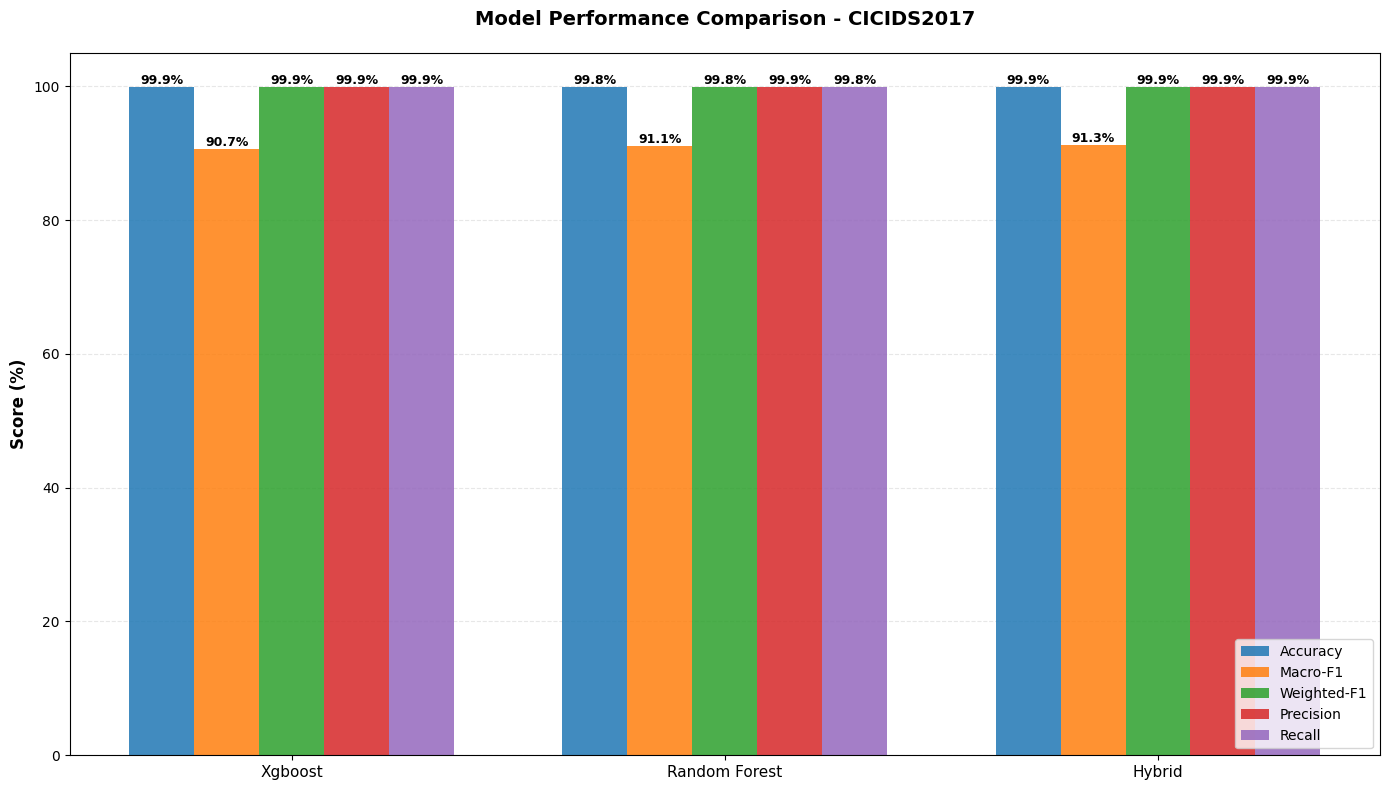

  ✓ Metrics comparison saved → /content/drive/MyDrive/NIDS_Output/results/CICIDS2017/1_metrics_comparison.png


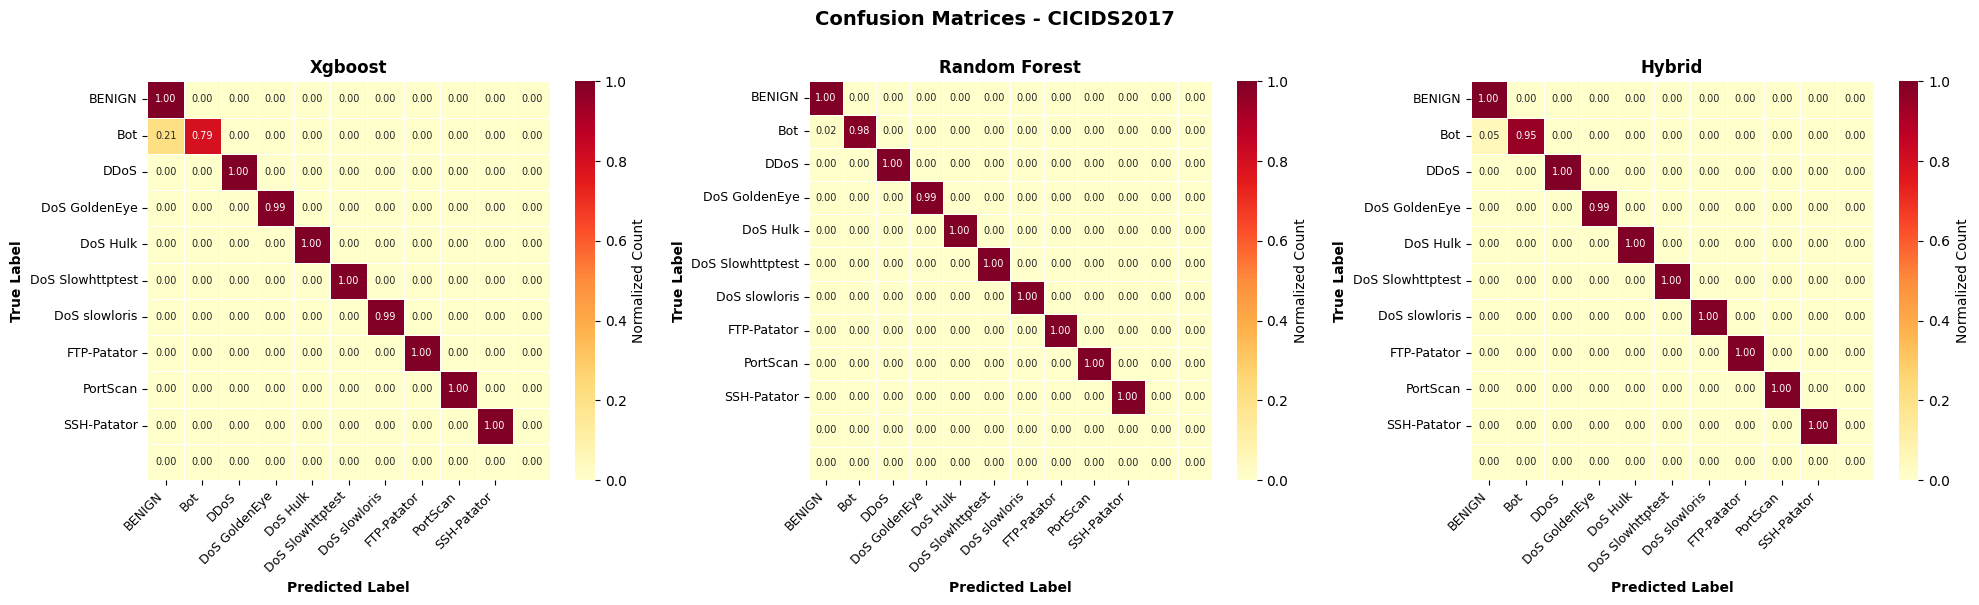

  ✓ Confusion matrices saved → /content/drive/MyDrive/NIDS_Output/results/CICIDS2017/2_confusion_matrices.png


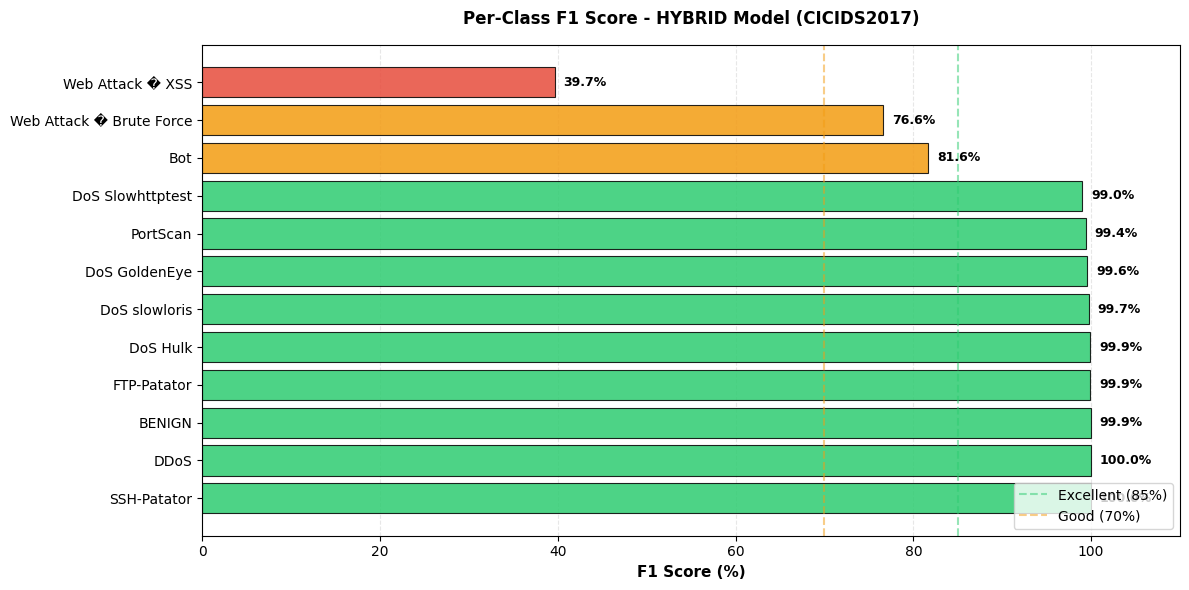

  ✓ Per-class F1 saved → /content/drive/MyDrive/NIDS_Output/results/CICIDS2017/3_per_class_f1.png

[Step 4/5] 🔍 FEATURE IMPORTANCE & SHAP ANALYSIS
────────────────────────────────────────────────────────────────────────────────


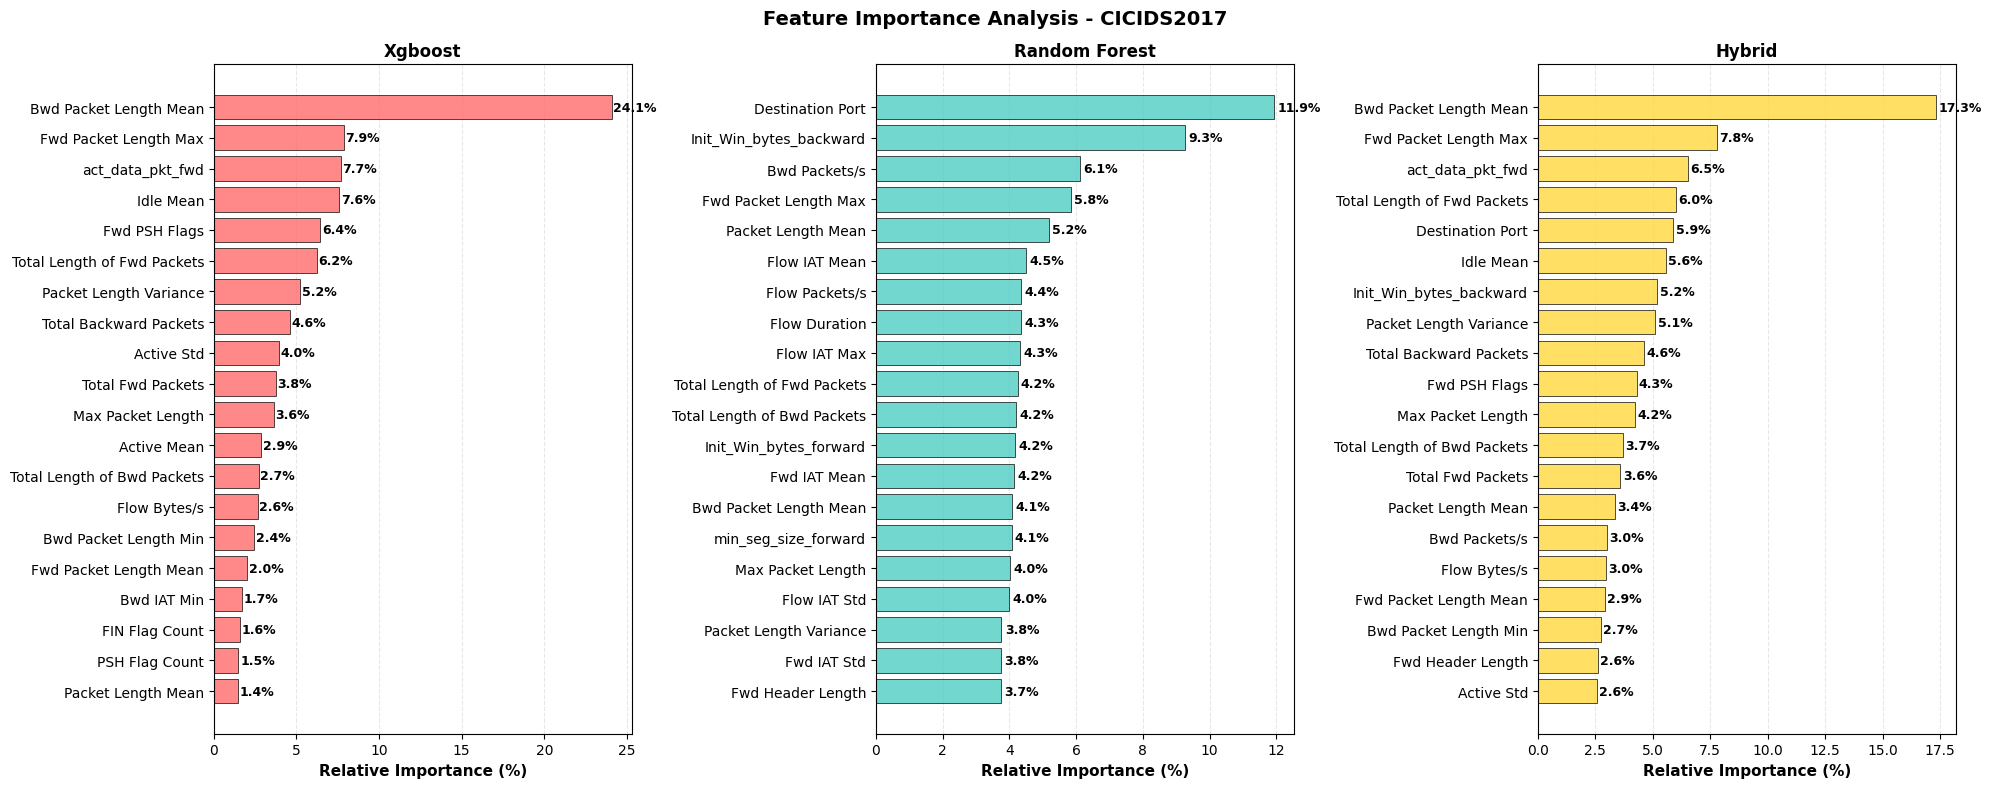

  ✓ Feature importance saved → /content/drive/MyDrive/NIDS_Output/results/CICIDS2017/4_feature_importance.png

  🔍 Running SHAP analysis for XGBoost ...


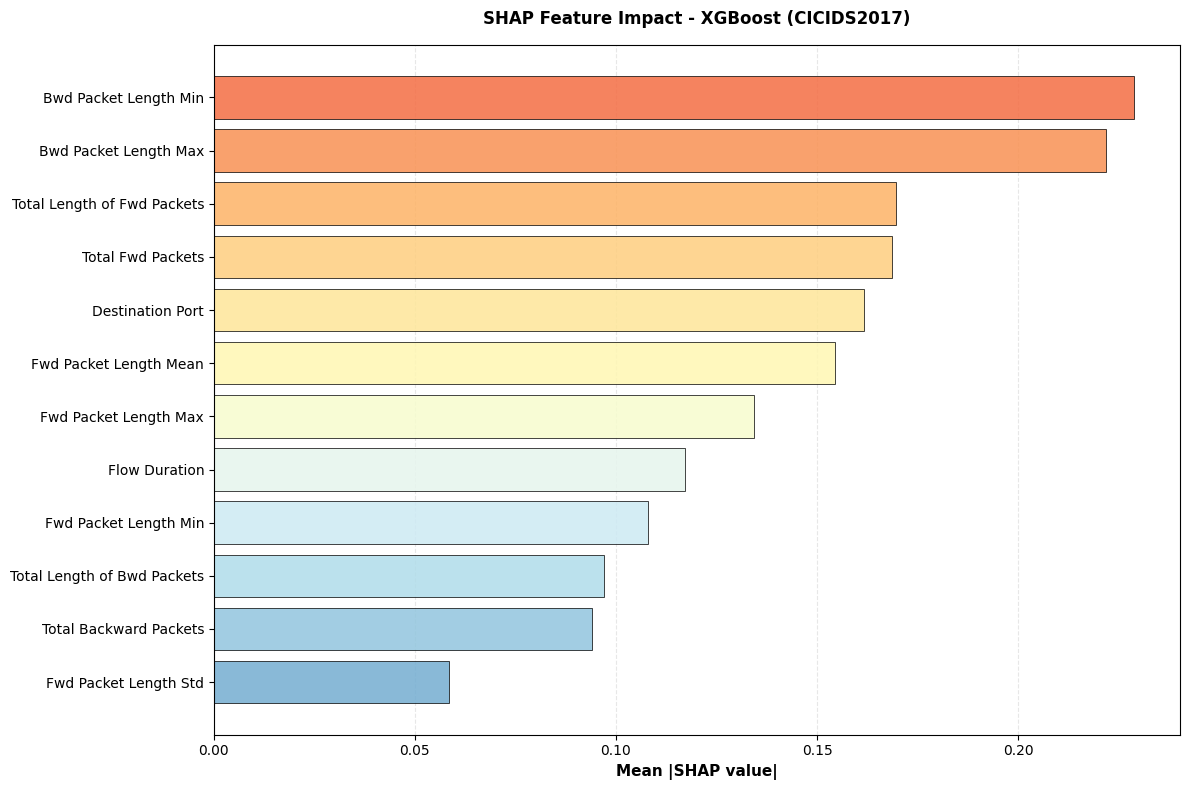

  ✓ SHAP summary saved → /content/drive/MyDrive/NIDS_Output/results/CICIDS2017/5_shap_summary.png

[Step 5/5] 💬 OLLAMA LLM EXPLANATIONS
────────────────────────────────────────────────────────────────────────────────

  ⚠️  Ollama not available — skipping LLM explanations
       1) Install : https://ollama.com
       2) Start   : ollama serve
      3) Pull    : ollama pull qwen3:4b-thinking-2507-q4_K_M

████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                       ✅ PIPELINE COMPLETED SUCCESSFULLY                      ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████

  ⏱️  Execution Time: 232.3 minutes

  📊 Model Rankings:
  ────────────────────────────────────────────────────────────────────────────
  🥇 #1 HYBRID               Accuracy:  99.88%  |  M

In [ ]:
# ── CELL 3: Train + Evaluate CICIDS2017 ─────────────────────────────────────
HOLDOUT_DAY = None        # exclude Friday from training; None = all days
results_cicids = run_nids(
    dataset_name='CICIDS2017',
    quick_test=False,
    n_llm_samples=6
)




████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                 🚀 NETWORK INTRUSION DETECTION SYSTEM PIPELINE                ║
║                               Dataset: UNSW-NB15                             ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████
  📅 Started: 2026-08-19 21:19:20
────────────────────────────────────────────────────────────────────────────────

[Step 1/5] 📊 DATA LOADING & PREPROCESSING
────────────────────────────────────────────────────────────────────────────────

  Loading 8 data file(s) ...
    ✓ NUSW-NB15_features.csv: 49 rows × 4 cols
    ✓ UNSW-NB15_1.csv: 700,000 rows × 49 cols
    ✓ UNSW-NB15_2.csv: 700,000 rows × 49 cols
    ✓ UNSW-NB15_3.csv: 700,000 rows × 49 cols
    ✓ UNSW-NB15_4.csv: 440,043 rows × 49 cols
    ✓ UNSW-NB1

[I 2026-08-19 21:22:00,753] A new study created in memory with name: xgb_UNSW-NB15


  ✓ Preprocessed data cached → /content/drive/MyDrive/NIDS_Output/cache/UNSW-NB15/processed_fixed_full.pkl
  Train : 207,503 samples
  Val   :  13,000 samples  (hybrid weight tuning only)
  Test  :  32,500 samples  (never seen during training)
  Features : 60
  Classes  : 9  →  ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode']

[Step 2/5] 🤖 MODEL TRAINING
────────────────────────────────────────────────────────────────────────────────

  Training on 207,503 samples | 60 features | 9 classes

───────────────────────────────────────────────────────
  [1/3] XGBoost

  [Tuning] XGBoost hyperparameters via Optuna (30 trials, val macro-F1) ...
    Stratified search sample: 100,000 rows from 207,503 training rows
    Searching on a 100,000-row subsample (full train has 207,503 rows) for speed


[I 2026-08-19 21:27:07,245] Trial 0 finished with value: 0.5690833049879604 and parameters: {'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.02904180608409973, 'reg_alpha': 0.8661761457749352, 'reg_lambda': 1.4016725176148133}. Best is trial 0 with value: 0.5690833049879604.
[I 2026-08-19 21:30:15,397] Trial 1 finished with value: 0.5892805110893402 and parameters: {'n_estimators': 800, 'max_depth': 4, 'learning_rate': 0.18276027831785724, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 2, 'gamma': 0.09170225492671691, 'reg_alpha': 0.3042422429595377, 'reg_lambda': 1.2871346474483567}. Best is trial 1 with value: 0.5892805110893402.
[I 2026-08-19 21:33:27,062] Trial 2 finished with value: 0.5922462081391223 and parameters: {'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.06252287916406217, 'subsample'

    ✓ Best val macro-F1 = 60.40%
    ✓ Best params: {'n_estimators': 1000, 'max_depth': 8, 'learning_rate': 0.02288970656729041, 'subsample': 0.9988902865705865, 'colsample_bytree': 0.7874820875551369, 'min_child_weight': 7, 'gamma': 0.3859620061900356, 'reg_alpha': 0.5631266946274767, 'reg_lambda': 1.9870912721935126}
[0]	validation_0-mlogloss:1.75296
[100]	validation_0-mlogloss:0.63140
[200]	validation_0-mlogloss:0.50913
[300]	validation_0-mlogloss:0.47639
[400]	validation_0-mlogloss:0.46174
[500]	validation_0-mlogloss:0.45321
[600]	validation_0-mlogloss:0.44745
[700]	validation_0-mlogloss:0.44317
[800]	validation_0-mlogloss:0.44050
[900]	validation_0-mlogloss:0.43797
[999]	validation_0-mlogloss:0.43652
  ✓ XGBoost trained on CUDA
  ✓ Saved → /content/drive/MyDrive/NIDS_Output/models/UNSW-NB15/xgboost_fixed.pkl

───────────────────────────────────────────────────────
  [2/3] Random Forest

  [Tuning] Random Forest hyperparameters via Optuna (30 trials, val macro-F1) ...


[I 2026-08-19 22:34:56,519] A new study created in memory with name: rf_UNSW-NB15


    Stratified search sample: 100,000 rows from 207,503 training rows
    Searching on a 100,000-row subsample (full train has 207,503 rows) for speed


[I 2026-08-19 22:36:13,497] Trial 0 finished with value: 0.578585684677924 and parameters: {'n_estimators': 250, 'max_depth': 39, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.578585684677924.
[I 2026-08-19 22:36:36,108] Trial 1 finished with value: 0.5676540903624168 and parameters: {'n_estimators': 100, 'max_depth': 36, 'min_samples_split': 13, 'min_samples_leaf': 8, 'max_features': 'log2'}. Best is trial 0 with value: 0.578585684677924.
[I 2026-08-19 22:38:14,546] Trial 2 finished with value: 0.5696632548639228 and parameters: {'n_estimators': 450, 'max_depth': 16, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 0 with value: 0.578585684677924.
[I 2026-08-19 22:39:11,187] Trial 3 finished with value: 0.5743099616504135 and parameters: {'n_estimators': 250, 'max_depth': 19, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 0 with value: 0.578585684677924

    ✓ Best val macro-F1 = 58.55%
    ✓ Best params: {'n_estimators': 450, 'max_depth': 23, 'min_samples_split': 9, 'min_samples_leaf': 4, 'max_features': 'sqrt'}
  ✓ Random Forest trained on CPU (tuned params, class_weight='balanced_subsample')
  ✓ Saved → /content/drive/MyDrive/NIDS_Output/models/UNSW-NB15/random_forest_fixed.pkl

───────────────────────────────────────────────────────
  [3/3] Weighted Hybrid Ensemble
  XGBoost     weight=0.509  (val acc=82.29%  val F1=60.59%)
  Rand Forest weight=0.491  (val acc=77.78%   val F1=58.45%)
  (weights computed on VALIDATION set — test set untouched)
  Hybrid (val)        (acc=81.71%  F1=60.56%)

  ✓ Best hyperparameters saved → /content/drive/MyDrive/NIDS_Output/results/UNSW-NB15/best_hyperparameters.pkl

  ✓ All three models ready

[Step 3/5] 📈 MODEL EVALUATION
────────────────────────────────────────────────────────────────────────────────

████████████████████████████████████████████████████████████████████████████████
║               

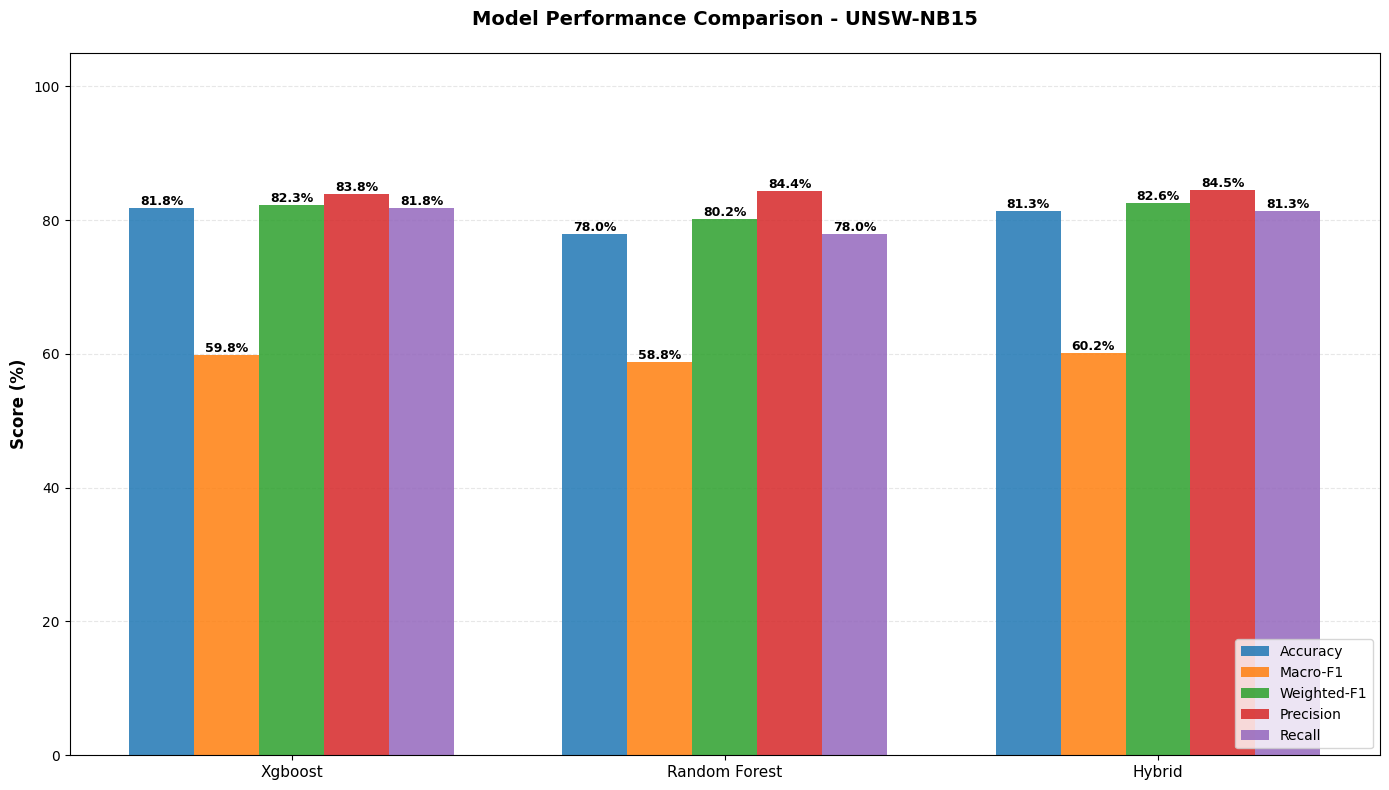

  ✓ Metrics comparison saved → /content/drive/MyDrive/NIDS_Output/results/UNSW-NB15/1_metrics_comparison.png


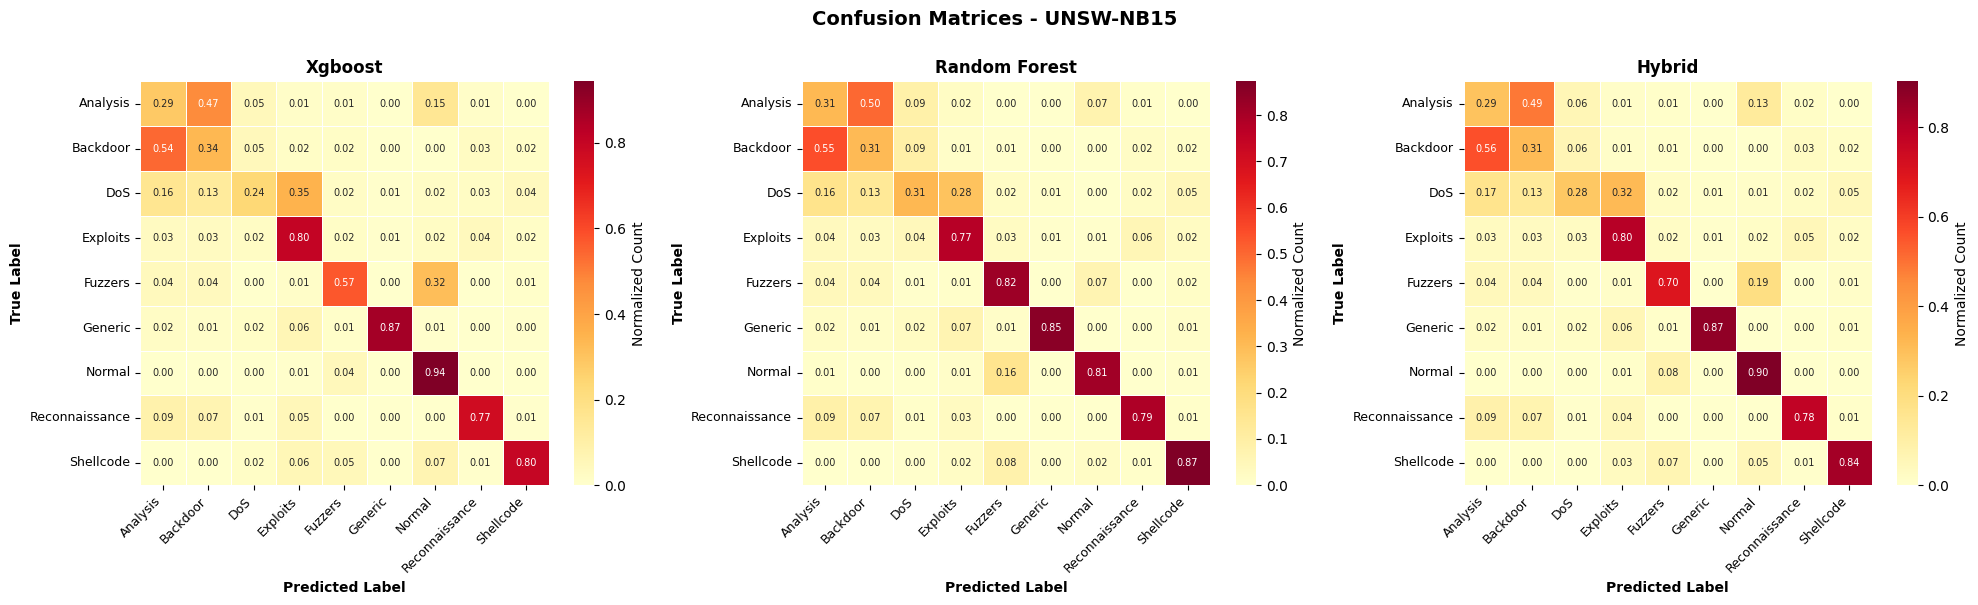

  ✓ Confusion matrices saved → /content/drive/MyDrive/NIDS_Output/results/UNSW-NB15/2_confusion_matrices.png


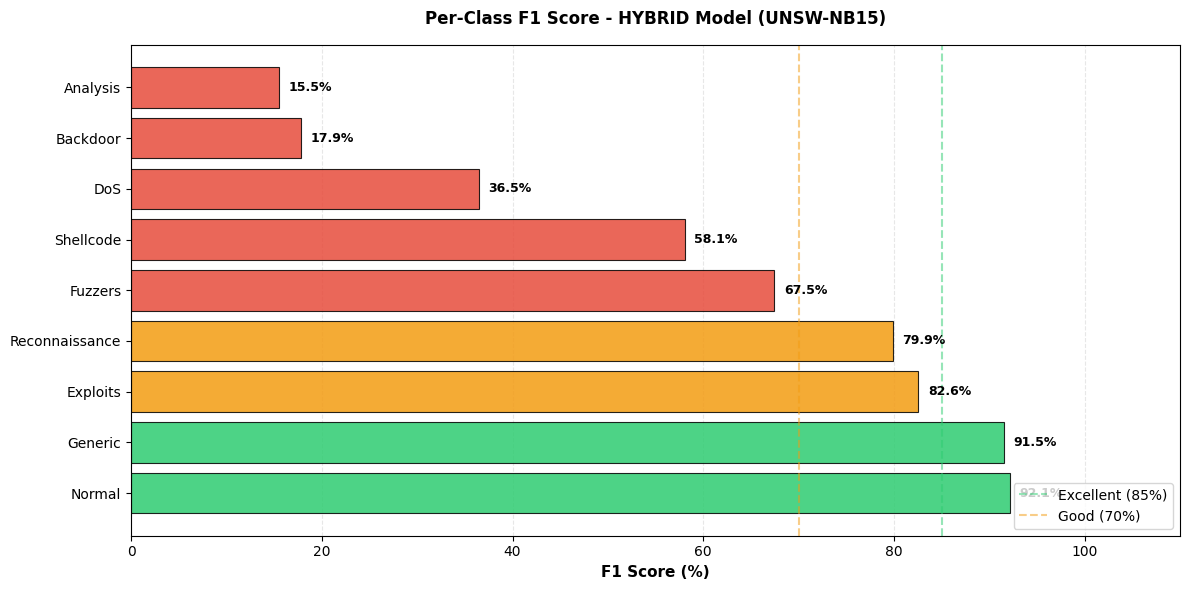

  ✓ Per-class F1 saved → /content/drive/MyDrive/NIDS_Output/results/UNSW-NB15/3_per_class_f1.png

[Step 4/5] 🔍 FEATURE IMPORTANCE & SHAP ANALYSIS
────────────────────────────────────────────────────────────────────────────────


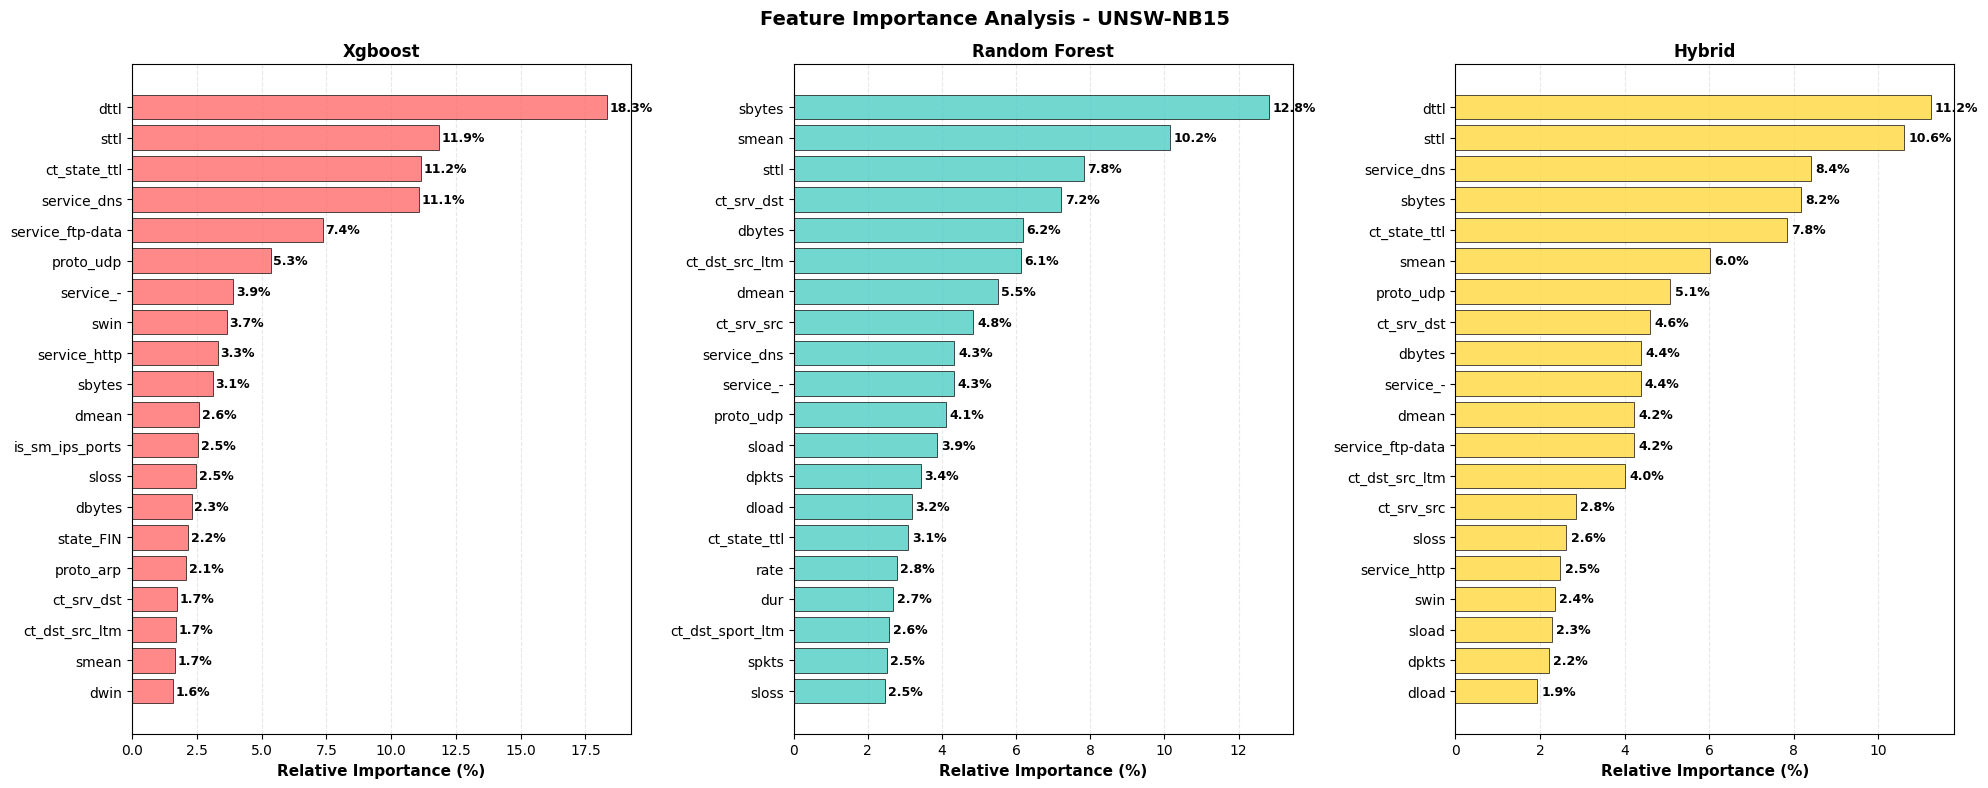

  ✓ Feature importance saved → /content/drive/MyDrive/NIDS_Output/results/UNSW-NB15/4_feature_importance.png

  🔍 Running SHAP analysis for XGBoost ...


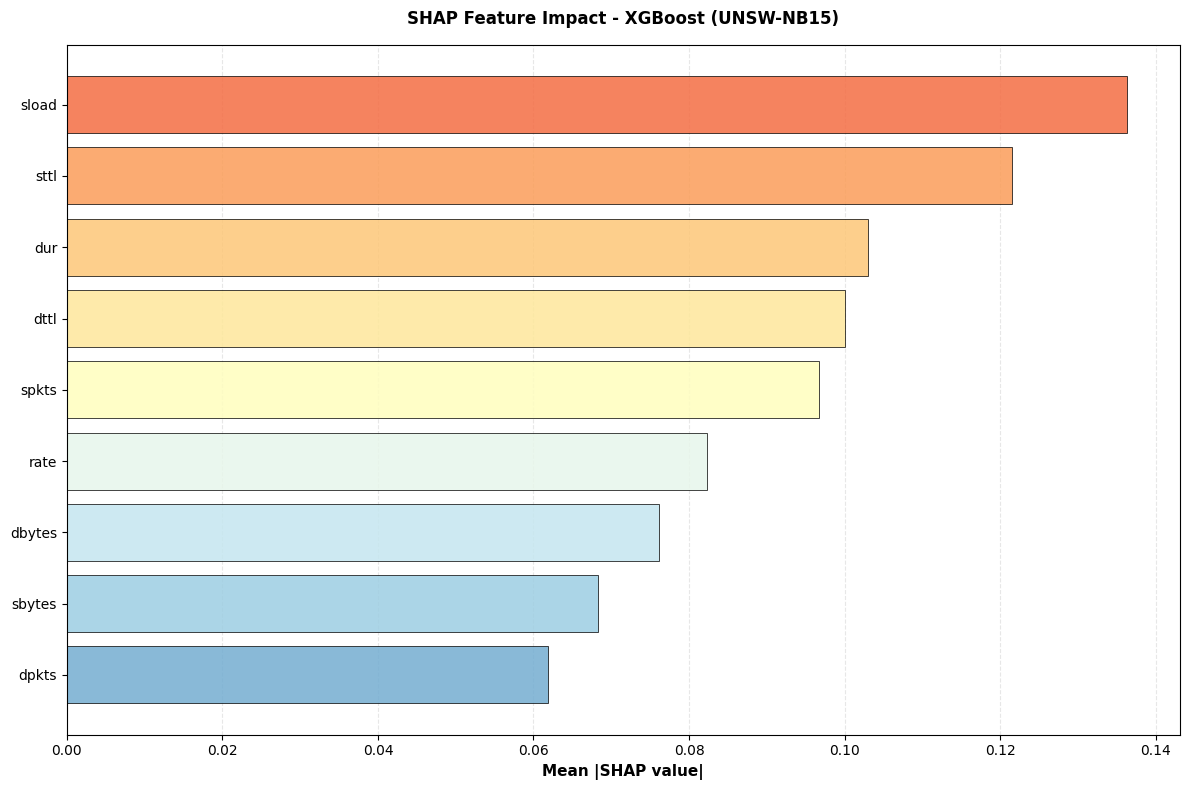

  ✓ SHAP summary saved → /content/drive/MyDrive/NIDS_Output/results/UNSW-NB15/5_shap_summary.png

[Step 5/5] 💬 OLLAMA LLM EXPLANATIONS
────────────────────────────────────────────────────────────────────────────────

  ⚠️  Ollama not available — skipping LLM explanations
       1) Install : https://ollama.com
       2) Start   : ollama serve
      3) Pull    : ollama pull qwen3:4b-thinking-2507-q4_K_M

████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                       ✅ PIPELINE COMPLETED SUCCESSFULLY                      ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████

  ⏱️  Execution Time: 140.1 minutes

  📊 Model Rankings:
  ────────────────────────────────────────────────────────────────────────────
  🥇 #1 HYBRID               Accuracy:  81.34%  |  Ma

In [ ]:
# ── CELL 4: (Optional) Train + Evaluate UNSW-NB15 ──────────────────────────
results_unsw = run_nids(
    dataset_name='UNSW-NB15',
    quick_test=False,
    n_llm_samples=6
)



████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                 🚀 NETWORK INTRUSION DETECTION SYSTEM PIPELINE                ║
║                                Dataset: NSL-KDD                              ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████
  📅 Started: 2026-08-19 23:39:28
────────────────────────────────────────────────────────────────────────────────

[Step 1/5] 📊 DATA LOADING & PREPROCESSING
────────────────────────────────────────────────────────────────────────────────

  Loading 4 data file(s) ...
    ✓ KDDTest+.txt: 22,544 rows × 43 cols
    ✓ KDDTest-21.txt: 11,850 rows × 43 cols
    ✓ KDDTrain+.txt: 125,973 rows × 43 cols
    ✓ KDDTrain+_20Percent.txt: 25,192 rows × 43 cols
  ✓ Combined : 185,559 rows × 43 columns

  Label distribution

[I 2026-08-19 23:40:19,171] A new study created in memory with name: xgb_NSL-KDD


  ✓ Preprocessed data cached → /content/drive/MyDrive/NIDS_Output/cache/NSL-KDD/processed_fixed_full.pkl
  Train : 354,315 samples
  Val   :  11,770 samples  (hybrid weight tuning only)
  Test  :  29,423 samples  (never seen during training)
  Features : 60
  Classes  : 18  →  ['apache2', 'back', 'guess_passwd', 'ipsweep', 'mailbomb', 'mscan', 'neptune', 'nmap', 'normal', 'portsweep', 'processtable', 'saint', 'satan', 'smurf', 'snmpguess', 'teardrop', 'warezclient', 'warezmaster']

[Step 2/5] 🤖 MODEL TRAINING
────────────────────────────────────────────────────────────────────────────────

  Training on 354,315 samples | 60 features | 18 classes

───────────────────────────────────────────────────────
  [1/3] XGBoost

  [Tuning] XGBoost hyperparameters via Optuna (30 trials, val macro-F1) ...
    Stratified search sample: 100,000 rows from 354,315 training rows
    Searching on a 100,000-row subsample (full train has 354,315 rows) for speed


[I 2026-08-19 23:43:07,183] Trial 0 finished with value: 0.9837217901595015 and parameters: {'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.02904180608409973, 'reg_alpha': 0.8661761457749352, 'reg_lambda': 1.4016725176148133}. Best is trial 0 with value: 0.9837217901595015.
[I 2026-08-19 23:46:39,724] Trial 1 finished with value: 0.9825120834348193 and parameters: {'n_estimators': 800, 'max_depth': 4, 'learning_rate': 0.18276027831785724, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 2, 'gamma': 0.09170225492671691, 'reg_alpha': 0.3042422429595377, 'reg_lambda': 1.2871346474483567}. Best is trial 0 with value: 0.9837217901595015.
[I 2026-08-19 23:49:56,574] Trial 2 finished with value: 0.9804977764411894 and parameters: {'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.06252287916406217, 'subsample'

    ✓ Best val macro-F1 = 98.37%
    ✓ Best params: {'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.02904180608409973, 'reg_alpha': 0.8661761457749352, 'reg_lambda': 1.4016725176148133}
[0]	validation_0-mlogloss:1.80410
[100]	validation_0-mlogloss:0.01014
[200]	validation_0-mlogloss:0.00866
[300]	validation_0-mlogloss:0.00862
[400]	validation_0-mlogloss:0.00866
[499]	validation_0-mlogloss:0.00869
  ✓ XGBoost trained on CUDA
  ✓ Saved → /content/drive/MyDrive/NIDS_Output/models/NSL-KDD/xgboost_fixed.pkl

───────────────────────────────────────────────────────
  [2/3] Random Forest

  [Tuning] Random Forest hyperparameters via Optuna (30 trials, val macro-F1) ...


[I 2026-08-20 00:50:37,425] A new study created in memory with name: rf_NSL-KDD


    Stratified search sample: 100,000 rows from 354,315 training rows
    Searching on a 100,000-row subsample (full train has 354,315 rows) for speed


[I 2026-08-20 00:51:18,947] Trial 0 finished with value: 0.9622672738012447 and parameters: {'n_estimators': 250, 'max_depth': 39, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.9622672738012447.
[I 2026-08-20 00:51:32,265] Trial 1 finished with value: 0.9398962818327364 and parameters: {'n_estimators': 100, 'max_depth': 36, 'min_samples_split': 13, 'min_samples_leaf': 8, 'max_features': 'log2'}. Best is trial 0 with value: 0.9622672738012447.
[I 2026-08-20 00:52:32,081] Trial 2 finished with value: 0.9536851149759475 and parameters: {'n_estimators': 450, 'max_depth': 16, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 0 with value: 0.9622672738012447.
[I 2026-08-20 00:53:05,197] Trial 3 finished with value: 0.9651409013776987 and parameters: {'n_estimators': 250, 'max_depth': 19, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 3 with value: 0.96514090137

    ✓ Best val macro-F1 = 97.93%
    ✓ Best params: {'n_estimators': 500, 'max_depth': 34, 'min_samples_split': 8, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
  ✓ Random Forest trained on CPU (tuned params, class_weight='balanced_subsample')
  ✓ Saved → /content/drive/MyDrive/NIDS_Output/models/NSL-KDD/random_forest_fixed.pkl

───────────────────────────────────────────────────────
  [3/3] Weighted Hybrid Ensemble
  XGBoost     weight=0.502  (val acc=99.74%  val F1=98.54%)
  Rand Forest weight=0.498  (val acc=99.60%   val F1=97.87%)
  (weights computed on VALIDATION set — test set untouched)
  Hybrid (val)        (acc=99.71%  F1=98.48%)

  ✓ Best hyperparameters saved → /content/drive/MyDrive/NIDS_Output/results/NSL-KDD/best_hyperparameters.pkl

  ✓ All three models ready

[Step 3/5] 📈 MODEL EVALUATION
────────────────────────────────────────────────────────────────────────────────

████████████████████████████████████████████████████████████████████████████████
║                   

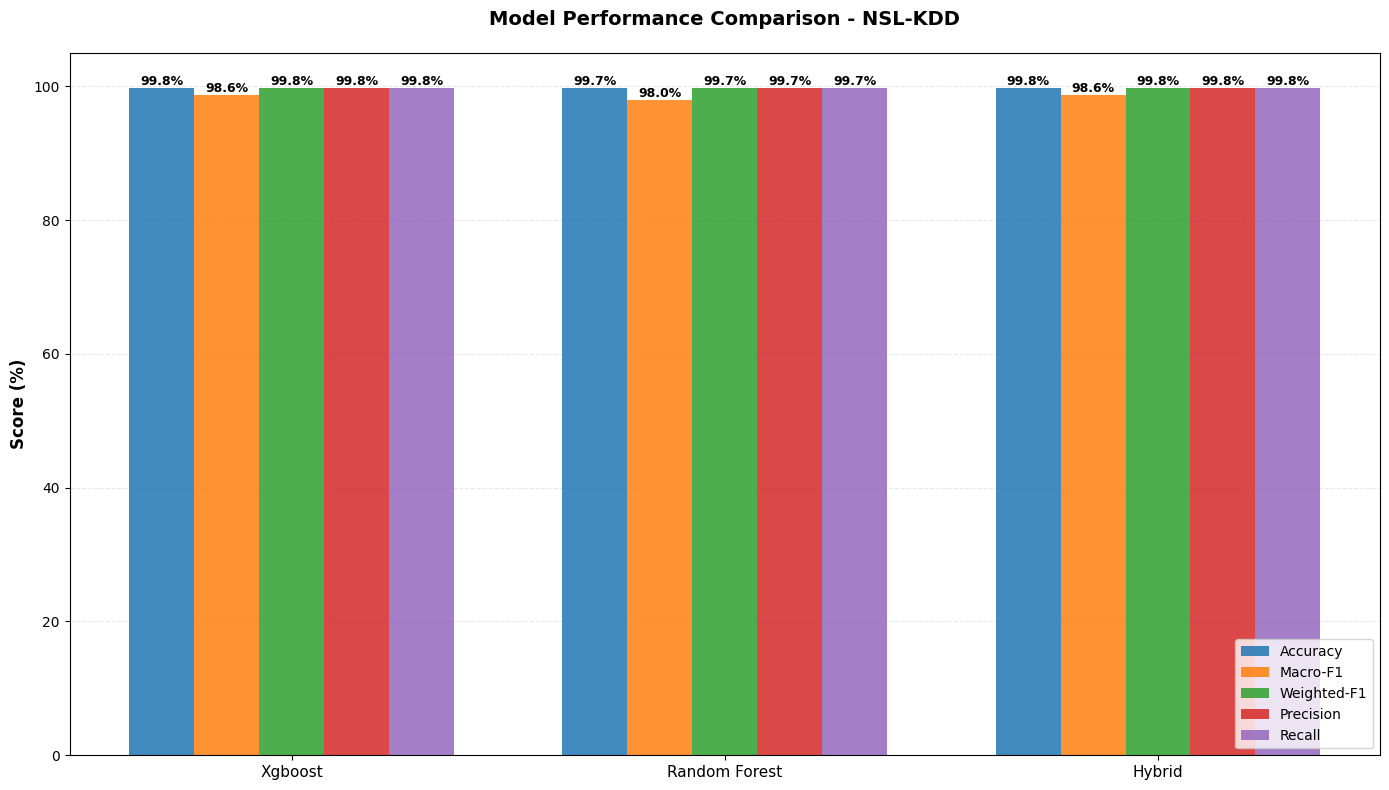

  ✓ Metrics comparison saved → /content/drive/MyDrive/NIDS_Output/results/NSL-KDD/1_metrics_comparison.png


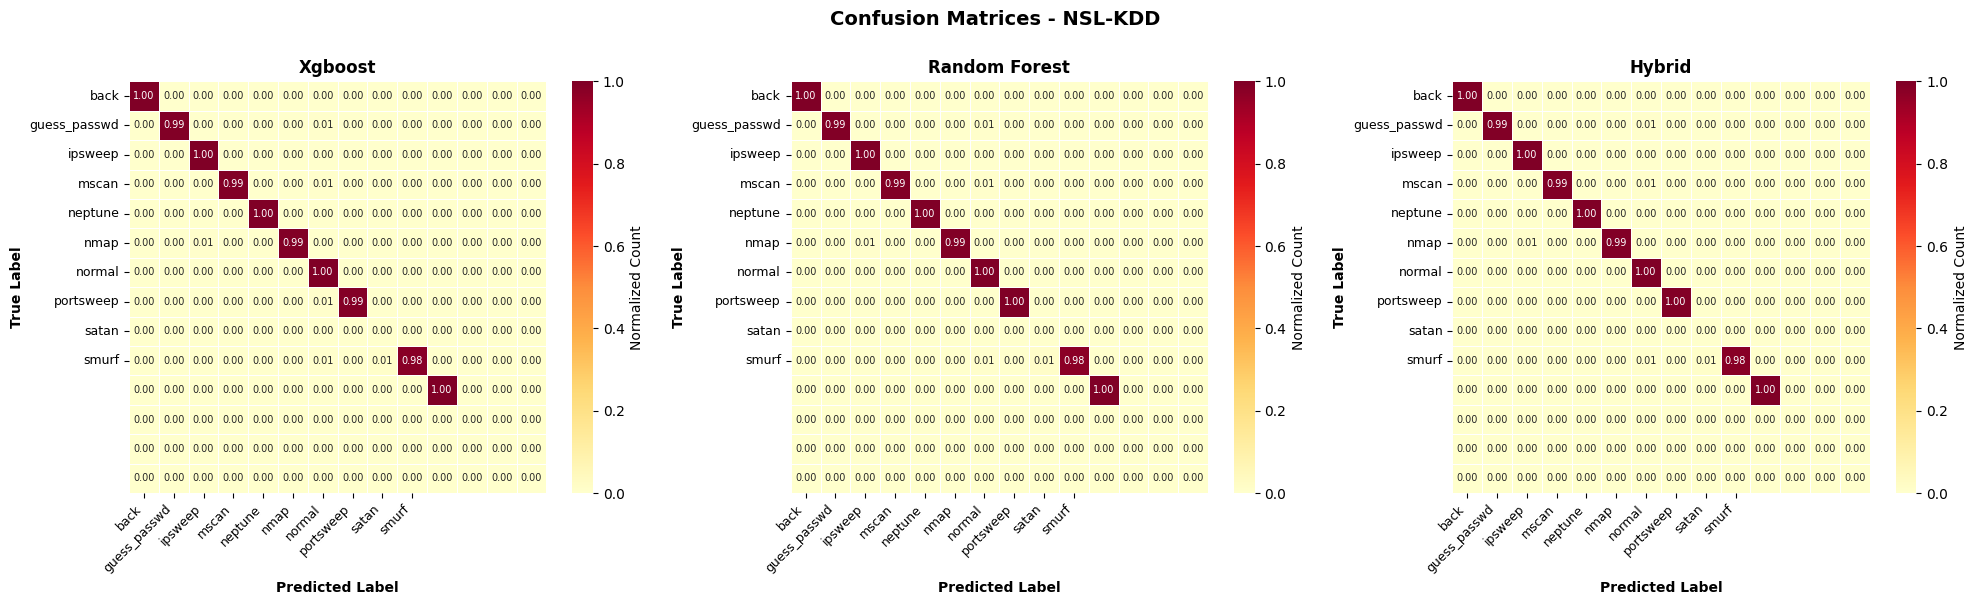

  ✓ Confusion matrices saved → /content/drive/MyDrive/NIDS_Output/results/NSL-KDD/2_confusion_matrices.png


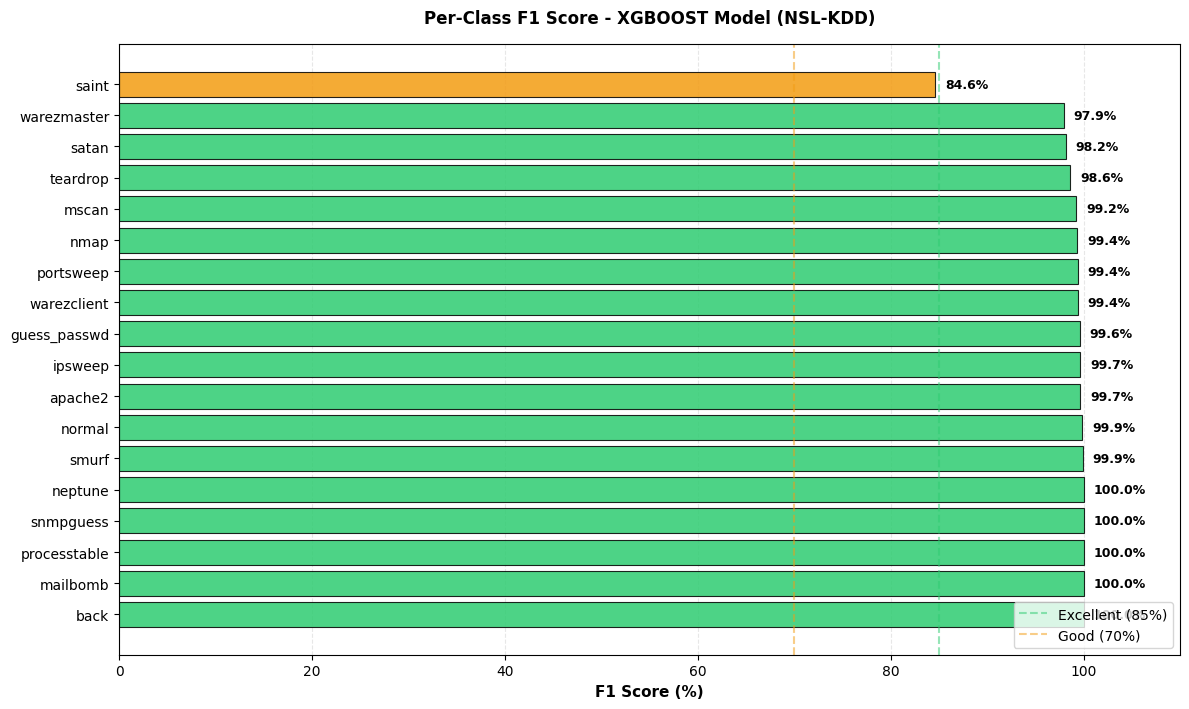

  ✓ Per-class F1 saved → /content/drive/MyDrive/NIDS_Output/results/NSL-KDD/3_per_class_f1.png

[Step 4/5] 🔍 FEATURE IMPORTANCE & SHAP ANALYSIS
────────────────────────────────────────────────────────────────────────────────


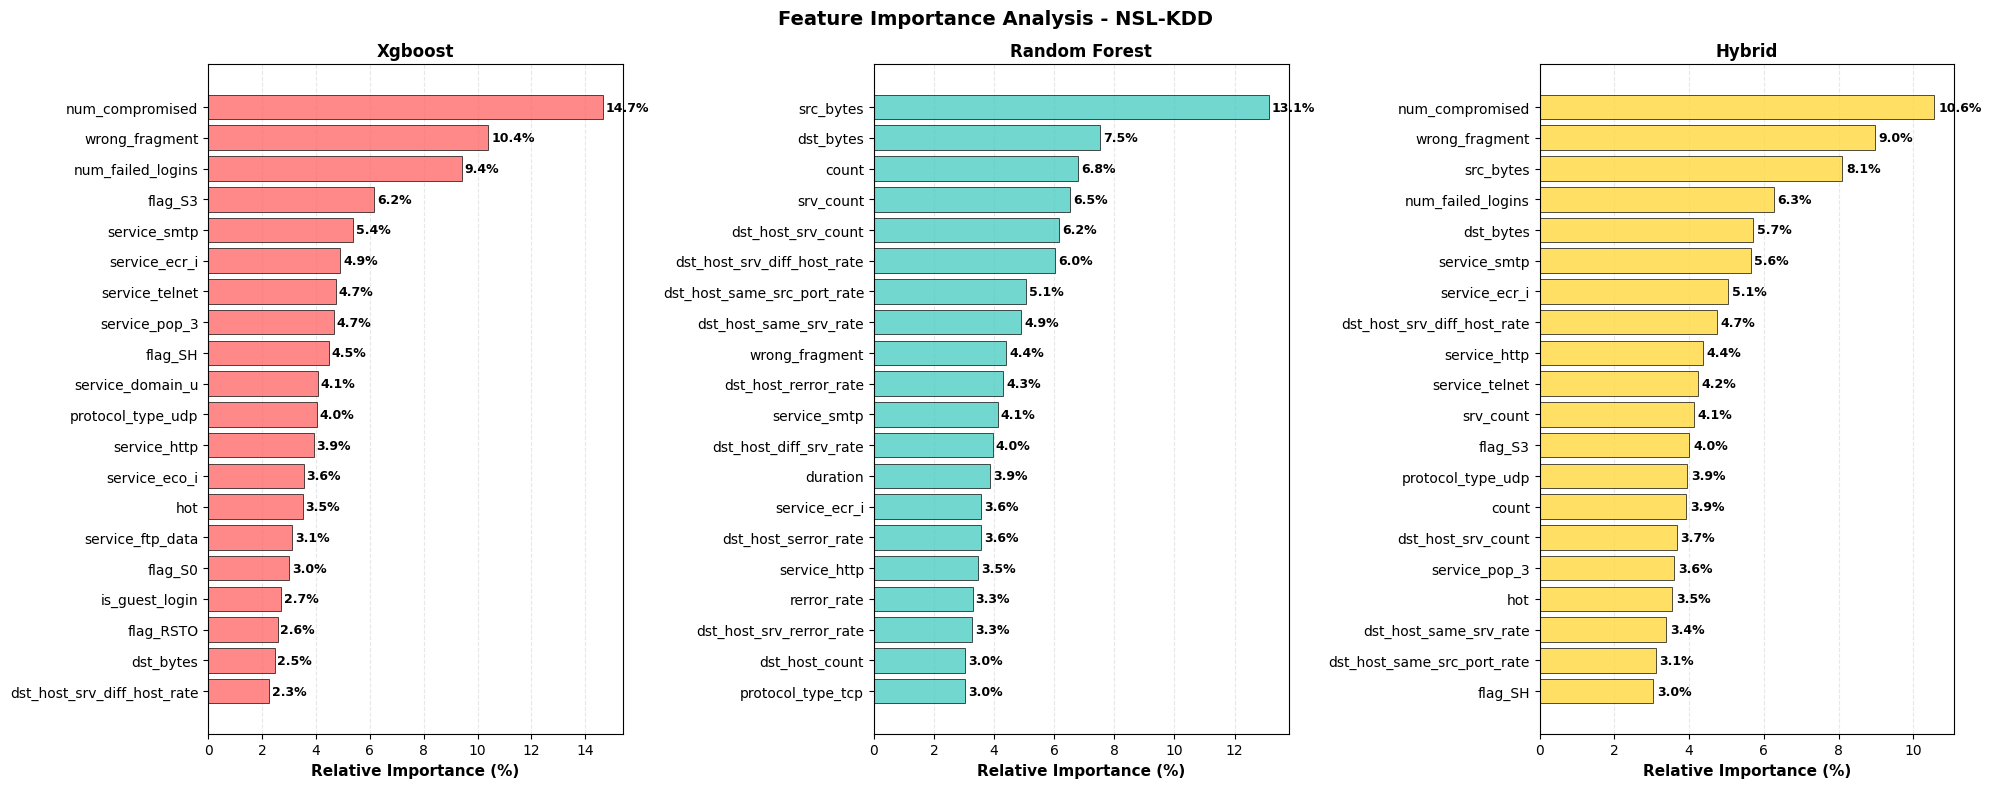

  ✓ Feature importance saved → /content/drive/MyDrive/NIDS_Output/results/NSL-KDD/4_feature_importance.png

  🔍 Running SHAP analysis for XGBoost ...


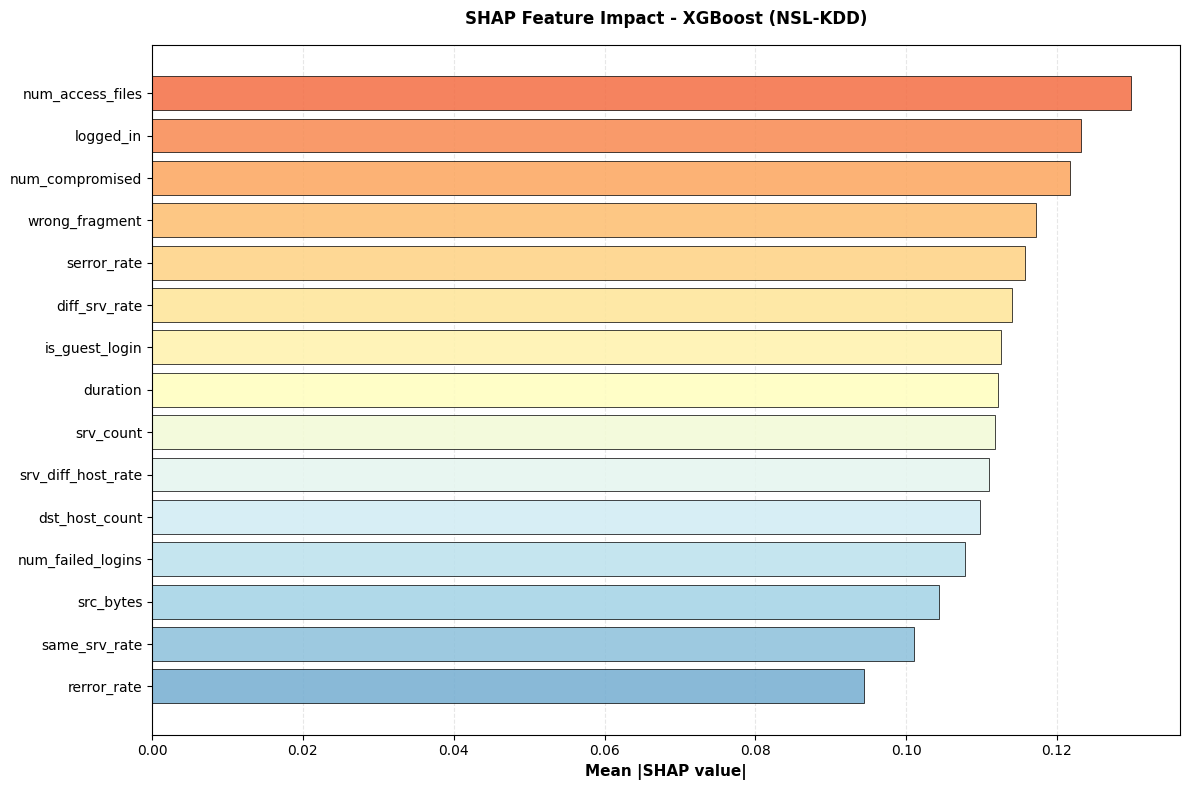

  ✓ SHAP summary saved → /content/drive/MyDrive/NIDS_Output/results/NSL-KDD/5_shap_summary.png

[Step 5/5] 💬 OLLAMA LLM EXPLANATIONS
────────────────────────────────────────────────────────────────────────────────

  ⚠️  Ollama not available — skipping LLM explanations
       1) Install : https://ollama.com
       2) Start   : ollama serve
      3) Pull    : ollama pull qwen3:4b-thinking-2507-q4_K_M

████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                       ✅ PIPELINE COMPLETED SUCCESSFULLY                      ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████

  ⏱️  Execution Time: 105.2 minutes

  📊 Model Rankings:
  ────────────────────────────────────────────────────────────────────────────
  🥇 #1 XGBOOST              Accuracy:  99.78%  |  Macr

In [ ]:
# ── CELL 5: (Optional) Train + Evaluate NSL-KDD ─────────────────────────────
results_nslkdd = run_nids(
    dataset_name='NSL-KDD',
    quick_test=False,
    n_llm_samples=6
)


## Part 3 — Cross-validation (robustness check)

5-fold stratified CV on the pre-SMOTE training split, reported separately from the held-out test metrics above.

In [ ]:
# ── CELL: Cross-Validation (FIXED) ──────────────────────────────────────────
# Fixes applied vs. the previous version:
#   1) Stratified subsampling (plain np.random.choice could starve rare
#      classes below the 5-per-class minimum StratifiedKFold needs, which
#      crashed the cell outright on datasets like CICIDS2017).
#   2) Cloned model is forced onto CPU ("device=cpu") before CV. The trained
#      model may carry device="cuda"; combined with n_jobs>1, cross_validate
#      forks multiple processes that all fight over the same GPU and hang
#      or crash. n_jobs is also capped at 1 for the same reason.
#   3) model_key="hybrid" now actually cross-validates the hybrid ensemble.
#      WeightedHybridEnsemble has no .fit()/get_params(), so sklearn's
#      clone()/cross_validate() can't drive it directly — the old code
#      silently fell back to CV-ing the XGBoost sub-model only. This now
#      refits XGB + RF per fold and recomputes the hybrid weights on an
#      inner split of the training fold, matching how _build_weighted_hybrid
#      works in training.
#   Known caveat (not silently changed): for UNSW-NB15 / NSL-KDD, data["X_train"]
#   is already SMOTE-oversampled (see load_data). Combining it with X_val for CV
#   lets synthetic near-duplicate rows land in different folds than the real
#   sample they were derived from, which inflates those two datasets' CV scores
#   vs. the genuine held-out test metrics printed earlier in the notebook. If you
#   want unbiased CV numbers for those datasets, load_data would need to keep and
#   expose the pre-SMOTE train split for use here instead.

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from collections import Counter
import numpy as np
import json


def _stratified_subsample(X, y, n_samples, random_state=42):
    """Class-proportional subsample. Plain np.random.choice can starve rare
    classes down to a handful of rows, which breaks StratifiedKFold."""
    if len(X) <= n_samples:
        return X, y
    X_sub, _, y_sub, _ = train_test_split(
        X, y, train_size=n_samples, stratify=y, random_state=random_state
    )
    return X_sub, y_sub


def _unwrap_base_estimator(model):
    """Return a plain, freshly-clonable estimator.
    Guards against models cached on disk from an older pipeline version
    (e.g. wrapped in CalibratedClassifierCV). clone() cannot safely re-fit
    a prefit-style calibrated wrapper — it strips the fitted state that
    calibration.fit() requires — so unwrap to the underlying estimator.
    This is a safety net only: if this branch fires, your cached
    xgboost_fixed.pkl / random_forest_fixed.pkl on Drive is stale and
    should be deleted so training actually reruns with current code.
    """
    if hasattr(model, "xgb_model"):
        model = model.xgb_model
    if type(model).__name__ == "CalibratedClassifierCV":
        inner = getattr(model, "estimator", None) or getattr(model, "base_estimator", None)
        if inner is not None:
            print("  ⚠️  Unwrapped a CalibratedClassifierCV — this model came from "
                  "a stale cache. Delete the cached .pkl and retrain for correct numbers.")
            model = inner
    return model


def _drop_too_rare(X, y, n_splits):
    """Drop any class with fewer than n_splits members instead of letting
    StratifiedKFold raise ValueError."""
    counts = Counter(y)
    too_rare = [c for c, n in counts.items() if n < n_splits]
    if too_rare:
        print(f"  ⚠️  Dropping {len(too_rare)} class(es) with <{n_splits} "
              f"samples in the CV subsample (labels: {too_rare})")
        keep = ~np.isin(y, too_rare)
        X, y = X[keep], y[keep]
    return X, y


def _cv_hybrid(models, X_cv, y_cv, skf, dataset_name):
    """Fold-by-fold CV for the hybrid ensemble (can't use clone()/cross_validate
    directly since WeightedHybridEnsemble isn't a proper sklearn estimator)."""
    accs, f1s = [], []
    xgb_base = clone(_unwrap_base_estimator(models["xgboost"]))
    try:
        xgb_base.set_params(device="cpu")
    except Exception:
        pass
    rf_base = clone(_unwrap_base_estimator(models["random_forest"]))

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_cv, y_cv), 1):
        X_tr, X_te = X_cv[tr_idx], X_cv[te_idx]
        y_tr, y_te = y_cv[tr_idx], y_cv[te_idx]

        X_tr_core, X_val_i, y_tr_core, y_val_i = train_test_split(
            X_tr, y_tr, test_size=0.1, stratify=y_tr, random_state=42
        )

        xgb_m = clone(xgb_base).fit(X_tr_core, y_tr_core)
        rf_m = clone(rf_base).fit(X_tr_core, y_tr_core)

        f1_x = f1_score(y_val_i, xgb_m.predict(X_val_i), average="macro", zero_division=0)
        f1_r = f1_score(y_val_i, rf_m.predict(X_val_i), average="macro", zero_division=0)
        total = f1_x + f1_r
        w_x = f1_x / total if total > 0 else 0.5
        w_r = f1_r / total if total > 0 else 0.5

        proba = w_x * xgb_m.predict_proba(X_te) + w_r * rf_m.predict_proba(X_te)
        y_pred = np.argmax(proba, axis=1)

        acc = accuracy_score(y_te, y_pred)
        mf1 = f1_score(y_te, y_pred, average="macro", zero_division=0)
        accs.append(acc)
        f1s.append(mf1)
        print(f"    Fold {fold}: acc={acc:.4f}  macro_f1={mf1:.4f}  (w_xgb={w_x:.2f}, w_rf={w_r:.2f})")

    return {
        "dataset": dataset_name,
        "model": "hybrid",
        "cv_accuracy_mean": float(np.mean(accs)),
        "cv_accuracy_std": float(np.std(accs)),
        "cv_macro_f1_mean": float(np.mean(f1s)),
        "cv_macro_f1_std": float(np.std(f1s)),
        "fold_accuracy": accs,
        "fold_macro_f1": f1s,
    }


def run_and_save_cv(results, dataset_name, model_key="xgboost", n_samples=50000,
                     n_splits=5, cv_n_jobs=1):
    data = results["data"]
    SMOTE_DATASETS = ["UNSW-NB15", "NSL-KDD", "BOT-IOT", "CICIDS2018"]

    if "X_train_pre_smote" in data:
        X_tr_cv, y_tr_cv = data["X_train_pre_smote"], data["y_train_pre_smote"]
        smote_clean = True
    else:
        # cache predates the fix
        X_tr_cv, y_tr_cv = data["X_train"], data["y_train"]
        smote_clean = dataset_name not in SMOTE_DATASETS
        if not smote_clean:
            print(f"  ⚠️  {dataset_name}: no pre-SMOTE split in this cached data. "
                  f"CV will run on SMOTE-augmented rows and the score will be "
                  f"INFLATED by near-duplicate leakage. Do not report it — "
                  f"delete this dataset's cache and retrain.")

    X_cv = np.vstack([X_tr_cv, data["X_val"]])
    y_cv = np.concatenate([y_tr_cv, data["y_val"]])

    X_cv, y_cv = _stratified_subsample(X_cv, y_cv, n_samples)
    X_cv, y_cv = _drop_too_rare(X_cv, y_cv, n_splits)

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    print(f"\n  Running {n_splits}-fold CV for {dataset_name} / {model_key} "
          f"on {len(X_cv):,} samples ...")

    if model_key == "hybrid":
        out = _cv_hybrid(results["models"], X_cv, y_cv, skf, dataset_name)
    else:
        model = results["models"][model_key]
        base = _unwrap_base_estimator(model)
        cv_model = clone(base)
        # Force CPU: the fitted model may carry device="cuda"; parallel folds
        # sharing one GPU across separate processes is what hangs/crashes.
        try:
            cv_model.set_params(device="cpu")
        except Exception:
            pass

        cv = cross_validate(
            cv_model, X_cv, y_cv, cv=skf,
            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
            n_jobs=cv_n_jobs,
        )
        out = {
            "dataset": dataset_name,
            "model": model_key,
            "cv_accuracy_mean": float(cv["test_accuracy"].mean()),
            "cv_accuracy_std": float(cv["test_accuracy"].std()),
            "cv_macro_f1_mean": float(cv["test_macro_f1"].mean()),
            "cv_macro_f1_std": float(cv["test_macro_f1"].std()),
            "fold_accuracy": cv["test_accuracy"].tolist(),
            "fold_macro_f1": cv["test_macro_f1"].tolist(),
        }

    out_path = f"/content/drive/MyDrive/cv_results_{dataset_name}_{model_key}.json"
    with open(out_path, "w") as f:
        json.dump(out, f, indent=2)
    print(f"  ✓ Saved → {out_path}")
    print(out)
    return out


run_and_save_cv(results_cicids, "CICIDS2017", model_key="xgboost")
run_and_save_cv(results_unsw,   "UNSW-NB15",  model_key="xgboost")
run_and_save_cv(results_nslkdd, "NSL-KDD",    model_key="xgboost")

# To cross-validate the actual hybrid ensemble instead (slower, refits per fold):
# run_and_save_cv(results_cicids, "CICIDS2017", model_key="hybrid")




  Running 5-fold CV for CICIDS2017 / xgboost on 50,000 samples ...
  ✓ Saved → /content/drive/MyDrive/cv_results_CICIDS2017_xgboost.json
{'dataset': 'CICIDS2017', 'model': 'xgboost', 'cv_accuracy_mean': 0.99806, 'cv_accuracy_std': 0.0002059126028197173, 'cv_macro_f1_mean': 0.8926034427157223, 'cv_macro_f1_std': 0.023010760278057547, 'fold_accuracy': [0.998, 0.9977, 0.9981, 0.9982, 0.9983], 'fold_macro_f1': [0.8876319037489476, 0.8638512056126636, 0.9176151056314651, 0.9207558683973905, 0.8731631301881446]}

  Running 5-fold CV for UNSW-NB15 / xgboost on 50,000 samples ...
  ✓ Saved → /content/drive/MyDrive/cv_results_UNSW-NB15_xgboost.json
{'dataset': 'UNSW-NB15', 'model': 'xgboost', 'cv_accuracy_mean': 0.81714, 'cv_accuracy_std': 0.0023904811231214656, 'cv_macro_f1_mean': 0.5768215514499875, 'cv_macro_f1_std': 0.008224113418889501, 'fold_accuracy': [0.8182, 0.8187, 0.8127, 0.8194, 0.8167], 'fold_macro_f1': [0.588163717240202, 0.5643995263518027, 0.5755868741856447, 0.5830298497084256

{'dataset': 'NSL-KDD',
 'model': 'xgboost',
 'cv_accuracy_mean': 0.99606,
 'cv_accuracy_std': 0.0004543126676640139,
 'cv_macro_f1_mean': 0.975996305521989,
 'cv_macro_f1_std': 0.0047741933262488165,
 'fold_accuracy': [0.9964, 0.996, 0.9952, 0.9964, 0.9963],
 'fold_macro_f1': [0.9694590448111737,
  0.9748308537309396,
  0.9735150740585097,
  0.9835231991854931,
  0.9786533558238286]}

In [ ]:
run_and_save_cv(results_cicids, "CICIDS2017", model_key="hybrid")
run_and_save_cv(results_unsw, "UNSW-NB15", model_key="hybrid")
run_and_save_cv(results_nslkdd, "NSL-KDD", model_key="hybrid")


  Running 5-fold CV for CICIDS2017 / hybrid on 50,000 samples ...
    Fold 1: acc=0.9981  macro_f1=0.8878  (w_xgb=0.50, w_rf=0.50)
    Fold 2: acc=0.9980  macro_f1=0.9161  (w_xgb=0.52, w_rf=0.48)
    Fold 3: acc=0.9979  macro_f1=0.9154  (w_xgb=0.51, w_rf=0.49)
    Fold 4: acc=0.9979  macro_f1=0.9019  (w_xgb=0.51, w_rf=0.49)
    Fold 5: acc=0.9981  macro_f1=0.8671  (w_xgb=0.50, w_rf=0.50)
  ✓ Saved → /content/drive/MyDrive/cv_results_CICIDS2017_hybrid.json
{'dataset': 'CICIDS2017', 'model': 'hybrid', 'cv_accuracy_mean': 0.998, 'cv_accuracy_std': 8.944271909998174e-05, 'cv_macro_f1_mean': 0.8976540372966179, 'cv_macro_f1_std': 0.01845971916179756, 'fold_accuracy': [0.9981, 0.998, 0.9979, 0.9979, 0.9981], 'fold_macro_f1': [0.8878094652668741, 0.9160649242275459, 0.9154102432865417, 0.9019026791690251, 0.8670828745331022]}

  Running 5-fold CV for UNSW-NB15 / hybrid on 50,000 samples ...
    Fold 1: acc=0.8095  macro_f1=0.6007  (w_xgb=0.49, w_rf=0.51)
    Fold 2: acc=0.8117  macro_f1=0.59

{'dataset': 'NSL-KDD',
 'model': 'hybrid',
 'cv_accuracy_mean': 0.99602,
 'cv_accuracy_std': 0.00036551333764994477,
 'cv_macro_f1_mean': 0.9759080128313748,
 'cv_macro_f1_std': 0.005121084390402596,
 'fold_accuracy': [0.9963, 0.9961, 0.9953, 0.9962, 0.9962],
 'fold_macro_f1': [0.9667362261796681,
  0.9767570338784736,
  0.9780414545080249,
  0.9823627031296852,
  0.9756426464610217]}

## Part 4 — Universal multi-dataset model

Schema-routed ensemble (one sub-model per dataset, routed by feature-name coverage at inference time) — this is the artefact `main_unified.py` and `nids_web.py` load for offline evaluation and real-time detection.

In [ ]:
# ── CELL 9: Train Universal Multi-Dataset Model ──────────────────────────────
# Run AFTER Cells 3, 4, and 5 have completed (CICIDS2017 + UNSW-NB15 + NSL-KDD).
#
# IMPORTANT: Cell 1 automatically adds nids_role3_clean to sys.path and
# imports UniversalEnsemble from src.engine.universal_ensemble.
# This means the saved pkl will use the portable class path:
#   src.engine.universal_ensemble.UniversalEnsemble
# instead of __main__.UniversalEnsemble (which only works in this notebook).

# ── Verify class paths before training ───────────────────────────────────────
print("Verifying class paths (must NOT be __main__) ...")

whe_module = WeightedHybridEnsemble.__module__
ue_module  = UniversalEnsemble.__module__

print(f"  WeightedHybridEnsemble : {whe_module}")
print(f"  UniversalEnsemble      : {ue_module}")

if "__main__" in whe_module:
    print("  ❌ WeightedHybridEnsemble is __main__ — pkl will fail on load!")
    print("     Fix: check NIDS_PROJECT_PATH at top of Cell 1 and re-run Cell 1.")
    raise RuntimeError("Bad class path for WeightedHybridEnsemble")

if "__main__" in ue_module:
    print("  ❌ UniversalEnsemble is __main__ — pkl will fail on load!")
    print("     Fix: check NIDS_PROJECT_PATH at top of Cell 1 and re-run Cell 1.")
    raise RuntimeError("Bad class path for UniversalEnsemble")

print("  ✓ Both class paths are portable — pkl will load correctly\n")

# ── Collect available dataset results ────────────────────────────────────────
available_results = {}

try:
    available_results["CICIDS2017"] = results_cicids
    print("✓ CICIDS2017 added")
except NameError:
    print("⚠  results_cicids not found — run Cell 3 first")

try:
    available_results["UNSW-NB15"] = results_unsw
    print("✓ UNSW-NB15 added")
except NameError:
    print("⚠  results_unsw not found — run Cell 4 first")

try:
    available_results["NSL-KDD"] = results_nslkdd
    print("✓ NSL-KDD added")
except NameError:
    print("⚠  results_nslkdd not found — run Cell 5 first")

if len(available_results) < 1:
    print("❌ No datasets available. Run at least one run_nids() cell first.")
else:
    print(f"\nTraining universal model on: {list(available_results.keys())}")
    universal_out = train_universal_model(available_results)

    # Save to Google Drive
    save_universal_output(
        universal_out,
        filename="universal_nids_output.pkl",
        drive_path="/content/drive/MyDrive/",
    )

    # Final verification: reload and check class path
    import joblib, tempfile, os
    print("\nVerifying saved pkl is loadable ...")
    with tempfile.NamedTemporaryFile(suffix=".pkl", delete=False) as tmp:
        tmp_path = tmp.name
    joblib.dump(universal_out["ensemble"], tmp_path)
    loaded = joblib.load(tmp_path)
    os.unlink(tmp_path)
    saved_path = type(loaded).__module__ + "." + type(loaded).__name__
    print(f"  pkl class path: {saved_path}")
    if "universal_ensemble" in saved_path:
        print("  ✓ pkl is portable — main_unified.py will load it correctly")
    else:
        print("  ❌ pkl class path is wrong — see NIDS_PROJECT_PATH at top of Cell 1")


Verifying class paths (must NOT be __main__) ...
  WeightedHybridEnsemble : src.engine.weighted_hybrid
  UniversalEnsemble      : src.engine.universal_ensemble
  ✓ Both class paths are portable — pkl will load correctly

✓ CICIDS2017 added
✓ UNSW-NB15 added
✓ NSL-KDD added

Training universal model on: ['CICIDS2017', 'UNSW-NB15', 'NSL-KDD']

████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                       🌍 UNIVERSAL MULTI-DATASET ENSEMBLE                     ║
║                    Datasets: CICIDS2017, UNSW-NB15, NSL-KDD                  ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████

[1/4] Collecting per-dataset sub-models ...
  CICIDS2017  : model=hybrid  val-F1=90.72%  features=52  classes=12
    Original → Universal: {'BENIGN': 'Benign', 'Bot': 'B


████████████████████████████████████████████████████████████████████████████████
║                                                                              ║
║                           📊 MULTI-DATASET COMPARISON                         ║
║                                                                              ║
████████████████████████████████████████████████████████████████████████████████

   Dataset         Model  Accuracy (%)  Macro-F1 (%)  Weighted-F1 (%)  N_Classes  N_Features  Train_Samples
CICIDS2017       Xgboost         99.88         90.66            99.88         12          52        1815562
CICIDS2017 Random Forest         99.82         91.07            99.83         12          52        1815562
CICIDS2017        Hybrid         99.88         91.28            99.88         12          52        1815562
 UNSW-NB15       Xgboost         81.79         59.83            82.32          9          60         207503
 UNSW-NB15 Random Forest         77.96         58.76 

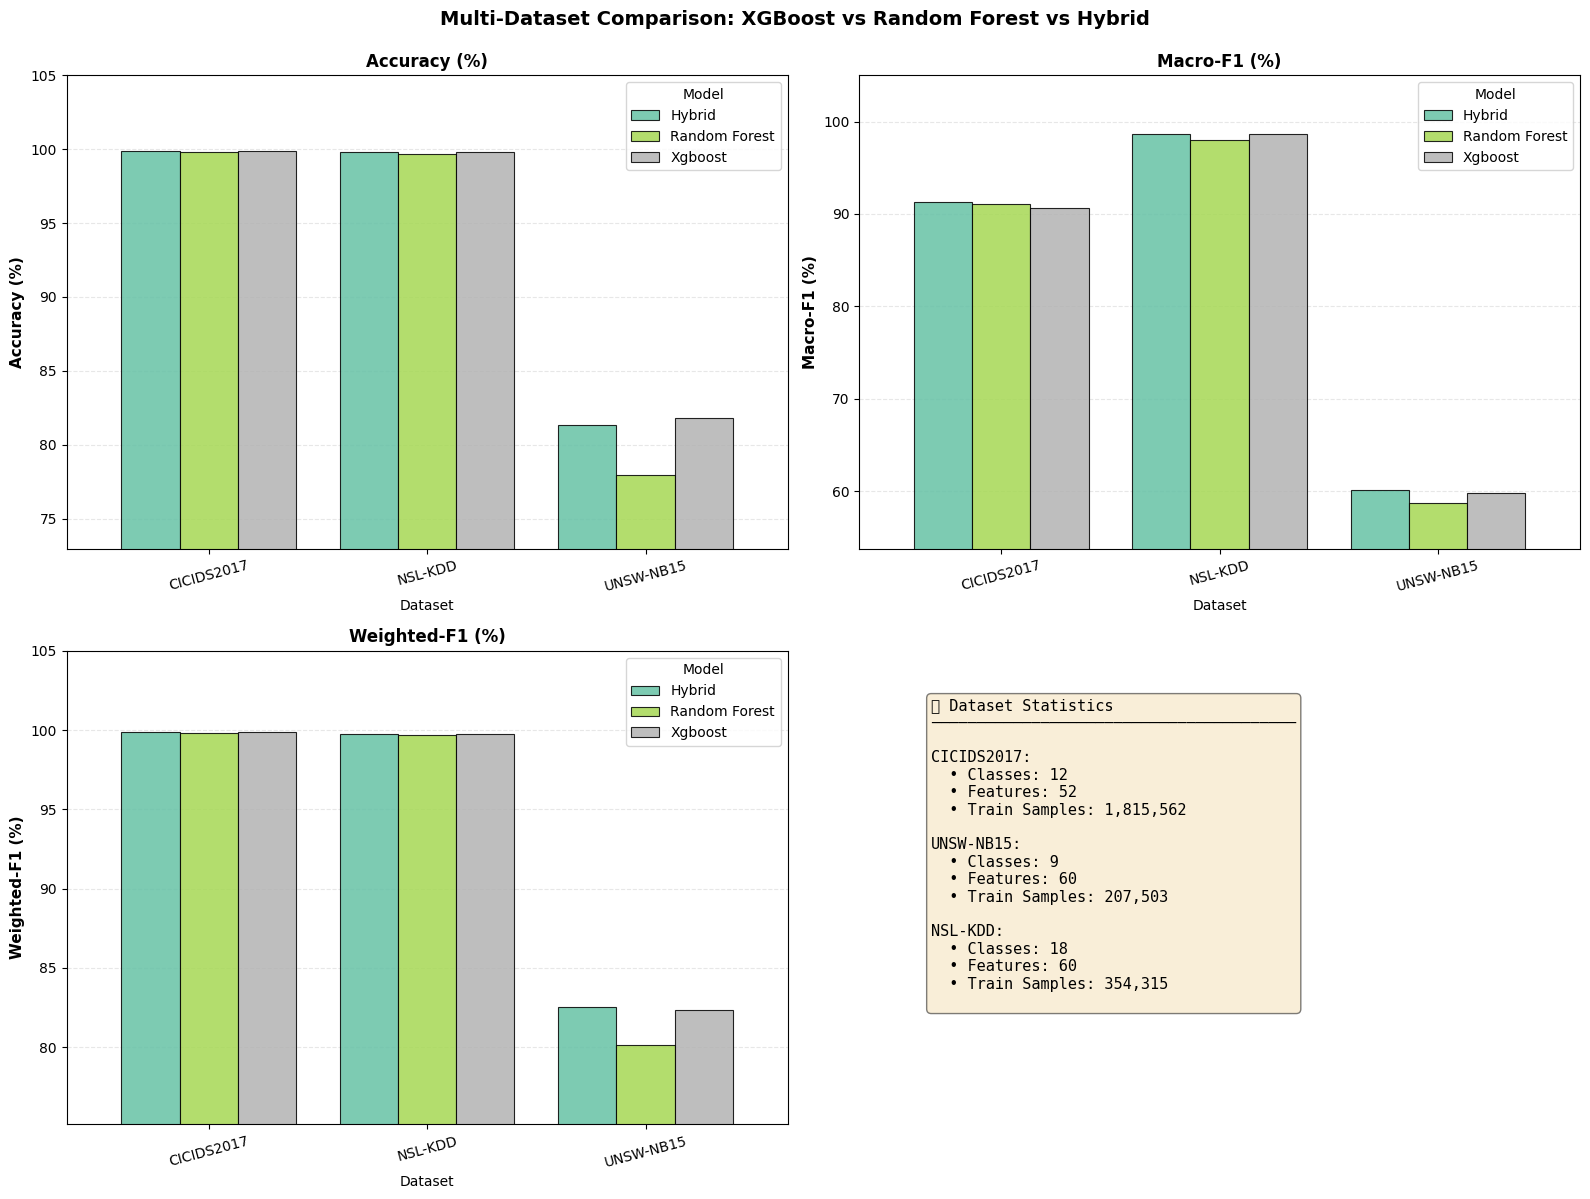


  ✓ Comparison chart saved → /content/drive/MyDrive/NIDS_Output/comparisons/multi_dataset_comparison.png
████████████████████████████████████████████████████████████████████████████████

   Dataset         Model  Accuracy (%)  Macro-F1 (%)  Weighted-F1 (%)  N_Classes  N_Features  Train_Samples
CICIDS2017       Xgboost         99.88         90.66            99.88         12          52        1815562
CICIDS2017 Random Forest         99.82         91.07            99.83         12          52        1815562
CICIDS2017        Hybrid         99.88         91.28            99.88         12          52        1815562
 UNSW-NB15       Xgboost         81.79         59.83            82.32          9          60         207503
 UNSW-NB15 Random Forest         77.96         58.76            80.15          9          60         207503
 UNSW-NB15        Hybrid         81.34         60.16            82.55          9          60         207503
   NSL-KDD       Xgboost         99.78         98.64    

In [ ]:
# ── CELL 7: Compare datasets (run after at least Cell 3) ───────────────────
comparison_df = compare_datasets({
    'CICIDS2017': results_cicids,
    'UNSW-NB15':  results_unsw,
    'NSL-KDD':    results_nslkdd,
})
print(comparison_df.to_string(index=False))

In [ ]:
# ── CELL: Save individual dataset outputs (pickle-safe) ──────────────────────
# Also save the individual CICIDS2017 output for per-dataset use.
# Use this if you want to run main_unified.py with one dataset only.

import joblib, os

def save_nids_output(results, filename="nids_v3_output.pkl",
                     drive_path="/content/drive/MyDrive/"):
    """Save NIDS pipeline output — excludes config (not picklable)."""
    safe = {
        "models": results["models"],
        "data": {
            "X_train":       results["data"]["X_train"],
            "X_val":         results["data"]["X_val"],
            "X_test":        results["data"]["X_test"],
            "y_train":       results["data"]["y_train"],
            "y_val":         results["data"]["y_val"],
            "y_test":        results["data"]["y_test"],
            "feature_names": results["data"]["feature_names"],
            "label_encoder": results["data"]["label_encoder"],
            "scaler":        results["data"]["scaler"],
            "dataset":       results["data"]["dataset"],
            "n_classes":     results["data"]["n_classes"],
        },
        "results": {
            k: {mk: mv for mk, mv in v.items() if mk != "y_pred"}
            for k, v in results["results"].items()
            if isinstance(v, dict)
        },
    }
    save_path = os.path.join(drive_path, filename)
    joblib.dump(safe, save_path, compress=3)
    print(f"✓ Saved: {save_path}  ({os.path.getsize(save_path)/1e6:.1f} MB)")
    print(f"  Models  : {list(safe['models'].keys())}")
    print(f"  Features: {len(safe['data']['feature_names'])}")
    print(f"  Classes : {list(safe['data']['label_encoder'].classes_)}")
    return save_path

# Save individual dataset outputs
try:
    save_nids_output(results_cicids,  "nids_cicids_output.pkl")
except NameError:
    print("⚠  results_cicids not available")

try:
    save_nids_output(results_unsw,    "nids_unsw_output.pkl")
except NameError:
    print("⚠  results_unsw not available")

try:
    save_nids_output(results_nslkdd,  "nids_nslkdd_output.pkl")
except NameError:
    print("⚠  results_nslkdd not available")


✓ Saved: /content/drive/MyDrive/nids_cicids_output.pkl  (259.3 MB)
  Models  : ['xgboost', 'random_forest', 'hybrid']
  Features: 52
  Classes : ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � XSS']
✓ Saved: /content/drive/MyDrive/nids_unsw_output.pkl  (293.0 MB)
  Models  : ['xgboost', 'random_forest', 'hybrid']
  Features: 60
  Classes : ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode']
✓ Saved: /content/drive/MyDrive/nids_nslkdd_output.pkl  (67.1 MB)
  Models  : ['xgboost', 'random_forest', 'hybrid']
  Features: 60
  Classes : ['apache2', 'back', 'guess_passwd', 'ipsweep', 'mailbomb', 'mscan', 'neptune', 'nmap', 'normal', 'portsweep', 'processtable', 'saint', 'satan', 'smurf', 'snmpguess', 'teardrop', 'warezclient', 'warezmaster']


## Part 5 — Environment setup for offline evaluation (Track A / Track B)

Consolidated: Drive mount, Ollama install + serve, project chdir, and the `UniversalEnsemble` import needed before `joblib.load()` — all together and run **before** any cell below that depends on them (previously `drive.mount` ran after cells that already used Drive paths).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!sudo apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh

import os
os.environ["OLLAMA_NUM_PARALLEL"] = "4"
!nohup ollama serve > /content/ollama.log 2>&1 &
!sleep 5 && ollama pull qwen2.5:1.5b

# Change working directory to the project root FIRST — everything below uses
# paths relative to nids_role3/.
os.chdir('/content/drive/MyDrive/NIDS_Output/nids_role3')

!pip install -q xgboost

import sys
sys.path.insert(0, '/content/drive/MyDrive/NIDS_Output/')
from src.engine.universal_ensemble import UniversalEnsemble


Mounted at /content/drive
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 67 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (9,612 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package zstd.
(Reading database ... 122492 files

## Part 6 — Track A: per-dataset offline evaluation

In [ ]:
!python /content/drive/MyDrive/NIDS_Output/nids_role3/scripts/run_track_a.py \
    --universal_pkl /content/drive/MyDrive/universal_nids_output.pkl \
    --cicids_pkl    /content/drive/MyDrive/nids_cicids_output.pkl \
    --unsw_pkl      /content/drive/MyDrive/nids_unsw_output.pkl\
    --nslkdd_pkl    /content/drive/MyDrive/nids_nslkdd_output.pkl \
    --out           /content/drive/MyDrive/NIDS_Output/nids_role3/data/results/track_a

  (pickle compat: registered NIDSConfig, WeightedHybridEnsemble into __main__)
  TRACK A — universal model across all available datasets
  loading universal model: /content/drive/MyDrive/universal_nids_output.pkl

UniversalEnsemble (schema-routed, one sub-model per dataset)
  CICIDS2017   features=52   classes=12  val-F1-weight=0.363 scaler=yes
  UNSW-NB15    features=60   classes=9   val-F1-weight=0.243 scaler=yes
  NSL-KDD      features=60   classes=18  val-F1-weight=0.394 scaler=yes

  Loading per-dataset test splits ...
  loading CICIDS2017: /content/drive/MyDrive/nids_cicids_output.pkl
  loading UNSW-NB15: /content/drive/MyDrive/nids_unsw_output.pkl
  loading NSL-KDD: /content/drive/MyDrive/nids_nslkdd_output.pkl

  ── CICIDS2017 ──────────────────────────────────────────────────
    n_test=504,324  accuracy=99.91%  macro-F1=97.14%  weighted-F1=99.91%
    binary attack detection: F1 99.73% (95% CI 99.71-99.76)
                          Recall 99.94% (95% CI 99.92-99.96)
          

## Part 7 — Prepare CICIDS2017 pcap-derived flows + labels for Track B

In [ ]:
import os, glob, subprocess, shutil

ZIP   = "/content/drive/MyDrive/NIDS_Output/nids_role3/data/eve_logs/eve_logs.zip"
LOCAL = "/content/eve_extracted"          # local runtime disk, not Drive

# 1. extract to local disk
os.makedirs(LOCAL, exist_ok=True)
subprocess.run(["unzip", "-o", ZIP, "-d", LOCAL], check=True)

# 2. make sure every eve file has its DAY in the filename
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday"]
for f in glob.glob(os.path.join(LOCAL, "**", "*.json"), recursive=True):
    base = os.path.basename(f).lower()
    if any(d in base for d in DAYS):
        continue                          # already day-named
    # take the day from a parent folder if the file itself lacks it
    day = next((d for d in DAYS if d in f.lower()), None)
    if day:
        new = os.path.join(os.path.dirname(f), f"{day}_eve.json")
        shutil.move(f, new)
        print("renamed ->", new)
    else:
        print("!! no day in path, skipped:", f)

print("\neve files found:")
for f in sorted(glob.glob(os.path.join(LOCAL, "**", "*.json"), recursive=True)):
    print("  ", f, f"({os.path.getsize(f)/1e6:.0f} MB)")



eve files found:
   /content/eve_extracted/friday/friday_eve.json (2007 MB)
   /content/eve_extracted/monday/monday_eve.json (2380 MB)
   /content/eve_extracted/thursday/thursday_eve.json (1854 MB)
   /content/eve_extracted/tuesday/tuesday_eve.json (2236 MB)
   /content/eve_extracted/wednesday/wednesday_eve.json (3025 MB)


In [ ]:
!python /content/drive/MyDrive/NIDS_Output/nids_role3/scripts/prepare_cic_flows.py \
    --cic_labels /content/drive/MyDrive/NIDS_Output/nids_role3/data/cic_labels/ \
    --eve_dir    /content/eve_extracted/ \
    --out_dir    /content/drive/MyDrive/NIDS_Output/nids_role3/data/cicflow_csv_labelled/

  OFFLINE FLOWS FROM CIC LABELLED CSVs  (per day, no pcap)

  eve.json found for: ['friday', 'monday', 'thursday', 'tuesday', 'wednesday']

[1/2] Loading /content/drive/MyDrive/NIDS_Output/nids_role3/data/cic_labels/
    [monday   ] Monday-WorkingHours.pcap_ISCX.csv
    [tuesday  ] Tuesday-WorkingHours.pcap_ISCX.csv
    [wednesday] Wednesday-workingHours.pcap_ISCX.csv
    [thursday ] Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
    [thursday ] Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
    [friday   ] Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
    [friday   ] Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
    [friday   ] Friday-WorkingHours-Morning.pcap_ISCX.csv

[2/2] Aligning and writing, one file per day
      loaded Monday-WorkingHours.pcap_ISCX.csv                      529,918 rows

  == MONDAY ==  529,918 flows
    12-hour repair: +12h on 222,799 rows with hour < 8
    kept 529,918/529,918 rows with usable timestamps
    as written : 2017-07

In [ ]:
!python /content/drive/MyDrive/NIDS_Output/nids_role3/scripts/diagnose_feature_drift.py \
    --universal_pkl /content/drive/MyDrive/universal_nids_output.pkl \
    --flow_csv /content/drive/MyDrive/NIDS_Output/nids_role3/data/cicflow_csv_labelled/CICIDS2017_friday_flows.csv \
    --dataset CICIDS2017 \
    --out /content/drive/MyDrive/NIDS_Output/nids_role3/data/results/feature_drift.json

  (pickle compat: registered NIDSConfig, WeightedHybridEnsemble into __main__)
  FEATURE DRIFT DIAGNOSIS — why Role 1 predicts one class
  loading model : /content/drive/MyDrive/universal_nids_output.pkl
  sub-model     : CICIDS2017  (52 features)
  loading flows : /content/drive/MyDrive/NIDS_Output/nids_role3/data/cicflow_csv_labelled/CICIDS2017_friday_flows.csv
                  random sample of 300,000 rows (seed 42)
                  432 infinite values replaced with 0 (CIC emits Infinity for zero-duration flows)
                  300,000 rows, 85 columns
  name coverage : 52/52

  ── WORST-DRIFTED FEATURES (top 25) ─────────────────
  feature                           train med   deploy med       ratio  hint
  Flow IAT Std                      1.244e+04        118.7    0.009543  
  Fwd IAT Std                               0            0     0.04629  
  Fwd IAT Mean                             49            4     0.08163  bits -> bytes
  Bwd IAT Min                               3

## Part 8 — Track B: unified Role 1+2+3 evaluation, per day

Runs `main_unified.py --mode offline` for each CICIDS2017 day and fuses Role 1 (ML) + Role 3 (LLM) verdicts. Restored the `trackB_<day>.json` / `alerts_<day>.jsonl` copy the ablation-table cell below depends on — the version this replaces silently stopped writing them, so that cell was reading stale or missing files.

In [ ]:
%%bash
set -euo pipefail
export NIDS_FUSION_MODE=role1_gated

for DAY in tuesday wednesday thursday friday; do
    echo "======== TRACK B : $DAY ========"

    mkdir -p "data/flow_${DAY}"
    rm -f "data/flow_${DAY}"/*
    cp "data/cicflow_csv_labelled/CICIDS2017_${DAY}_flows.csv" "data/flow_${DAY}/"

    mkdir -p "/content/eve_${DAY}"
    cp /content/eve_extracted/**/"${DAY}"_eve.json "/content/eve_${DAY}/" 2>/dev/null

    python main_unified.py --mode offline \
        --nids_pkl /content/drive/MyDrive/universal_nids_output.pkl \
        --eve_dir "/content/eve_${DAY}/" \
        --flow_dir "data/flow_${DAY}/" \
        --dataset CICIDS2017 \
        --workers 4 \
        --db_dir "/content/nids_cache_${DAY}" \
        2>&1 | tee "/content/run_${DAY}.log"

    OUTFILE=$(grep -oP 'Per-window detail.*?: \K\S+' "/content/run_${DAY}.log" | tail -1)

    if [ -z "$OUTFILE" ]; then
        echo "ERROR: no per-window CSV path found in ${DAY} log — aborting"
        exit 1
    fi

    cp "$OUTFILE" "data/results/pw_${DAY}.csv"

    REPORT=$(ls -t data/results/thesis_report_*.json | head -1)
    cp "$REPORT" "data/results/trackB_${DAY}.json"
    cp data/results/unified_alerts.jsonl "data/results/alerts_${DAY}.jsonl"

    echo "  -> pw_${DAY}.csv: $(wc -l < data/results/pw_${DAY}.csv) rows"
done


======== TRACK B : tuesday ========
2026-08-20 10:17:11  INFO      src.pipeline.unified_pipeline   Role1 ready (universal): datasets=['CICIDS2017', 'UNSW-NB15', 'NSL-KDD']  classes=11
2026-08-20 10:17:12  INFO      src.ingestion.cicflow_reader    CICFlowMeter naive timestamps will be interpreted as UTC+6.00h
2026-08-20 10:17:12  INFO      src.ingestion.sqlite_store      Indexing /content/eve_tuesday/tuesday_eve.json ...
2026-08-20 10:18:46  INFO      src.ingestion.sqlite_store      Building timestamp index on events table ...
2026-08-20 10:18:49  INFO      src.ingestion.sqlite_store      Indexed 2630995 events (392099 dropped by type filter, 0 bad JSON lines) -> /content/nids_cache_tuesday/events.db
2026-08-20 10:18:49  INFO      src.ingestion.sqlite_store      Indexing data/flow_tuesday/CICIDS2017_tuesday_flows.csv ...
2026-08-20 10:19:09  INFO      src.ingestion.sqlite_store      Building timestamp index on flows table ...
2026-08-20 10:19:09  INFO      src.ingestion.sqlite_store    

In [ ]:
os.chdir('/content/drive/MyDrive/NIDS_Output/nids_role3')

!python scripts/rescore_fusion.py \
    --per_window data/results/pw_wednesday.csv data/results/pw_friday.csv data/results/pw_thursday.csv data/results/pw_tuesday.csv \
    --modes or,role1_gated,and --out data/results/fusion_pooled_all.json

  FUSION-MODE COMPARISON  (recomputed offline, no LLM re-run)
  windows : 1,964  from 4 file(s)
  suspicious counts as attack : False
  ground truth : 319 attack / 1645 benign windows

  method              Acc    Prec     Rec      F1     FPR
  -------------------------------------------------------
  Role1 only         99.5    97.3   100.0    98.6     0.6
                  (tp=319 fp=9 fn=0 tn=1636)
  Role3 only         17.1    16.1    97.8    27.7    98.6
                  (tp=312 fp=1622 fn=7 tn=23)

  Combined[or]       17.4    16.4   100.0    28.2    98.7
                  (tp=319 fp=1623 fn=0 tn=22)
                  F1 95% CI 25.7-30.5
                  McNemar vs Role1: p=0 [SIGNIFICANT]

  Combined[role1_gated]   99.5    97.3   100.0    98.6     0.6
                  (tp=319 fp=9 fn=0 tn=1636)
                  F1 95% CI 97.6-99.4
                  McNemar vs Role1: p=1 [n.s.]

  Combined[and]      99.2    97.5    97.8    97.7     0.5
                  (tp=312 fp=8 fn=7 tn=163

Top-level keys: ['files', 'n_windows', 'suspicious_is_attack', 'gt_attack', 'gt_benign', 'role1_only', 'role3_only', 'modes']
{
  "files": [
    "data/results/pw_wednesday.csv",
    "data/results/pw_friday.csv",
    "data/results/pw_thursday.csv",
    "data/results/pw_tuesday.csv"
  ],
  "n_windows": 1964,
  "suspicious_is_attack": false,
  "gt_attack": 319,
  "gt_benign": 1645,
  "role1_only": {
    "tp": 319,
    "fp": 9,
    "fn": 0,
    "tn": 1636,
    "precision": 97.26,
    "recall": 100.0,
    "f1": 98.61,
    "fpr": 0.55,
    "accuracy": 99.54
  },
  "role3_only": {
    "tp": 312,
    "fp": 1622,
    "fn": 7,
    "tn": 23,
    "precision": 16.13,
    "recall": 97.81,
    "f1": 27.7,
    "fpr": 98.6,
    "accuracy": 17.06
  },
  "modes": {
    "or": {
      "combined": {
        "tp": 319,
        "fp": 1623,
        "fn": 0,
        "tn": 22,
        "precision": 16.43,
        "recall": 100.0,
        "f1": 28.22,
        "fpr": 98.66,
        "accuracy": 17.36
      },
      

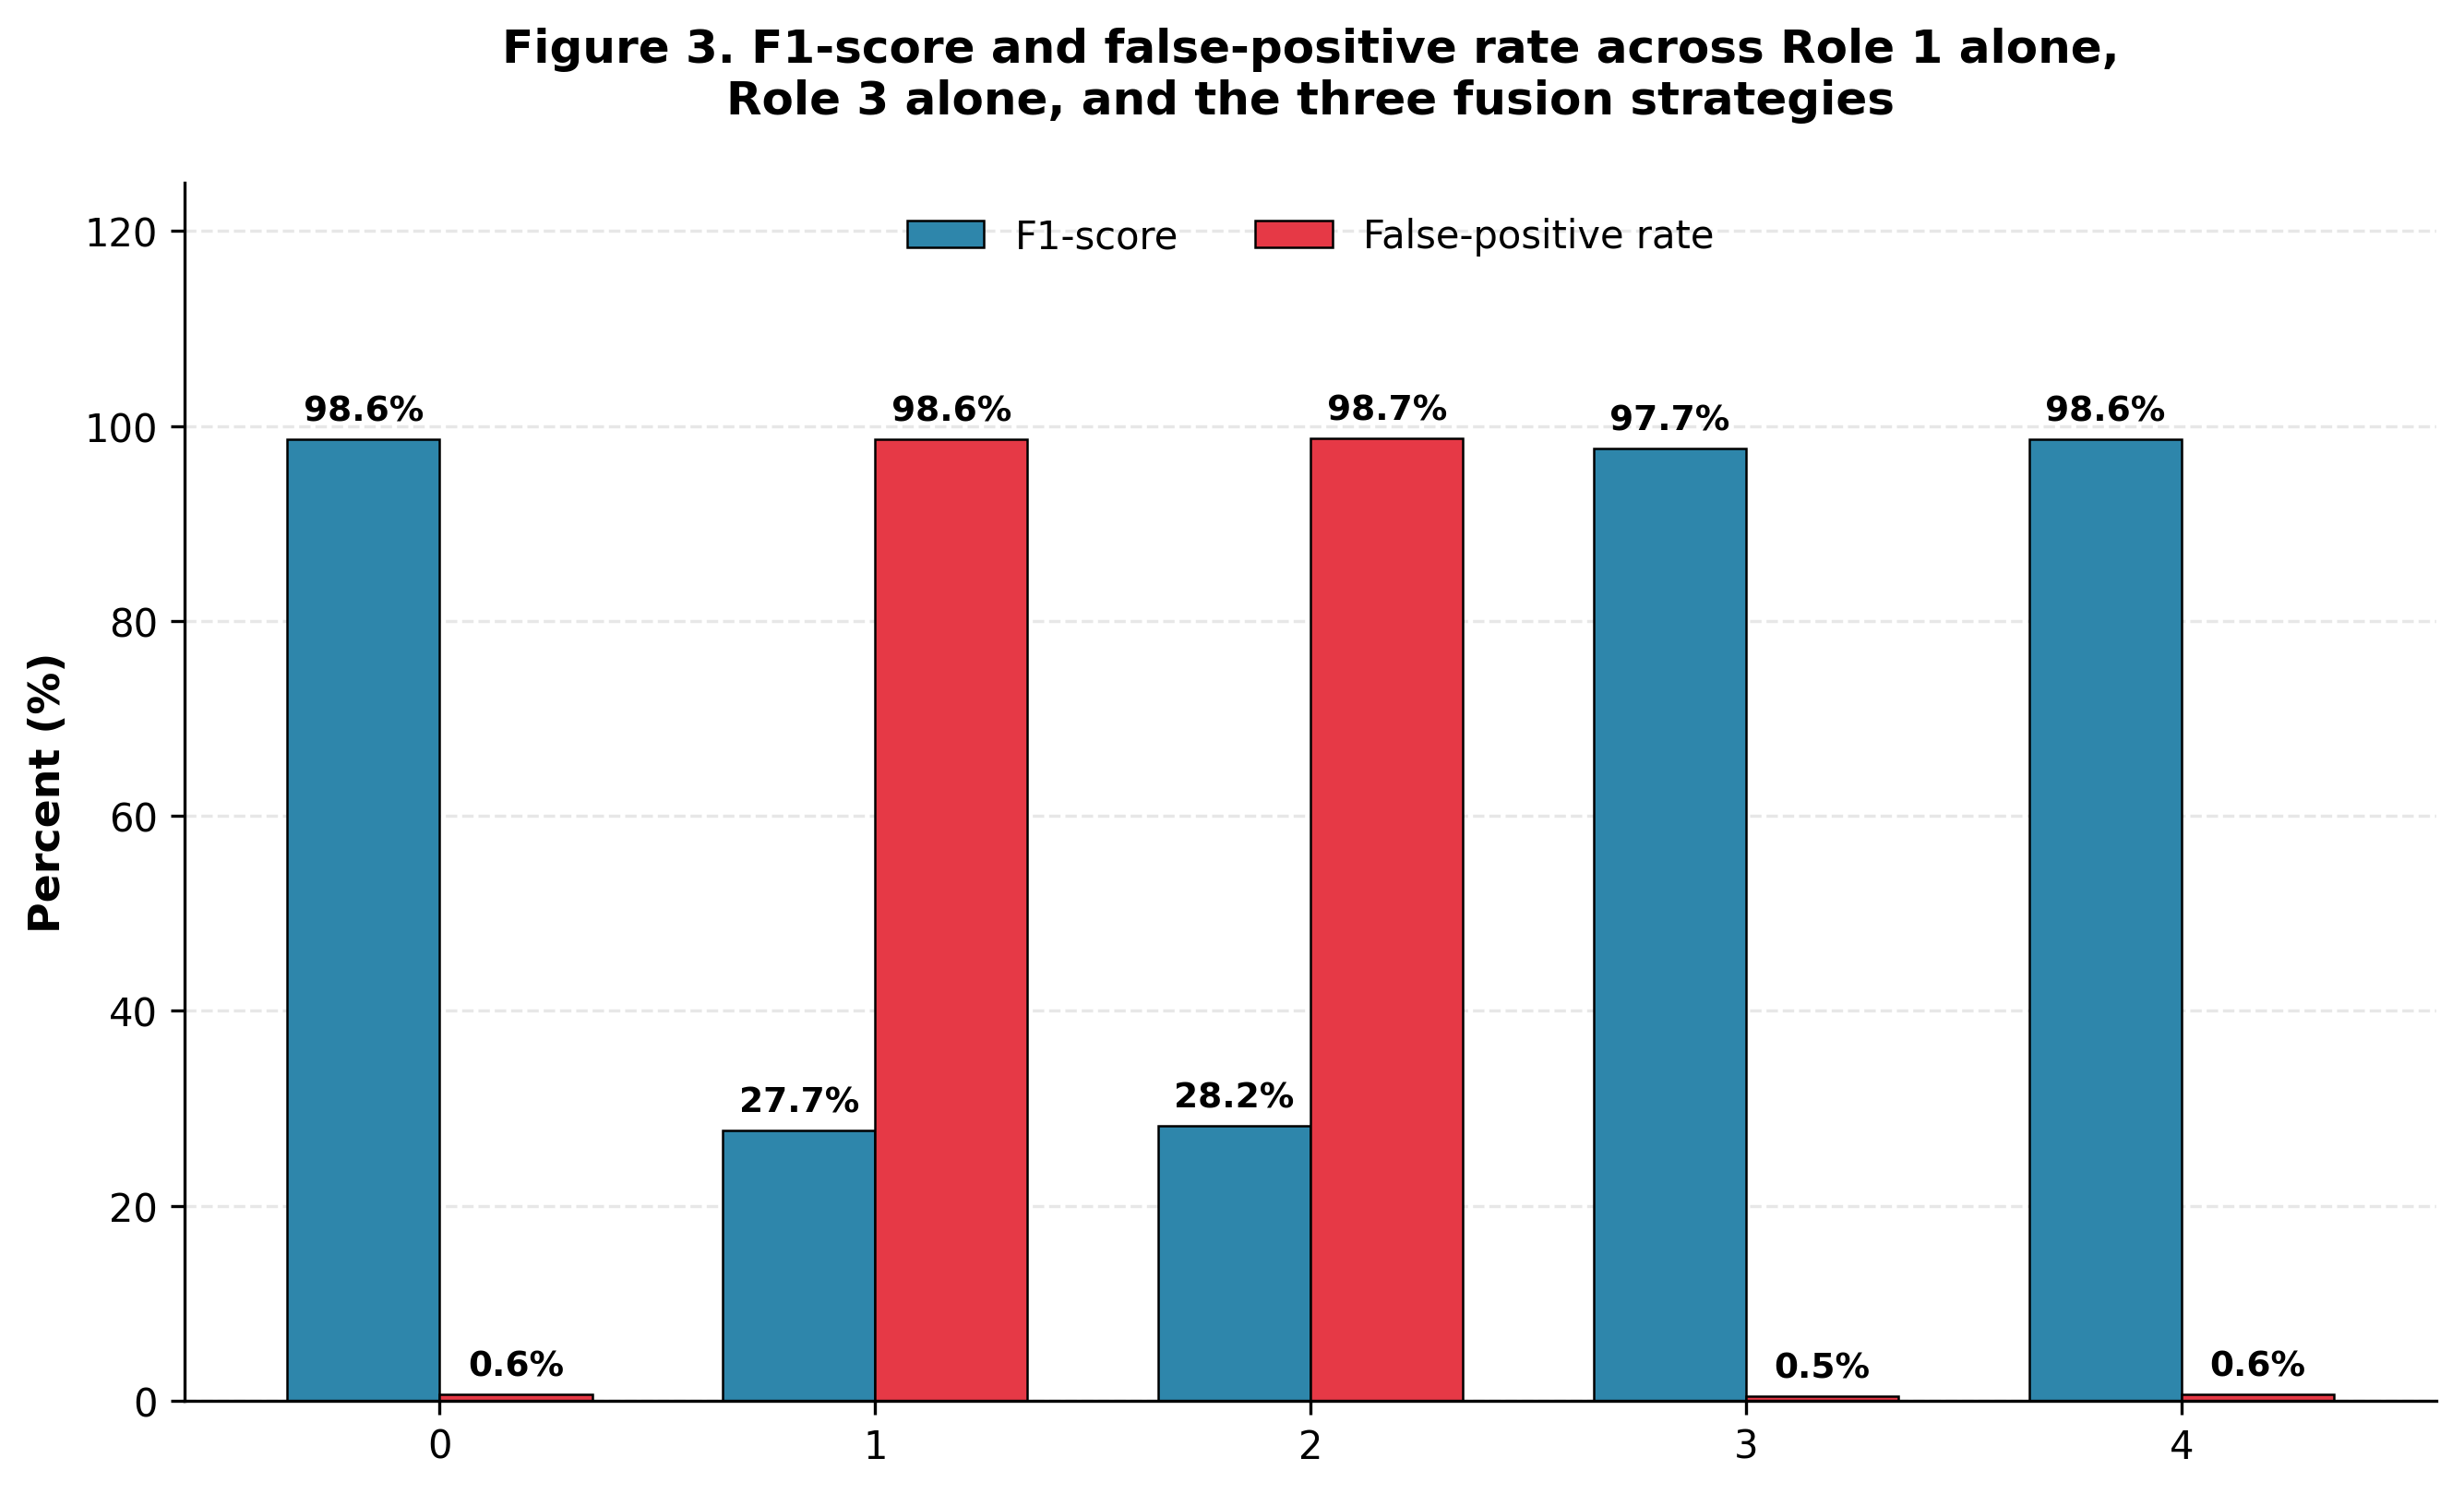

In [ ]:
"""
make_figure3_from_json.py
==========================
Loads the fusion-mode comparison results from fusion_pooled_all.json and
plots F1-score and false-positive rate across Role 1 alone, Role 3 alone,
and the three fusion strategies (OR, AND, role1_gated).
"""

import json
import matplotlib.pyplot as plt
import numpy as np

JSON_PATH = "/content/drive/MyDrive/NIDS_Output/nids_role3/data/results/fusion_pooled_all.json"

# ── Step 1: load and inspect ─────────────────────────────────────────────────
with open(JSON_PATH) as f:
    data = json.load(f)

print("Top-level keys:", list(data.keys()))
print(json.dumps(data, indent=2)[:1500])  # inspect structure before parsing

# ── Step 2: extract metrics ──────────────────────────────────────────────────
# Adjust the key names below to match whatever run_track_a.py / rescore_fusion.py
# actually calls them once you've seen the printed structure above. Common
# patterns for this kind of script are either:
#   data["role1_only"]["f1"], data["combined"]["or"]["f1"], ...
# or a flat dict keyed by method name, e.g. data["methods"]["Role1 only"]["f1"].

def get_metric(d, *candidates, default=None):
    """Try several possible key paths; return the first that exists."""
    for path in candidates:
        cur = d
        try:
            for key in path:
                cur = cur[key]
            return cur
        except (KeyError, TypeError):
            continue
    return default

methods = ["Role1 only", "Role3 only", "Combined[or]", "Combined[and]", "Combined[role1_gated]"]
labels  = ["Role 1\nalone", "Role 3\nalone", "OR\nfusion", "AND\nfusion", "role1_gated\nfusion"]

# Fallback values taken directly from the console log you shared, used only
# if the JSON's key structure doesn't match the guesses above.
fallback_f1  = {"Role1 only": 98.6, "Role3 only": 27.7, "Combined[or]": 28.2,
                "Combined[and]": 97.7, "Combined[role1_gated]": 98.6}
fallback_fpr = {"Role1 only": 0.6, "Role3 only": 98.6, "Combined[or]": 98.7,
                "Combined[and]": 0.5, "Combined[role1_gated]": 0.6}

f1_vals, fpr_vals = [], []
for m in methods:
    f1 = get_metric(data, [m, "f1"], ["results", m, "f1"], ["metrics", m, "f1"],
                     default=fallback_f1[m])
    fpr = get_metric(data, [m, "fpr"], ["results", m, "fpr"], ["metrics", m, "fpr"],
                      default=fallback_fpr[m])
    f1_vals.append(f1)
    fpr_vals.append(fpr)

print("\nF1 values used: ", dict(zip(methods, f1_vals)))
print("FPR values used:", dict(zip(methods, fpr_vals)))

# ── Step 3: plot ──────────────────────────────────────────────────────────────
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

bars_f1  = ax.bar(x - width/2, f1_vals,  width, label="F1-score",
                   color="#2E86AB", edgecolor="black", linewidth=0.6)
bars_fpr = ax.bar(x + width/2, fpr_vals, width, label="False-positive rate",
                   color="#E63946", edgecolor="black", linewidth=0.6)

for bars in (bars_f1, bars_fpr):
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylabel("Percent (%)", fontweight="bold", fontsize=11)
ax.set_ylim(0, 125)
ax.set_title("Figure 3. F1-score and false-positive rate across Role 1 alone,\n"
             "Role 3 alone, and the three fusion strategies",
             fontsize=12, fontweight="bold", pad=18)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure3_fusion_ablation.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
!python scripts/rescore_fusion.py \
    --per_window data/results/pw_wednesday.csv data/results/pw_friday.csv \
    --modes or,role1_gated,and --out data/results/fusion_pooled.json



  FUSION-MODE COMPARISON  (recomputed offline, no LLM re-run)
  windows : 991  from 2 file(s)
  suspicious counts as attack : False
  ground truth : 152 attack / 839 benign windows

  method              Acc    Prec     Rec      F1     FPR
  -------------------------------------------------------
  Role1 only         99.2    95.0   100.0    97.4     0.9
                  (tp=152 fp=8 fn=0 tn=831)
  Role3 only         15.7    14.9    95.4    25.8    98.7
                  (tp=145 fp=828 fn=7 tn=11)

  Combined[or]       16.4    15.5   100.0    26.8    98.8
                  (tp=152 fp=829 fn=0 tn=10)
                  F1 95% CI 23.4-30.1
                  McNemar vs Role1: p=0 [SIGNIFICANT]

  Combined[role1_gated]   99.2    95.0   100.0    97.4     0.9
                  (tp=152 fp=8 fn=0 tn=831)
                  F1 95% CI 95.5-99.0
                  McNemar vs Role1: p=1 [n.s.]

  Combined[and]      98.6    95.4    95.4    95.4     0.8
                  (tp=145 fp=7 fn=7 tn=832)
     

In [ ]:
# per-day fusion rescoring for Friday specifically — Wednesday+Friday pooled
# is already computed above; this is the attack-heaviest single day.
!python scripts/rescore_fusion.py \
    --per_window data/results/pw_friday.csv \
    --modes or,role1_gated,and --out data/results/fusion_friday.json


  FUSION-MODE COMPARISON  (recomputed offline, no LLM re-run)
  windows : 483  from 1 file(s)
  suspicious counts as attack : False
  ground truth : 88 attack / 395 benign windows

  method              Acc    Prec     Rec      F1     FPR
  -------------------------------------------------------
  Role1 only         98.3    91.7   100.0    95.7     2.0
                  (tp=88 fp=8 fn=0 tn=387)
  Role3 only         18.0    17.4    93.2    29.3    98.7
                  (tp=82 fp=390 fn=6 tn=5)

  Combined[or]       19.1    18.4   100.0    31.0    99.0
                  (tp=88 fp=391 fn=0 tn=4)
                  F1 95% CI 26.0-36.0
                  McNemar vs Role1: p=0 [SIGNIFICANT]

  Combined[role1_gated]   98.3    91.7   100.0    95.7     2.0
                  (tp=88 fp=8 fn=0 tn=387)
                  F1 95% CI 92.2-98.4
                  McNemar vs Role1: p=1 [n.s.]

  Combined[and]      97.3    92.1    93.2    92.7     1.8
                  (tp=82 fp=7 fn=6 tn=388)
             

In [ ]:
import json, glob
rows=[]
for f in sorted(glob.glob("data/results/trackB_*.json")):
    d=json.load(open(f)); day=f.split("_")[-1][:-5]
    a=d["ablation"]
    for m in ("role1_only","role3_only","combined"):
        x=a[m]; rows.append((day,m,x["precision"],x["recall"],x["f1_score"],x["fpr"]))
print(f"{'day':<10}{'method':<12}{'P':>7}{'R':>7}{'F1':>7}{'FPR':>7}")
for r in rows: print(f"{r[0]:<10}{r[1]:<12}{r[2]:>7.1f}{r[3]:>7.1f}{r[4]:>7.1f}{r[5]:>7.1f}")

day       method            P      R     F1    FPR
friday    role1_only     91.7  100.0   95.7    2.0
friday    role3_only     17.4   93.2   29.3   98.7
friday    combined       91.7  100.0   95.7    2.0
thursday  role1_only     97.7  100.0   98.8    0.2
thursday  role3_only      8.8  100.0   16.2   97.8
thursday  combined       97.7  100.0   98.8    0.2
tuesday   role1_only    100.0  100.0  100.0    0.0
tuesday   role3_only     25.8  100.0   41.0   99.5
tuesday   combined      100.0  100.0  100.0    0.0
wednesday role1_only    100.0  100.0  100.0    0.0
wednesday role3_only     12.6   98.4   22.3   98.7
wednesday combined      100.0  100.0  100.0    0.0


In [ ]:
import pandas as pd, glob, os

# Use the most recently written per-window CSV rather than a hardcoded
# timestamped filename, so this cell keeps working across re-runs.
latest = max(glob.glob('data/results/thesis_per_window_*.csv'), key=os.path.getmtime)
print(f'Inspecting: {latest}')
df = pd.read_csv(latest)
print(df['gt_binary'].value_counts(), '\n')
print(df['gt_family'].value_counts(), '\n')
print(df[df.gt_binary=='attack'][['window_start','gt_family','role1_pred']].to_string())


Inspecting: data/results/thesis_per_window_20260820_115325.csv
gt_binary
benign    395
attack     88
Name: count, dtype: int64 

gt_family
Benign      395
Bot          49
DDoS         21
PortScan     18
Name: count, dtype: int64 

                         window_start gt_family role1_pred
91   2017-07-07 13:31:39.599128+00:00       Bot     attack
93   2017-07-07 13:35:39.599128+00:00       Bot     attack
96   2017-07-07 13:33:39.599128+00:00       Bot     attack
97   2017-07-07 13:38:39.599128+00:00       Bot     attack
98   2017-07-07 13:37:39.599128+00:00       Bot     attack
100  2017-07-07 13:36:39.599128+00:00       Bot     attack
101  2017-07-07 13:42:39.599128+00:00       Bot     attack
103  2017-07-07 13:43:39.599128+00:00       Bot     attack
104  2017-07-07 13:40:39.599128+00:00       Bot     attack
105  2017-07-07 13:45:39.599128+00:00       Bot     attack
106  2017-07-07 13:46:39.599128+00:00       Bot     attack
107  2017-07-07 13:44:39.599128+00:00       Bot     attack
10

## Part 9 — LLM comparison: qwen2.5:1.5b vs qwen2.5:7b

Reuses the 1.5b Friday report already produced in Part 8, runs the same Friday capture through 7b, and compares them (`scripts/compare_llm_models.py`).

In [ ]:
%%bash
# ── qwen2.5:7b run (1.5b already done — reuse its report as report_1.5b.json) ──
cp $(ls -t data/results/thesis_report_*.json | head -1) data/results/report_1.5b.json 2>/dev/null

ollama pull qwen2.5:7b
# point the pipeline at 7b for this run only
sed -i 's/^  model:.*/  model: "qwen2.5:7b"/' config/settings.yaml

export NIDS_FUSION_MODE=role1_gated
mkdir -p /content/eve_friday && cp /content/eve_extracted/**/friday_eve.json /content/eve_friday/ 2>/dev/null
python main_unified.py --mode offline \
    --nids_pkl /content/drive/MyDrive/universal_nids_output.pkl \
    --eve_dir /content/eve_friday/ --flow_dir data/flow_friday/ \
    --dataset CICIDS2017 --workers 4 --db_dir /content/c_7b
cp $(ls -t data/results/thesis_report_*.json | head -1) data/results/report_7b.json

# restore 1.5b for all later runs
sed -i 's/^  model:.*/  model: "qwen2.5:1.5b"/' config/settings.yaml

python scripts/compare_llm_models.py \
    --a data/results/report_1.5b.json --a_name "qwen2.5:1.5b" \
    --b data/results/report_7b.json   --b_name "qwen2.5:7b" \
    --out data/results/llm_model_compare.json



════════════════════════════════════════════════════════════════
  UNIFIED NIDS PIPELINE
  Mode        : OFFLINE
  Ollama model: qwen2.5:7b
  Window size : 60s
  Workers     : 4
  LLM gating  : enabled
  Memory mode : streaming (SQLite, bounded RAM)
════════════════════════════════════════════════════════════════


  Loading pkl: /content/drive/MyDrive/universal_nids_output.pkl ...
  ✓ Universal ensemble pkl loaded
    Datasets  : ['CICIDS2017', 'UNSW-NB15', 'NSL-KDD']
    Classes   : ['Analysis', 'Benign', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'Fuzzers', 'Infiltration', 'PortScan', 'Shellcode', 'Web Attack']
    Sub-models: ['CICIDS2017', 'UNSW-NB15', 'NSL-KDD']
  ✓ Ollama ready (qwen2.5:7b)

  ℹ  Tip: for real parallel speedup, make sure Ollama was started with:  export OLLAMA_NUM_PARALLEL=4  before 'ollama serve'

  ✓ Role 1 ready: UniversalEnsemble
    Datasets : ['CICIDS2017', 'UNSW-NB15', 'NSL-KDD']
    Scalers  : per-dataset ✓ (3/3)
    Classes  : [np.str_('Analysis'), np.str_('

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest 
pulling 2bada8a74506:   0% ▕                  ▏ 285 KB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  24 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  51 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  52 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  60 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  60 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  61 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  61 MB/4.7 GB                  pulling manifes

## Part 10 — Baselines

Suricata-only and plain-XGBoost baselines for the thesis comparison table.

In [ ]:
%%bash
for DAY in tuesday wednesday thursday friday; do
    python scripts/baseline_suricata.py \
        --eve   /content/eve_${DAY}/${DAY}_eve.json \
        --flows data/cicflow_csv_labelled/CICIDS2017_${DAY}_flows.csv \
        --window 60 --min-alerts 1 \
        --out data/results/baseline_suricata_${DAY}.json
done

  BASELINE: SURICATA ALONE
  eve   : /content/eve_tuesday/tuesday_eve.json
    3,023,094 events, 1,828,277 alerts
  flows : data/cicflow_csv_labelled/CICIDS2017_tuesday_flows.csv
    445,909 flows
  windows: 487 x 60s  (11:53 .. 20:00)

  ── SURICATA-ALONE (vs ground truth) ──────────────────────
    windows w/ GT : 487   (attack 0, benign 487)
    tp=0  fp=487  fn=0  tn=0
    Precision   0.00%   Recall   0.00%   F1   0.00%   FPR 100.00%   Acc   0.00%
    ! no attack windows with ground truth -- recall undefined; check flow/eve alignment.

  saved: data/results/baseline_suricata_tuesday.json
  BASELINE: SURICATA ALONE
  eve   : /content/eve_wednesday/wednesday_eve.json
    4,037,063 events, 2,322,082 alerts
  flows : data/cicflow_csv_labelled/CICIDS2017_wednesday_flows.csv
    692,703 flows
  windows: 508 x 60s  (11:42 .. 20:10)

  ── SURICATA-ALONE (vs ground truth) ──────────────────────
    windows w/ GT : 508   (attack 24, benign 484)
    tp=24  fp=482  fn=0  tn=2
    Precision   4

/content/drive/MyDrive/NIDS_Output/nids_role3/scripts/baseline_suricata.py:147: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  f"({datetime.utcfromtimestamp(start):%H:%M} .. "
/content/drive/MyDrive/NIDS_Output/nids_role3/scripts/baseline_suricata.py:148: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  f"{datetime.utcfromtimestamp(end):%H:%M})")
/content/drive/MyDrive/NIDS_Output/nids_role3/scripts/baseline_suricata.py:147: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.f

In [ ]:
!python scripts/baseline_plain_xgb.py \
    --data_dir data/cic_labels/ \
    --label_col Label \
    --out data/results/baseline_plain_xgb_full.json

  BASELINE 2: PLAIN XGBoost (no prune / no select / no SMOTE)
  loading data/cic_labels/
    Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv       225,745 rows
    Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv   286,467 rows
    Friday-WorkingHours-Morning.pcap_ISCX.csv              191,033 rows
    Monday-WorkingHours.pcap_ISCX.csv                      529,918 rows
    Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv   288,602 rows
    Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv   458,968 rows
    Tuesday-WorkingHours.pcap_ISCX.csv                     445,909 rows
    Wednesday-workingHours.pcap_ISCX.csv                   692,703 rows
  total 3,119,345 rows, 85 columns
  features used : 72 (all non-constant numeric columns)
  classes       : 13  (dropped 3 with <100 rows)
  split         : 2,495,421 train / 623,856 test

  training plain XGBoost (library defaults) ...
/usr/local/lib/python3.12/dist-packages/xgboost/core.py:569: UserWarning: [12:59:04] WAR

In [ ]:
!python scripts/baseline_plain_xgb.py \
    --data_dir data/cic_labels/ \
    --label_col Label \
    --max_rows 600000 \
    --out data/results/baseline_plain_xgb_600k.json

  BASELINE 2: PLAIN XGBoost (no prune / no select / no SMOTE)
  loading data/cic_labels/
    Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv       225,745 rows
    Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv   286,467 rows
    Friday-WorkingHours-Morning.pcap_ISCX.csv              191,033 rows
    Monday-WorkingHours.pcap_ISCX.csv                      529,918 rows
    Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv   288,602 rows
    Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv   458,968 rows
    Tuesday-WorkingHours.pcap_ISCX.csv                     445,909 rows
    Wednesday-workingHours.pcap_ISCX.csv                   692,703 rows
  total 3,119,345 rows, 85 columns
  features used : 72 (all non-constant numeric columns)
  classes       : 13  (dropped 3 with <100 rows)
  subsampled to : 600,000 rows
  split         : 480,000 train / 120,000 test

  training plain XGBoost (library defaults) ...
/usr/local/lib/python3.12/dist-packages/xgboost/core.py:569

## Part 11 — Real-time performance benchmark

Stage-by-stage latency/throughput (Role 1 per-flow and batched, SHAP, decision merge, LLM, dashboard serve) — the numbers for the thesis's real-time performance section.

In [ ]:
!python /content/drive/MyDrive/NIDS_Output/nids_role3/scripts/benchmark_realtime.py \
    --universal_pkl /content/drive/MyDrive/universal_nids_output.pkl \
    --flows /content/drive/MyDrive/NIDS_Output/nids_role3/data/cicflow_csv_labelled/CICIDS2017_friday_flows.csv \
    --alerts /content/drive/MyDrive/NIDS_Output/nids_role3/data/results/alerts_friday.jsonl \
    --ollama http://localhost:11434 --model qwen2.5:1.5b \
    --n 2000 --out /content/drive/MyDrive/NIDS_Output/nids_role3/data/results/realtime_benchmark.json


  REAL-TIME PERFORMANCE BENCHMARK
  host    : Linux-6.6.122+-x86_64-with-glibc2.35
  python  : 3.12.13
  model   : /content/drive/MyDrive/universal_nids_output.pkl
  flows   : /content/drive/MyDrive/NIDS_Output/nids_role3/data/cicflow_csv_labelled/CICIDS2017_friday_flows.csv
  timing on 2,000 sample flows

  [1/6] Role 1 — per-flow (LIVE, nids_web) ...
  [2/6] Role 1 — batched (BATCH, main_unified) ...
  [3/6] Role 2 — SHAP per flow ...
        (sub-model type: WeightedHybridEnsemble)
        (SHAP on XGBClassifier)
  [4/6] Decision engine — merge ...
  [5/6] Role 3 — LLM per window ...
  [6/6] Dashboard — app.py serve ...

  LATENCY TABLE  (milliseconds)
  Stage                                  mean      p50      p95      max
  ------------------------------------------------------------------
  Role 1  per-flow  (live)            102.049  102.431  117.308  193.868
  Role 1  per-flow  (batched)           0.263    0.266    0.266    0.266
  Role 2  SHAP / flow                  18.141   

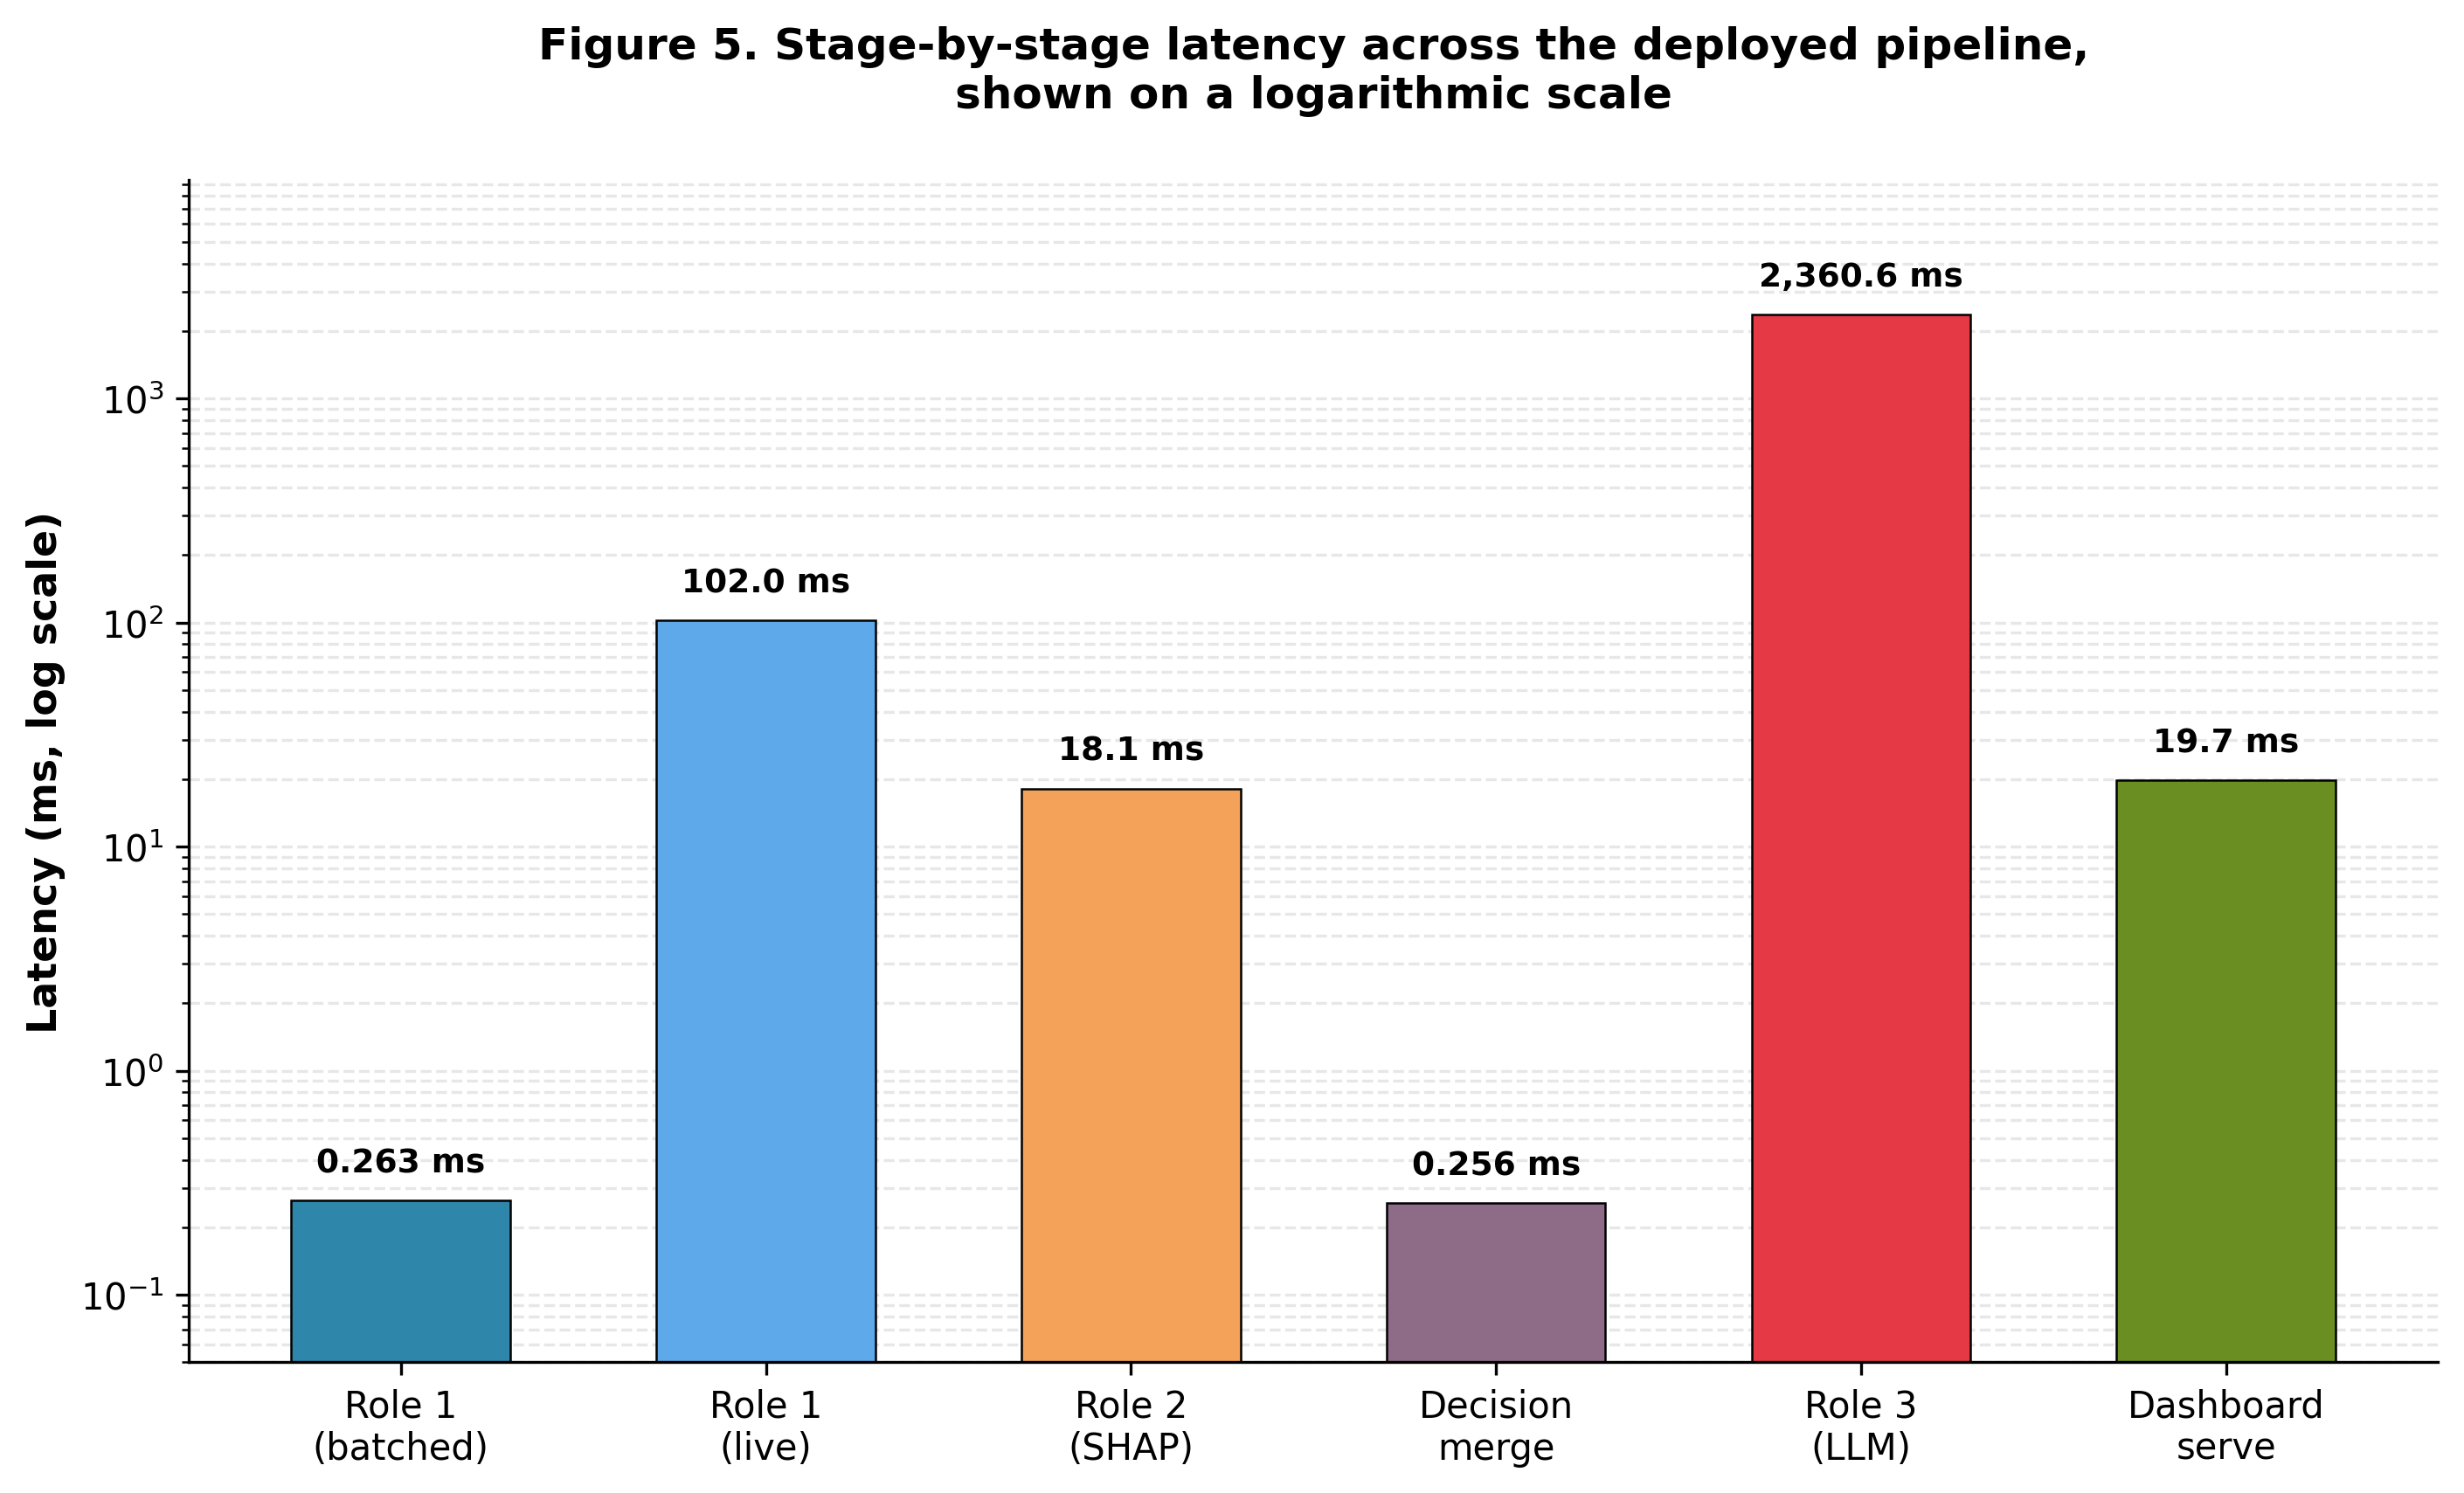

In [ ]:
import json
import matplotlib.pyplot as plt

with open("data/results/realtime_benchmark.json") as f:
    data = json.load(f)

stage_key_map = {
    "Role 1\n(batched)":   "role1_batched",
    "Role 1\n(live)":      "role1_perflow",
    "Role 2\n(SHAP)":      "role2_shap",
    "Decision\nmerge":     "decision_merge",
    "Role 3\n(LLM)":       "role3_llm",
    "Dashboard\nserve":    "dashboard_serve",
}

stages, latency_ms = [], []
for label, key in stage_key_map.items():
    stages.append(label)
    latency_ms.append(data[key]["mean_ms"])

colors = ["#2E86AB", "#5DA9E9", "#F4A259", "#8E6C88", "#E63946", "#6B8E23"]

fig, ax = plt.subplots(figsize=(9.5, 5.8), dpi=300)
bars = ax.bar(stages, latency_ms, color=colors, edgecolor="black", linewidth=0.6, width=0.6)

ax.set_yscale("log")
ax.set_ylabel("Latency (ms, log scale)", fontweight="bold", fontsize=11)
ax.set_title("Figure 5. Stage-by-stage latency across the deployed pipeline,\n"
             "shown on a logarithmic scale", fontsize=12, fontweight="bold", pad=20)

for b, v in zip(bars, latency_ms):
    label = f"{v:.3f} ms" if v < 1 else (f"{v:.1f} ms" if v < 1000 else f"{v:,.1f} ms")
    ax.annotate(label, xy=(b.get_x() + b.get_width()/2, v), xytext=(0, 6),
                textcoords="offset points", ha="center", va="bottom",
                fontsize=9, fontweight="bold")

ax.set_ylim(0.05, max(latency_ms) * 4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, which="both", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure5_stage_latency.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 12 — Result visualization

In [ ]:
import os
os.chdir('/content/drive/MyDrive/NIDS_Output/nids_role3')

!python scripts/plot_severity_distribution.py \
    --alerts data/results/pw_wednesday.csv data/results/pw_friday.csv data/results/pw_thursday.csv data/results/pw_tuesday.csv \
    --recompute \
    --out data/results/severity_distribution_chart.png

  loaded 1,964 windows from 4 file(s)
    NONE        13  (  0.7%)
    LOW          9  (  0.5%)
    MEDIUM   1,614  ( 82.2%)
    HIGH       328  ( 16.7%)

  ✓ figure: data/results/severity_distribution_chart.png
  ✓ numbers: data/results/severity_distribution_chart.json
